# Modelo de Clasificación Para Lead Scoring

Desarrollamos un sistema de **Lead Scoring** para identificar y priorizar posibles clientes en una plataforma de compraventa de caballos y accesorios ecuestres.

Cada lead recibe un nivel según su probabilidad de conversión: **Bronce**, **Plata** u **Oro**.

Dado el desbalance extremo de la clase Oro (< 0.5% del dataset), no usamos un clasificador multiclase directo. En cambio implementamos **dos clasificadores binarios en cascada** por cada dominio (caballos y productos):

- **Paso 1** — ¿Tiene intención de compra? `0 = Bronce`, `1 = Plata/Oro`  
- **Paso 2** — ¿Es de alto valor? `0 = Plata`, `1 = Oro` (solo para quienes pasaron el Paso 1)

Además, los modelos de caballos y de productos reciben **features separadas por dominio**, evitando que el comportamiento en un mercado contamine las predicciones del otro.


## Acerca de este dataset

#### Descripcion de Features


**Tabla horses_listings_limpio**
- *Horse_ID*: Identificador único del caballo.
- *Breed*: Raza del caballo (ej. Quarter Horse, Thoroughbred).
- *Name*: Nombre del caballo (se elimina — no aporta info al modelo).
- *Gender*: Género del caballo (mare, stallion, gelding).
- *In Foal*: Indica si la yegua está preñada (bool).
- *Height (hh)*: Altura en manos (hands). 1 hand = 4 pulgadas.
- *Weight (lbs)*: Peso en libras.
- *Temperament*: Temperamento del caballo en escala 1-10 (1=muy tranquilo, 10=muy nervioso).
- *Ad Created*: Fecha en que se creó el anuncio de venta.
- *Last Update*: Última vez que se actualizó el anuncio (se elimina).
- *Location*: Ubicación del vendedor.
- *Price*: Precio de venta del caballo en USD.
- *Horse Profile*: URL al perfil del caballo (se elimina — solo links).
- *Skills*: Habilidades/usos del caballo (ej. dressage, jumping, trail). Se procesan en columnas binarias.
- *Comments*: Descripción libre del caballo. Se usa solo para contar palabras.
- *Shipping*: Indica si tiene envío/transporte disponible.
- *Company Name*: Nombre de la empresa vendedora (si aplica). "unknown" = vendedor independiente.
- *Company Profile*: Perfil de la empresa (se elimina — muchos nulos y sin valor predictivo).
- *Color*: Color del caballo. Se agrupa en categorías (bay, chestnut, grey, etc.).
- *Registry*: Si tiene registro de pedigree. Se convierte a binario (has_registry).
- *Has_Face_Markings*: Si tiene marcas en la cara (bool).
- *Foal Date*: Fecha de nacimiento del caballo, usada para calcular la edad.

**Tabla horses_sessions_info**
- *user_id*: Identificador único del usuario.
- *user_session*: ID de sesión (se elimina — no aporta info útil).
- *horse_id*: ID del caballo visualizado/agregado al carrito/comprado.
- *event_type*: Tipo de evento: `view`, `cart`, `purchase`.
- *event_time*: Timestamp del evento (se elimina — solo tiene una fecha registrada).

**Tabla products_listings_limpio**
- *Item_ID*: Identificador único del producto.
- *Name*: Nombre del producto (se elimina).
- *Stock*: Stock disponible del producto.
- *Description*: Descripción del producto. Se extrae: marca, categoría, origen, y atributos (waterproof, leather, etc.).
- *Price*: Precio del producto en USD.
- *Images*: URLs de imágenes (se elimina).
- *URL*: URL del producto (se elimina).

**Tabla prods_sessions_info**
- *user_id*: Identificador único del usuario.
- *user_session*: ID de sesión (se elimina).
- *item_id*: ID del producto con el que se interactuó.
- *event_type*: Tipo de evento: `view`, `cart`, `purchase`.
- *event_time*: Timestamp del evento (se elimina).

**Tabla users_info**
- *user_id*: Identificador único del usuario.
- *name*: Nombre del usuario (se elimina — PII).
- *gender*: Género del usuario.
- *country*: País de origen. Se agrupa en regiones geográficas.
- *city*: Ciudad (se elimina — demasiadas categorías sin valor predictivo).
- *addres*: Dirección (se elimina — PII).
- *credit_card_info*: Info de tarjeta. Se extrae solo el emisor (VISA, Mastercard, etc.).
- *email*: Email del usuario. Se extrae solo el dominio (gmail, hotmail, yahoo, outlook).
- *phone_number*: Teléfono (se elimina — PII).
- *job_info*: Diccionario con info laboral. Se extrae el título y se convierte a `prestige_score`.
- *device_type*: Tipo de dispositivo usado (mobile, desktop, tablet).
- *traffic_source*: Fuente de tráfico (organic, paid, referral, social, email).
- *first_seen*: Fecha en que el usuario fue visto por primera vez en la plataforma.

#### Inspección Inicial

Primero pasemos a hacer un Análisis Exploratorio de Datos breve para comprobar nulos, duplicados, conversiones de tipo, y hacer un poco de Feature Engineering para agregar columnas necesarias.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
root = "../../data/clean/"

In [3]:
users = pd.read_parquet(root + "users_info.parquet")
users.head(3)

,user_id,name,gender,country,city,addres,credit_card_info,email,phone_number,job_info,device_type,traffic_source,first_seen
0,023b759c-a4c0-4d6f-8cf9-6206706ed2c6,Stacey Knox,female,Egypt,Lake Stephenhaven,47989 Bell Court,Maestro\nStacey Knox\n563238018813 08/29\nCVV:...,stacey.knox@yahoo.com,+1-999-753-4836x477,"{'company': 'Gonzalez-Lopez', 'suffix': 'LLC',...",mobile,paid,2018-09-03
1,d51cda4c-2a64-4947-8662-fe40211da5d8,丽华 陈,female,China,超县,彭街o座,Visa\n丽华 陈\n4115488645629081 01/28\nCVV2: 293\...,丽华.陈@hotmail.com,18504445793,"{'company': '创汇传媒有限公司', 'suffix': '科技有限公司', 't...",desktop,organic,2019-03-18
2,9e9f7e19-48dc-475d-8041-dceeb3c83f6e,สุพัตร แก้วอยู่,female,Thailand,สมุทรสาคร,821 ถ.พงศ์ฉบับนภา,Maestro\nสุพัตร แก้วอยู่\n676375172845 03/34\n...,สุพัตร.แก้วอยู่@icloud.com,+662 840 8282,{'company': 'บริษัท โพธิสัตย์อุตสาหกรรม จำกัด'...,mobile,referral,2018-06-28


In [4]:
horses = pd.read_parquet(root + "horses_listings_limpio.parquet")
horses.head(3)

,Horse_ID,Name,Breed,Gender,In Foal,Height (hh),Weight (lbs),Color,Markings,Registry,...,Location,Price,Horse Profile,Skills,Comments,Shipping,Company Name,Company Profile,Age,Has_Face_Markings
0,1594152,sankari,gypsy vanner,mare,no,13.30,1000.0,smokey black,smoky cream,ghra,...,"sarasota, fl",20000.0,https://www.equinenow.com/horse-ad-1594152,unknown,looking for a quality double dilute look no fu...,can arrange shipping.,find your dream horse consignments,https://www.equinenow.com/farm/find-your-dream...,9.8,0
1,1605089,black friesian colt,friesian,colt,no,15.65,1200.0,black,unknown,fhana,...,"donna, tx",15000.0,https://www.equinenow.com/horse-ad-1605089,unknown,beautiful 1 yr old friesians for sale fhana re...,friesian breeding.,coronado friesians,unknown,5.4,0
2,1548490,seneca,gypsy vanner,stallion,no,16.10,1200.0,piebald,unknown,ghra,...,"lockwood, ca",30000.0,https://www.equinenow.com/horse-ad-1548490,"athletic, breeding, cross, dressage, english p...",one-of-a-kind registered gypsy vanner stallion...,the world's most ambitious crossbreeding progr...,making pegasus,https://www.equinenow.com/farm/making-pegasus.htm,11.7,0


In [5]:
products = pd.read_parquet(root + "products_listing_limpio.parquet")
products.head(3)

,Item_ID,Name,Stock,Description,Price,Images,URL,Category
0,36749,samshield® xj helmet,1,the samshield® xj helmet has an outer shell ma...,915.00,https://www.doversaddlery.com/cdn/shop/files/0...,https://www.doversaddlery.com/collections/hors...,horse riding apparel
1,15892,hdr pro concept close contact,2,the hdr pro concept close contact saddle offer...,1139.99,https://www.doversaddlery.com/cdn/shop/files/0...,https://www.doversaddlery.com/collections/hors...,horse tack equipment
2,360068,one k™ defender celestial helmet,0,the one k™ defender celestial helmet** adds an...,500.95,https://www.doversaddlery.com/cdn/shop/files/0...,https://www.doversaddlery.com/collections/helm...,helmets protective gear


In [6]:
prodsInfo = pd.read_parquet(root + "prods_sessions_info.parquet")
prodsInfo.head(3)

,user_id,user_session,item_id,event_type,event_time
0,4c3ce839-2628-4399-9448-d31fb1a02004,a37bfb5b-8a32-4e64-bba2-1e9e4f600b88,220491,view,2020-04-01 02:37:24 UTC
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,c13278a7-b518-4053-9145-f99665caf677,150689,view,2020-04-01 00:19:24 UTC
2,4455da1e-b286-40fe-9761-0daf35dbc970,c949a06d-1c14-42ca-8b49-98a2060c2150,401850,view,2020-04-01 03:27:48 UTC


In [7]:
horsesInfo = pd.read_parquet(root + "horses_sessions_info.parquet")
horsesInfo.head(3)

,user_id,user_session,horse_id,event_type,event_time
0,4c3ce839-2628-4399-9448-d31fb1a02004,a37bfb5b-8a32-4e64-bba2-1e9e4f600b88,1601769,view,2020-04-01 02:37:24 UTC
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,c13278a7-b518-4053-9145-f99665caf677,1607243,view,2020-04-01 00:19:24 UTC
2,4455da1e-b286-40fe-9761-0daf35dbc970,c949a06d-1c14-42ca-8b49-98a2060c2150,1582377,view,2020-04-01 03:27:48 UTC


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   user_id           200000 non-null  object
 1   name              200000 non-null  object
 2   gender            200000 non-null  object
 3   country           200000 non-null  object
 4   city              200000 non-null  object
 5   addres            200000 non-null  object
 6   credit_card_info  200000 non-null  object
 7   email             200000 non-null  object
 8   phone_number      200000 non-null  object
 9   job_info          200000 non-null  object
 10  device_type       200000 non-null  object
 11  traffic_source    200000 non-null  object
 12  first_seen        200000 non-null  object
dtypes: object(13)
memory usage: 19.8+ MB


La columna `fist_seen` tiene que ser del tipo ***datetime64[us]***.

In [9]:
horses.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Horse_ID           780 non-null    object        
 1   Name               780 non-null    object        
 2   Breed              780 non-null    object        
 3   Gender             780 non-null    object        
 4   In Foal            780 non-null    object        
 5   Height (hh)        780 non-null    float64       
 6   Weight (lbs)       780 non-null    float64       
 7   Color              780 non-null    object        
 8   Markings           780 non-null    object        
 9   Registry           780 non-null    object        
 10  Temperament        780 non-null    string        
 11  Ad Created         780 non-null    datetime64[ns]
 12  Last Update        780 non-null    datetime64[ns]
 13  Location           780 non-null    object        
 14  Price     

In [10]:
horsesInfo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 5 columns):
 #   Column        Non-Null Count    Dtype 
---  ------        --------------    ----- 
 0   user_id       1000000 non-null  object
 1   user_session  999994 non-null   object
 2   horse_id      1000000 non-null  object
 3   event_type    1000000 non-null  object
 4   event_time    1000000 non-null  object
dtypes: object(5)
memory usage: 38.1+ MB


La columna `event_time` tiene que ser del tipo ***datetime64[us]***.

In [11]:
prodsInfo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 5 columns):
 #   Column        Non-Null Count    Dtype 
---  ------        --------------    ----- 
 0   user_id       1000000 non-null  object
 1   user_session  999994 non-null   object
 2   item_id       1000000 non-null  object
 3   event_type    1000000 non-null  object
 4   event_time    1000000 non-null  object
dtypes: object(5)
memory usage: 38.1+ MB


La columna `event_time` tiene que ser del tipo ***datetime64[us]***.

In [12]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232 entries, 0 to 231
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Item_ID      232 non-null    object 
 1   Name         232 non-null    object 
 2   Stock        232 non-null    int32  
 3   Description  232 non-null    object 
 4   Price        232 non-null    float64
 5   Images       232 non-null    object 
 6   URL          232 non-null    object 
 7   Category     232 non-null    object 
dtypes: float64(1), int32(1), object(6)
memory usage: 13.7+ KB


Tenemos que eliminar las columna de imagen y de URL porque no nos aporta información relevante.

### Detección y tratamiento de nulos

In [13]:
horsesInfo.isna().sum()[horsesInfo.isna().sum() > 0]

user_session    6
dtype: int64

In [14]:
horses.isna().sum()[horses.isna().sum() > 0]

Series([], dtype: int64)

In [15]:
products.isna().sum()[products.isna().sum() > 0]

Series([], dtype: int64)

In [16]:
prodsInfo.isna().sum()[prodsInfo.isna().sum() > 0]

user_session    6
dtype: int64

In [17]:
users.isna().sum()[users.isna().sum() > 0]

Series([], dtype: int64)

Podemos ver nulos en las siguientes columnas:
- *user_session* de las tablas `horsesInfo` Y `user_session`.

Pasemos a ver que porcentaje del total de valores es nulo en esas columnas.

In [18]:
horsesInfo.isna().sum()[horsesInfo.isna().sum() > 0]/horsesInfo.shape[0]

user_session    0.000006
dtype: float64

Podemos eliminar esos nulos de usuarios porque es ínfima la cantidad.

In [19]:
horsesInfo = horsesInfo.dropna()

In [20]:
prodsInfo.isna().sum()[prodsInfo.isna().sum() > 0]/prodsInfo.shape[0]

user_session    0.000006
dtype: float64

También podemos eliminar estos nulos de prodsInfo porque es ínfima la cantidad.

In [21]:
prodsInfo = prodsInfo.dropna()

In [22]:
horses["Company Profile"][0]

'https://www.equinenow.com/farm/find-your-dream-horse.htm'

La columna ***Company Profile*** la descartamos porque este columna no nos aporta información útil.

Ahora pasemos a ver  si hay valores duplicados

### Valores duplicados

In [23]:
print("La tabla horses tiene {} valores duplicados".format(horses.duplicated().sum()))
print("La tabla horsesInfo tiene {} valores duplicados".format(horsesInfo.duplicated().sum()))
print("La tabla products tiene {} valores duplicados".format(products.duplicated().sum()))
print("La tabla prodsInfo tiene {} valores duplicados".format(prodsInfo.duplicated().sum()))
print("La tabla users tiene {} valores duplicados".format(users.drop("job_info",axis=1).duplicated().sum()))

La tabla horses tiene 0 valores duplicados
La tabla horsesInfo tiene 534 valores duplicados
La tabla products tiene 0 valores duplicados
La tabla prodsInfo tiene 153 valores duplicados
La tabla users tiene 0 valores duplicados


In [24]:
horsesInfo = horsesInfo.drop_duplicates()
prodsInfo = prodsInfo.drop_duplicates()

In [25]:
print("La tabla horsesInfo tiene {} valores duplicados".format(horsesInfo.duplicated().sum()))
print("La tabla prodsInfo tiene {} valores duplicados".format(prodsInfo.duplicated().sum()))

La tabla horsesInfo tiene 0 valores duplicados
La tabla prodsInfo tiene 0 valores duplicados


### Conversión de tipos

Antes notamos que la columna *event_time* en `horsesInfo` y `prodsInfo` figura que posee strings, vamos a convertirla a tipo datetime, quedandonos con el años, mes y día.

In [26]:
prodsInfo["event_time"] = pd.to_datetime(prodsInfo["event_time"]).dt.date

In [27]:
prodsInfo["event_time"].value_counts()

event_time
2020-04-01    999841
Name: count, dtype: int64

In [28]:
horsesInfo["event_time"] = pd.to_datetime(horsesInfo["event_time"]).dt.date

In [29]:
horsesInfo.dtypes

user_id         object
user_session    object
horse_id        object
event_type      object
event_time      object
dtype: object

In [30]:
horsesInfo["event_time"].value_counts()

event_time
2020-04-01    999460
Name: count, dtype: int64

La columna `Temperament` en la tabla `horses`, contiene valores *str* cuando deberían ser enteros.

In [31]:
horses["Temperament"] = pd.to_numeric(horses['Temperament'], errors='coerce').astype('Int64')

In [32]:
horses["Temperament"].value_counts()

Temperament
1     285
5     227
2     124
3      75
4      45
6      17
7       6
10      1
Name: count, dtype: Int64

In [33]:
horses.dtypes

Horse_ID                     object
Name                         object
Breed                        object
Gender                       object
In Foal                      object
Height (hh)                 float64
Weight (lbs)                float64
Color                        object
Markings                     object
Registry                     object
Temperament                   Int64
Ad Created           datetime64[ns]
Last Update          datetime64[ns]
Location                     object
Price                       float64
Horse Profile                object
Skills                       object
Comments                     object
Shipping                     object
Company Name                 object
Company Profile              object
Age                         float64
Has_Face_Markings             int32
dtype: object

### Feature Engineering and Selection

#### Tabla `users`

In [34]:
users.columns

Index(['user_id', 'name', 'gender', 'country', 'city', 'addres',
       'credit_card_info', 'email', 'phone_number', 'job_info', 'device_type',
       'traffic_source', 'first_seen'],
      dtype='object')

De la tabla `users` podemos eliminar las columnas *addres*, *phone_number*  y *name*.
También podemos agregar una columna que tenga el dominio del correo, y otra que tenga el emisor de la tarjeta.

In [35]:
users["job_info"][0]

{'company': 'Gonzalez-Lopez',
 'suffix': 'LLC',
 'title': 'Grand Prix show jumping rider'}

Podemos ver diccionarios en cada fila de la columna *job_info*, donde nos puede interesar el titulo del usuario para ver si extraemos diferentes posiciones laborales, ya sea, desde empleados hasta CEOs.

In [36]:
titles = []
for job in users["job_info"]:
    titles.append(job["title"])

In [37]:
titles[:8]

['Grand Prix show jumping rider',
 'Horse show operations director',
 'International dressage rider',
 'Olympic-level equestrian',
 'Professional show jumper',
 'Equestrian portfolio manager',
 'Luxury horse owner',
 'Family office equestrian investor']

Ahora tenemos que ver como extraer palabras clave como "founder", "rider", "specialist", etc; de los textos y de esa manera obtenemos la posición laboral.    

Luego con todas las posiciones laborales vamos a crear una calificación en base a que tan importante es y con cuanto dinero suelen contar personas con posiciones similares.   
  
Por ejemplo, un inversor es más importante que un veterinario para nuestro modelo, porque el inversor es el que más posibilidades tiene de pagar suficiente dinero por un caballo.

In [38]:
def get_prestige_score(job):
    job = str(job).lower()
    # Definimos pesos por palabras clave
    if any(x in job for x in ["investor", "family office", "high-net-worth", "bloodstock"]):
        return 10
    elif any(x in job for x in ["olympic", "fei", "grand prix", "national team"]):
        return 9
    elif any(x in job for x in ["owner", "director", "founder", "ceo", "manager"]):
        return 7
    elif any(x in job for x in ["veterinarian", "vet", "physiotherapist", "specialist"]):
        return 5
    return 3 # Valor por defecto para otros roles operativos

In [39]:
jobs=[]
for job in titles:
    jobs.append(get_prestige_score(job))

In [40]:
jobs[:5]

[9, 7, 3, 9, 3]

In [41]:
users["prestige_score"] = jobs

In [42]:
users["prestige_score"].value_counts()

prestige_score
7     86704
3     75696
5     14701
10    14656
9      8243
Name: count, dtype: int64

In [43]:
users["first_seen"].value_counts()

first_seen
2018-02-03    144
2019-02-20    141
2018-12-06    139
2016-06-07    138
2017-01-16    137
             ... 
2017-02-26     83
2016-04-15     83
2016-03-29     83
2015-11-22     80
2015-06-02     80
Name: count, Length: 1799, dtype: int64

La columna *first_seen* la voy a usar para poder crear otra columna de antiguedad del usuario. Esta acción la vamos a hacer luego con `HorsesInfo` porque vamos a necesitar ver la última acción que realizó el usuario.

In [44]:
users["first_seen"] = pd.to_datetime(users["first_seen"], utc=False, errors="coerce")
if users["first_seen"].dt.tz is not None:
    users["first_seen"] = users["first_seen"].dt.tz_localize(None)

Pasemos a crear nuevas columnas a partir de las columnas *email* y *credit_card_info*

In [45]:
users["email"].str.split("@").str[1].str.split(".").str[0].value_counts()

email
gmail       53477
hotmail     50702
yahoo       50599
outlook      1898
email        1657
            ...  
tim           121
alice         120
tin           115
noos          115
virgilio      110
Name: count, Length: 107, dtype: int64

Podemos ver muchos dominios extraños/raros, nos quedaremos con los dominios de "gmail", "hotmail", "yahoo" y "outlook", los demás serán catalogados como "strange".

In [46]:
mails_providers = ["gmail", "hotmail", "yahoo", "outlook"]
domains = []
for provider in users["email"].str.split("@").str[1].str.split(".").str[0]:
    if provider in mails_providers:
        domains.append(provider)
    else:
        domains.append("other/strange")

In [47]:
domains[:8]

['yahoo',
 'hotmail',
 'other/strange',
 'gmail',
 'yahoo',
 'hotmail',
 'other/strange',
 'gmail']

In [48]:
users["domain"] = domains

Ahora nos falta obtener el emisor de cada tarjeta.

In [49]:
users["credit_card_info"]

0         Maestro\nStacey Knox\n563238018813 08/29\nCVV:...
1         Visa\n丽华 陈\n4115488645629081 01/28\nCVV2: 293\...
2         Maestro\nสุพัตร แก้วอยู่\n676375172845 03/34\n...
3         VISA 19 digit\nபக்தவச்சலம் அகிலா\n462657594058...
4         VISA 13 digit\n麗娟 林\n4107759000978 05/31\nCVC:...
                                ...                        
199995    VISA 16 digit\n채원 윤\n4800342032868564 02/27\nC...
199996    کشاورزی\nپریا رستمی\n6037704756771433 04/27\nC...
199997    VISA 13 digit\nSvätopluk Rybníčeková\n41334115...
199998    JCB 16 digit\nநளினி மகஷேவரி\n3589235053956640 ...
199999    JCB 15 digit\nSofia Johansson\n180072892366114...
Name: credit_card_info, Length: 200000, dtype: object

In [50]:
users["credit_card_info"].str.split("\n").str[0].value_counts()

credit_card_info
VISA 16 digit                  31424
JCB 16 digit                   31096
Mastercard                     18603
Maestro                        17573
American Express               16051
Diners Club / Carte Blanche    15795
VISA 19 digit                  15778
Discover                       15556
JCB 15 digit                   15449
VISA 13 digit                  15371
Visa                            2621
UnionPay                         840
ПРОСТІР                          605
МИР                              424
Union Pay                        382
مهراقتصاد                        111
ملی                               99
رفاه                              94
انصار                             92
تجارت                             91
ملت                               91
کار آفرین                         91
سپه                               90
پاسارگاد                          90
ملل                               90
تات                               88
توسعه                

In [51]:
def clean_issuer(text):
    text = str(text).split("\n")[0].upper()
    
    # Unificamos variantes de marcas globales
    if "VISA" in text: return "VISA"
    if "JCB" in text: return "JCB"
    if "MASTERCARD" in text: return "MASTERCARD"
    if "MAESTRO" in text: return "MAESTRO"
    if "AMERICAN EXPRESS" in text or "AMEX" in text: return "AMERICAN EXPRESS"
    if "DINERS" in text or "CARTE BLANCHE" in text: return "DINERS CLUB"
    if "DISCOVER" in text: return "DISCOVER"
    if "UNION" in text: return "UNIONPAY"
    
    # Si detecta caracteres árabes/persas, agrupar como Red Local Irán
    if any("\u0600" <= char <= "\u06FF" for char in text):
        return "IRANIAN LOCAL BANK"
    
    # Dejamos el nombre tal cual para los que están en otros alfabetos 
    # o limpiamos espacios extras
    return text.split(" ")[0].strip()

In [52]:
users["card_issuer"] = users["credit_card_info"].apply(clean_issuer)

In [53]:
users["card_issuer"].value_counts()

card_issuer
VISA                  65194
JCB                   46545
MASTERCARD            18603
MAESTRO               17573
AMERICAN EXPRESS      16051
DINERS CLUB           15795
DISCOVER              15556
IRANIAN LOCAL BANK     2432
UNIONPAY               1222
ПРОСТІР                 605
МИР                     424
Name: count, dtype: int64

In [54]:
users["card_issuer"].nunique()

11

In [55]:
users["country"].nunique()

69

In [56]:
users["country"].value_counts(normalize=True)

country
India            0.060910
Switzerland      0.036145
Nigeria          0.035610
Luxembourg       0.024745
Indonesia        0.024490
                   ...   
Armenia          0.011675
Viet Nam         0.011655
Liechtenstein    0.011555
Bangladesh       0.011505
Croatia          0.011485
Name: proportion, Length: 69, dtype: float64

Vamos a agrupar los paises por región, vamos a pasar de 69 categorías a cómo mucho 7-8 categorías.

In [57]:
def map_to_region(country):
    country = str(country).strip()
    
    # Diccionario de mapeo basado en tu lista
    mapping = {
        # North America
        "United States": "North_America", "Canada": "North_America", "Mexico": "North_America",
        
        # South America
        "Chile": "South_America", "Argentina": "South_America", "Brazil": "South_America", 
        "Colombia": "South_America",
        
        # Europe
        "Czechia": "Europe", "Poland": "Europe", "Estonia": "Europe", "Austria": "Europe",
        "Hungary": "Europe", "Spain": "Europe", "Lithuania": "Europe", "United Kingdom": "Europe",
        "Ireland": "Europe", "Switzerland": "Europe", "Iceland": "Europe", "Belgium": "Europe",
        "Bosnia and Herzegovina": "Europe", "Latvia": "Europe", "Slovenia": "Europe", 
        "Bulgaria": "Europe", "Italy": "Europe", "Ukraine": "Europe", "Germany": "Europe",
        "Finland": "Europe", "Romania": "Europe", "Slovakia": "Europe", "Portugal": "Europe",
        "Denmark": "Europe", "Greece": "Europe", "Malta": "Europe", "Croatia": "Europe",
        "Luxembourg": "Europe", "Sweden": "Europe", "Liechtenstein": "Europe", "Cyprus": "Europe",
        "France": "Europe", "Norway": "Europe", "Albania": "Europe", "Netherlands": "Europe",
        
        # Asia & Middle East
        "Korea, Republic of": "Asia_ME", "Indonesia": "Asia_ME", "Uzbekistan": "Asia_ME",
        "Israel": "Asia_ME", "Nepal": "Asia_ME", "Thailand": "Asia_ME", "India": "Asia_ME",
        "Georgia": "Asia_ME", "Russian Federation": "Asia_ME", "Taiwan, Province of China": "Asia_ME",
        "Armenia": "Asia_ME", "Jordan": "Asia_ME", "Saudi Arabia": "Asia_ME", "Bahrain": "Asia_ME",
        "United Arab Emirates": "Asia_ME", "China": "Asia_ME", "Viet Nam": "Asia_ME",
        "Bangladesh": "Asia_ME", "Azerbaijan": "Asia_ME", "Japan": "Asia_ME", 
        "Iran, Islamic Republic of": "Asia_ME", "Türkiye": "Asia_ME",
        
        # Africa
        "Nigeria": "Africa", "South Africa": "Africa", "Egypt": "Africa", "Algeria": "Africa",
        
        # Oceania
        "New Zealand": "Oceania", "Australia": "Oceania"
    }
    
    return mapping.get(country, "Other_Regions")

In [58]:
users["region"] = users["country"].apply(map_to_region)

In [59]:
users["region"].value_counts()    

region
Europe           94395
Asia_ME          67424
Africa           14375
South_America     9534
North_America     9487
Oceania           4785
Name: count, dtype: int64

In [60]:
users["city"].nunique()

78770

In [61]:
users["city"].value_counts(normalize=True).head(20)

city
Naftalan             0.001175
Naxçıvan             0.001165
Mingəçevir           0.001165
Sumqayıt             0.001150
Bakı                 0.001145
Şirvan               0.001120
Yevlax               0.001115
Şəki                 0.001105
Lənkəran             0.001090
Xankəndi             0.001080
Gəncə                0.001035
கோயம்புத்தூர்        0.001005
திருப்பூர்           0.000980
வேலூர்               0.000945
மதுரை                0.000935
திருச்சிராப்பள்ளி    0.000920
திருநெல்வேலி         0.000845
திருவண்ணாமலை         0.000835
La Rioja             0.000675
Córdoba              0.000645
Name: proportion, dtype: float64

Hay demasiadas categorías en la columna *city* y no hay ninguna que destaque sobre otra, por lo que, decidimos eliminarla.

In [62]:
users = users.drop(columns=["name", "addres", "phone_number", "email", "credit_card_info", "job_info", "city", "country"])

In [63]:
users.columns

Index(['user_id', 'gender', 'device_type', 'traffic_source', 'first_seen',
       'prestige_score', 'domain', 'card_issuer', 'region'],
      dtype='object')

#### Tabla `horses`

In [64]:
horses.columns

Index(['Horse_ID', 'Name', 'Breed', 'Gender', 'In Foal', 'Height (hh)',
       'Weight (lbs)', 'Color', 'Markings', 'Registry', 'Temperament',
       'Ad Created', 'Last Update', 'Location', 'Price', 'Horse Profile',
       'Skills', 'Comments', 'Shipping', 'Company Name', 'Company Profile',
       'Age', 'Has_Face_Markings'],
      dtype='object')

De la tabla `horses` podemos eliminar las columnas *Name*, *Last Update* porque sabemos que no nos interesa la información que aporta.    

Veamos las siguientes columnas para decidir si nos sirven: *Company Name*, *Company Profile*, *Color*, *Skills*, *Comments*, *Shipping*, *Horse Profile*, *Registry* y *Markings*.

In [65]:
horses["Company Name"].value_counts()

Company Name
unknown                     221
horse of my dreams          106
iberian horses               93
caballos jesus herrera       71
adams horse and mule co.     12
                           ... 
cuttin style horses           1
harmony heights farm          1
i diamond ranch               1
coudelaria estelar            1
ds stables                    1
Name: count, Length: 163, dtype: int64

In [66]:
horses["Company Name"].value_counts()["unknown"]/horses.shape[0]

np.float64(0.2833333333333333)

Cómo los nulos pueden indicar que el vendedor no es una compañia grande, sino alguien independiente o una compañia muy pequeña, vamos a crear una nueva columna llamada *is_pro_seller*, donde si hay nombre es un 1 y si hay un desconocido es un 0.

In [67]:
horses["is_pro_seller"] = horses["Company Name"].apply(lambda x: 0 if x == "unknown" else 1)

In [68]:
horses["is_pro_seller"].value_counts()

is_pro_seller
1    559
0    221
Name: count, dtype: int64

In [69]:
horses["Company Profile"].value_counts()

Company Profile
unknown                                                         260
https://www.equinenow.com/farm-id-594917                         93
https://www.equinenow.com/farm/yeguada_herrera.htm               71
https://www.equinenow.com/farm/diamond_j.htm                     17
https://www.equinenow.com/farm/horse-of-my-dreams-259209.htm     16
                                                               ... 
https://www.equinenow.com/farm/jmb-ranch.htm                      1
https://www.equinenow.com/farm/oak-tree-farm.htm                  1
https://www.equinenow.com/farm/idiamondranch.htm                  1
https://www.equinenow.com/farm-id-707499                          1
https://www.equinenow.com/farm/ds-stables.htm                     1
Name: count, Length: 143, dtype: int64

Eliminamos esta columna porque hay muchos valores desconocidos y los valores conocidos son links a los perfiles de las compañías, cosa que no nos aporta información con los pocos valores que hay.

In [70]:
horses["Color"].value_counts()

Color
bay                 131
unknown              94
grey                 89
black                84
buckskin             56
chestnut             52
sorrel               42
tobiano              31
palomino             25
red roan             24
perlino              23
blue roan            16
piebald              15
chocolate            12
bay roan             11
dun                  11
isabelo              10
pinto                10
smokey black          6
grulla                5
brown                 4
white                 4
roan                  3
dun w blk points      3
other                 3
dunskin               3
champagne             2
overo                 2
cremello              2
chestnut overo        2
sorrel overo          2
bay overo             1
liver chestnut        1
silb                  1
Name: count, dtype: int64

In [71]:
horses["Color"].value_counts()["unknown"]/horses.shape[0]

np.float64(0.12051282051282051)

En este caso me gustaría crear una nueva columna que agrupe los colores.

In [72]:
def clean_horse_colors(text):
    text = str(text).lower().strip()
    
    # Manejo de nulos y desconocidos
    if text in ["nan", "unknown", "none", "n/a", ""]:
        return "not_specified"
    
    # Mapeo por familias
    if any(word in text for word in ["pinto", "paint", "piebald", "skewbald", "overo", "tobiano"]):
        return "pinto_paints"
    if any(word in text for word in ["appaloosa", "spotted", "leopard"]):
        return "appaloosa_pattern"
    if any(word in text for word in ["palomino", "gold"]):
        return "palomino"
    if any(word in text for word in ["buckskin", "dun", "grulla"]):
        return "buckskin_dun"
    if any(word in text for word in ["grey", "gray", "white", "tordillo"]):
        return "grey_white"
    if any(word in text for word in ["roan", "blue roan", "red roan"]):
        return "roan"
    if any(word in text for word in ["bay", "brown", "castaño"]):
        return "bay_brown"
    if any(word in text for word in ["chestnut", "sorrel", "red", "alazán"]):
        return "chestnut_sorrel"
    if "black" in text or "negro" in text:
        return "black"
    
    # Si no entra en ninguna categoría anterior, agrupamos en "Other"
    return "other_rare_colors"

In [73]:
horses["color_grouped"] = horses["Color"].apply(clean_horse_colors)

In [74]:
horses["color_grouped"].value_counts()

color_grouped
bay_brown            135
chestnut_sorrel       95
not_specified         94
grey_white            93
black                 90
buckskin_dun          78
pinto_paints          63
roan                  54
other_rare_colors     53
palomino              25
Name: count, dtype: int64

In [75]:
horses["Skills"].value_counts()

Skills
unknown                                                                                                                                                                                                                                                                          123
dressage                                                                                                                                                                                                                                                                          89
all around                                                                                                                                                                                                                                                                         8
all around, athletic, beginner, flashy, husband safe, jumping, kid safe, lesson, parade, performance, playday, ranch work, reining, ridden english, ridden western

In [76]:
horses["Skills"].value_counts()["unknown"]/horses.shape[0]

np.float64(0.1576923076923077)

Cómo hay varios valores, vamos a hacer que las habilidades/usos se compriman, es decir, si quieren decir la misma habilidad/uso pero lo escriben de maneras distintas, que quede una manera universal para esa habilidad en específico y si tiene más de 1 habilidad también la categorizamos a su manera.

La idea es indicar si el caballo es uno de elite para el trabajo, si es para deporte de alto rendimiento, y si es seguro para la familia.  
  
Hay cierto tipos de caballos que podemos asociarlos con cierto tipos de compradores, por eso mismo, agrupar las habilidades del caballo de este estilo nos puede dar una nueva visión al analizar las relaciones entre caballo y comprador.

In [77]:
def process_skills(skill_string):
    if pd.isna(skill_string) or skill_string == "unknown":
        return 0, 0, 0, 0, 0 # Sin datos = Score 0
    
    text = skill_string.lower()
    
    # Detectamos categorías
    is_sport_elite = 1 if any(x in text for x in ["fei", "dressage", "jumping", "sporthorse", "eventing"]) else 0
    is_working_elite = 1 if any(x in text for x in ["reining", "cutting", "polo", "cow", "stallion"]) else 0
    is_family_safe = 1 if any(x in text for x in ["kid safe", "beginner", "husband safe", "therapy"]) else 0
    
    # Calculamos Versatilidad 
    # Limpiamos comas extras y espacios
    skills_list = [s.strip() for s in text.split(",") if s.strip()]
    num_skills = len(skills_list)
    
    # Score de Valor Técnico Ponderado
    # Le damos más peso a lo deportivo para el target de $50k
    technical_score = (is_sport_elite * 5) + (is_working_elite * 3) + (is_family_safe * 1)
    
    return is_sport_elite, is_working_elite, is_family_safe, num_skills, technical_score

In [78]:
horses[["is_sport_elite", "is_working_elite", "is_family_safe", "num_skills", "tech_score"]] = \
    horses["Skills"].apply(lambda x: pd.Series(process_skills(x)))

In [79]:
horses[["is_sport_elite", "is_working_elite", "is_family_safe", "num_skills", "tech_score"]]

,is_sport_elite,is_working_elite,is_family_safe,num_skills,tech_score
0,0,0,0,0,0
1,0,0,0,0,0
2,1,1,0,19,8
3,1,0,0,10,5
4,1,0,0,3,5
...,...,...,...,...,...
775,0,0,0,0,0
776,0,0,0,3,0
777,1,1,1,13,9
778,1,0,1,25,6


In [80]:
horses["Shipping"].value_counts()

Shipping
unknown                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    170
iberianhorses aspires to be the main reference in the sale of high quality spanish horses andalusian horses pre horses and lusitano horses. guided by professionals, breeders and private persons who can give guarantees on the horses they offer on this website. we aim to realize a transparent, serious and

In [81]:
horses["Shipping"].value_counts()["unknown"] / horses.shape[0]

np.float64(0.21794871794871795)

Aca creamos una nueva columna que diga si tiene shipping y eliminamos la columna *Shipping*

In [82]:
horses["has_shipping"] = horses["Shipping"].apply(lambda x: 0 if x == "unknown" else 1)

In [83]:
horses["has_shipping"].value_counts()

has_shipping
1    610
0    170
Name: count, dtype: int64

In [84]:
horses["Comments"].value_counts()

Comments
meet edward edward is a striking 4-year-old sorrel gelding standing at 15.1 hands, with pedigree power top and bottom from the legendary zips chocolate chip. his beautiful conformation, balanced build, and quiet, trainable mind make him the total package.edward rides both english and western and is as smooth as they come in all three gaits. he goes low-headed, stays soft in the bridle, and gives his rider a comfortable, confidence-building feel every ride.... read morewhether youre an experienced rider or just starting out, his gentle nature and willing disposition make him a perfect partner for any level of rider.on the trails, edward is exceptional. hes sure-footed, steady, and completely unfazed by new environments. hes successfully navigated trail obstacles, carried a flag with ease, and proven himself to be reliable and not spooky.with his outstanding disposition, versatility, and impeccable bloodlines, edward is the kind of gelding that doesnt come along often. sound, sa

Para nuestro modelo de **Lead Scoring**, no nos interesa el contenido de la columna, por eso nos vamos a quedar con la cantidad de palabras de cada texto, y esos valores van a pertenecer a una nueva columna llamada *comment_word_count*.

In [85]:
word_counts = []
for text in horses["Comments"]:
    word_counts.append(len(text.split(" ")))

In [86]:
word_counts[:8]

[98, 17, 194, 177, 222, 136, 363, 92]

In [87]:
horses["comment_word_count"] = word_counts
horses["comment_word_count"].head()

0     98
1     17
2    194
3    177
4    222
Name: comment_word_count, dtype: int64

In [88]:
horses["Horse Profile"].value_counts()

Horse Profile
https://www.equinenow.com/horse-ad-1594152    1
https://www.equinenow.com/horse-ad-1605089    1
https://www.equinenow.com/horse-ad-1548490    1
https://www.equinenow.com/horse-ad-1592948    1
https://www.equinenow.com/horse-ad-1603438    1
                                             ..
https://www.equinenow.com/horse-ad-1605234    1
https://www.equinenow.com/horse-ad-1592496    1
https://www.equinenow.com/horse-ad-1584436    1
https://www.equinenow.com/horse-ad-1601947    1
https://www.equinenow.com/horse-ad-1603554    1
Name: count, Length: 780, dtype: int64

No considero que sea importante porque tenemos solo links que no aportan información.   
Eliminemosla.

In [89]:
horses["Registry"].value_counts()

Registry
unknown    367
aqha       110
ancce       89
gvhs        42
ialha       19
kfps        16
ghra        14
apha        10
jc           9
usihc        9
fshr         8
twhbea       7
kwpn         7
aha          7
fhana        6
rmha         6
pre          5
usef         4
idhsna       4
ahs          4
wpcsa        4
ahr          4
hahr         2
phaoa        2
csha         2
nssha        2
asha         2
rpsi         2
aws          2
chba         1
abra         1
ccps         1
sshbea       1
acdha        1
awr          1
aphc         1
mfthba       1
fps          1
oldna        1
ishr         1
acps         1
ahqhr        1
gov          1
usea         1
Name: count, dtype: int64

In [90]:
horses["Registry"].value_counts()["unknown"] / horses.shape[0]

np.float64(0.4705128205128205)

En este caso podemos hacer una nueva columna que diga si no tiene registro, 1 si el valor es desconocido y un 0 si lo conocemos.

In [91]:
horses["has_registry"] = horses["Registry"].apply(lambda x: 1 if x == "unknown" else 0)

In [92]:
horses["has_registry"].value_counts()

has_registry
0    413
1    367
Name: count, dtype: int64

In [93]:
horses["Markings"].value_counts()

Markings
unknown                                        633
star                                            13
tobiano                                         11
blaze                                            5
yes                                              3
                                              ... 
w20                                              1
3                                                1
star and a sock                                  1
blaze, hind socks                                1
right hind pastern white, no other markings      1
Name: count, Length: 111, dtype: int64

In [94]:
horses["Markings"].value_counts()["unknown"] / horses.shape[0]

np.float64(0.8115384615384615)

Hay demasiados valores desconocido en esta columna, así que vamos a agregar una nueva columna llamada "has_markings", donde es un 0 si el Marking es desconocido y un 1 si se conoce.

In [95]:
horses["has_markings"] = horses["Markings"].apply(lambda x: 0 if x == "unknown" else 1)

In [96]:
horses["has_markings"].value_counts()

has_markings
0    633
1    147
Name: count, dtype: int64

Más de la mitad de los caballos no tienen marcas registradas, lo que tiene sentido en un mercado donde muchos vendedores no detallan características físicas.

In [97]:
horses["Temperament"].value_counts()

Temperament
1     285
5     227
2     124
3      75
4      45
6      17
7       6
10      1
Name: count, dtype: Int64

El temperamento se va a mantener tal cual — es una escala numérica del 1 al 10 que ya es directamente usable por el modelo. Un valor bajo indica un caballo tranquilo, uno alto indica un caballo nervioso o difícil de manejar.

In [98]:
horses["Ad Created"].value_counts()

Ad Created
2026-01-06    35
2025-11-27    28
2026-01-27    21
2026-02-06    20
2026-01-14    20
              ..
2025-12-06     1
2025-12-22     1
2025-12-25     1
2025-11-18     1
2025-11-24     1
Name: count, Length: 96, dtype: int64

La columna *Ad Created* indica cuándo se publicó el anuncio. La mantenemos porque la antigüedad del anuncio puede correlacionar con la urgencia de venta y con la actividad del mercado en ese período.

`Ad Created` se mantiene en el dataset. Notar que no hacemos feature engineering sobre esta columna por ahora.

In [99]:
horses["Gender"].nunique()

7

In [100]:
horses["Breed"].nunique()

59

In [101]:
horses["Breed"].value_counts()

Breed
andalusian              187
quarter horse           161
gypsy vanner             78
friesian                 49
draft                    32
thoroughbred             26
lusitano                 25
warmblood                21
other                    15
pony                     14
dutch warmblood          14
paint                    12
arabian                  11
welsh pony               10
icelandic                 9
tennessee walking         8
irish draught             7
westphalian               6
rocky mountain            6
oldenburg                 6
percheron                 6
appaloosa                 5
hanoverian                5
half arabian              4
appendix                  4
kentucky mountain         3
iberian                   3
poa                       3
drum                      3
spotted saddle            3
barock pinto              3
belgian                   3
pinto                     3
connemara pony            3
mule                      2
cleveland bay 

Hay demasiadas categorías y podemos ver que hay una que predomina sobre las demás mientras que hay otras menos importantes o que directamente aparecen una vez, así que, vamos a crear una nueva columna llamada *breed_family*

In [102]:
def classify_breed_group(text):
    text = str(text).lower().strip()
    
    # Western & Stock (El grupo más grande en tu lista)
    if any(word in text for word in ['quarter horse', 'paint', 'appaloosa', 'appendix', 'quarter pony', 'pinto', 'poa']):
        return 'western_stock'
    
    # Sport & Warmbloods (Caballos de salto/doma)
    if any(word in text for word in ['warmblood', 'thoroughbred', 'oldenburg', 'westphalian', 'trakehner', 'holsteiner', 'hanoverian', 'dutch']):
        return 'sport_racing'
    
    # Iberian & Baroque (Caballos con mucha presencia y crines largas)
    if any(word in text for word in ['andalusian', 'lusitano', 'friesian', 'gypsy vanner', 'iberian', 'barock pinto', 'drum']):
        return 'baroque_iberian'
    
    # Gaited Horses (Caballos con andares especiales)
    if any(word in text for word in ['tennessee walking', 'missouri fox trotter', 'rocky mountain', 'kentucky mountain', 'paso fino', 'saddlebred', 'racking', 'spotted saddle', 'icelandic']):
        return 'gaited_horses'
    
    # Draft & Heavy (Caballos de tiro)
    if any(word in text for word in ['draft', 'percheron', 'belgian', 'shire', 'clydesdale', 'canadian']):
        return 'draft_heavy'
    
    # Ponies & Minis
    if any(word in text for word in ['pony', 'miniature', 'welsh', 'haflinger', 'shetland', 'connemara', 'fjord']):
        return 'ponies_minis'
    
    # Primitive & Others (Equinos no convencionales o salvajes)
    if any(word in text for word in ['mustang', 'donkey', 'mule', 'akhal teke']):
        return 'primitive_longears'
    
    # Desconocidos
    if text in ['other', 'unknown', 'nan']:
        return 'not_specified'
    
    return 'other_rare_breeds'

In [103]:
horses['breed_family'] = horses['Breed'].apply(classify_breed_group)

In [104]:
horses['breed_family'].value_counts()

breed_family
baroque_iberian       345
western_stock         194
sport_racing           82
draft_heavy            44
gaited_horses          33
other_rare_breeds      33
ponies_minis           29
not_specified          16
primitive_longears      4
Name: count, dtype: int64

In [105]:
horses = horses.drop(columns=["Company Name", "Name", "Last Update", 
                              "Company Profile", "Horse Profile", 
                              "Color", "Markings", "Shipping",
                              "Registry", "Comments", "Skills", "Breed"])

In [106]:
horses.columns

Index(['Horse_ID', 'Gender', 'In Foal', 'Height (hh)', 'Weight (lbs)',
       'Temperament', 'Ad Created', 'Location', 'Price', 'Age',
       'Has_Face_Markings', 'is_pro_seller', 'color_grouped', 'is_sport_elite',
       'is_working_elite', 'is_family_safe', 'num_skills', 'tech_score',
       'has_shipping', 'comment_word_count', 'has_registry', 'has_markings',
       'breed_family'],
      dtype='object')

#### Tabla `products`

In [107]:
products.columns

Index(['Item_ID', 'Name', 'Stock', 'Description', 'Price', 'Images', 'URL',
       'Category'],
      dtype='object')

De la tabla `products` podemos eliminar las columnas *Images*, *Name*  y *URL* por ahora. 
Nos falta observar la columna *Description* para ver si podemos obtener información relevante o la podemos eliminar.

In [108]:
products["Description"].value_counts()

Description
the charles owen halo mips® helmet, created in celebration of the brand’s 110\nth\nanniversary, is a stunning addition to the charles owen performance helmet collection. it is a slim, low-profile design with multi-directional impact protection system technology, earning it certifications to three international equestrian standards:\nsei certified to astm f1163-23\nkitemarks to vg1 01-040 2014-12\npas015:2011\nit also features a unique 360° ventilation system under the halo ring to provide cooling airflow and a flexzone peak with luxury underside padding delivers top comfort. the halo has an abs plastic outer shell, eps inner shell and a sustainably sourced 100% genuine leather harness that closes with a premium quality metallic buckle. a removable, washable padded headband with padded neck support and an antimicrobial lining infused with silver ions keeps the interior fresh.\nreplacement halo headband available: here’s why you will want one\nthe headband, or liner, is machi

In [109]:
products["Description"].nunique()

179

In [110]:
import re

In [111]:
def extract_product_features(text):
    t = str(text).lower()
    
    features = {}
    
    # Extraemos la Marca
    brand_match = re.search(r"([a-z0-9\-]+)(?=[®™])", t)
    features["brand"] = brand_match.group(0) if brand_match else "generic/unknown"
    
    # Público Objetivo
    if "kids" in t or "children" in t or "youth" in t or "boys" in t or "girls" in t:
        features["target_user"] = "kids"
    elif "ladies" in t or "women" in t:
        features["target_user"] = "ladies"
    elif "men" in t:
        features["target_user"] = "men"
    elif "dog" in t:
        features["target_user"] = "dog"
    else:
        features["target_user"] = "horse/equipment"

    # Origen
    if "made in usa" in t or "american" in t:
        features["origin"] = "usa"
    elif "made in united kingdom" in t or "made in uk" in t:
        features["origin"] = "uk"
    elif "imported" in t:
        features["origin"] = "imported"
    else:
        features["origin"] = "unknown"

    # Atributos Técnicos
    features["is_waterproof"] = 1 if any(w in t for w in ["waterproof", "water resistant", "w.r.a.t."]) else 0
    features["is_breathable"] = 1 if "breathable" in t or "wicking" in t else 0
    features["has_uv_protection"] = 1 if "uv" in t or "upf" in t or "sun protection" in t else 0
    features["is_leather"] = 1 if "leather" in t or "calfskin" in t else 0
    features["machine_washable"] = 1 if "machine wash" in t else 0

    return pd.Series(features)

In [112]:
df_features = products["Description"].apply(extract_product_features)

In [113]:
products = pd.concat([products, df_features], axis=1)

In [114]:
products.columns

Index(['Item_ID', 'Name', 'Stock', 'Description', 'Price', 'Images', 'URL',
       'Category', 'brand', 'target_user', 'origin', 'is_waterproof',
       'is_breathable', 'has_uv_protection', 'is_leather', 'machine_washable'],
      dtype='object')

In [115]:
products["target_user"].value_counts()

target_user
men                118
horse/equipment     63
ladies              42
kids                 7
dog                  2
Name: count, dtype: int64

In [116]:
products["origin"].value_counts()

origin
unknown     111
imported    101
uk           16
usa           4
Name: count, dtype: int64

In [117]:
products["brand"].value_counts()

brand
generic/unknown     76
cair                25
samshield           14
easy-change         12
ariat                9
circuit              7
hit-air              6
grpx                 6
tredstep             5
velcro               5
goodyear             4
k                    4
vibram               4
champion             4
on                   3
mips                 3
deniro               3
pessoa               3
hart                 3
equifit              3
horse                2
passier              2
pro                  2
aa                   2
rambo                2
freejump             2
swarovski            2
alcantara            2
essential            2
arena                1
ykk                  1
innova               1
flexicontourbloc     1
cavalor              1
synergypanel         1
elevation            1
poly-flex            1
equestrian           1
ortholite            1
ovation              1
veredus              1
comtek               1
genesis              1
passi

Hay demasiadas categorías cuando tratamos con la marca, vamos a agruparlas también.

In [118]:
def clean_brand_name(brand):
    b = str(brand).lower().strip()
    
    # Manejo de Desconocidos y Ruido
    if b in ["generic/unknown", "other", "void", "s", "k", "n/a", "nan"]:
        return "unknown_brand"
    
    # Unificación de Grandes Grupos
    if any(x in b for x in ["horseware", "amigo", "rambo", "rhino", "ireland"]):
        return "horseware_group"
    if any(x in b for x in ["sport", "international", "rider"]):
        return "riders_international_group"
    if "tuffrider" in b: return "tuffrider"
    if "kerrits" in b: return "kerrits"
    if "ariat" in b: return "ariat"
    if "ovation" in b: return "ovation"
    if "tipperary" in b: return "tipperary"
    if "lemieux" in b: return "lemieux"
    if "weatherbeeta" in b: return "weatherbeeta"
    
    # Identificar Tecnologías/Componentes
    tech_keywords = ["ykk", "mips", "velcro", "lycra", "4lr", "coolmax", "gore-tex", "meryl"]
    if any(x in b for x in tech_keywords):
        return "component_tech_label"
    
    # Si la marca es muy rara, agrupar en "niche_brands"
    return b

In [119]:
products["brand_clean"] = products["brand"].apply(clean_brand_name)

In [120]:
threshold = 10
counts = products["brand_clean"].value_counts()
mask = products["brand_clean"].map(counts) < threshold
products.loc[mask, "brand_clean"] = "other_niche_brands"

In [121]:
products["brand_clean"].value_counts()

brand_clean
other_niche_brands    101
unknown_brand          80
cair                   25
samshield              14
easy-change            12
Name: count, dtype: int64

In [122]:
products["Category"].value_counts()

Category
horse tack equipment       90
horse riding apparel       51
riding boots chaps         30
clearance                  27
helmets protective gear    26
horse care                  3
horse blankets              3
new                         2
Name: count, dtype: int64

In [123]:
products["Price"].describe()

count     232.000000
mean     1073.887026
std       764.035816
min       500.950000
25%       599.950000
50%       787.500000
75%      1192.497500
max      4765.500000
Name: Price, dtype: float64

Tenemos precios mayores a 2k, por lo que, podemos contar con que va a haber Leads de Oro.

In [124]:
products.columns

Index(['Item_ID', 'Name', 'Stock', 'Description', 'Price', 'Images', 'URL',
       'Category', 'brand', 'target_user', 'origin', 'is_waterproof',
       'is_breathable', 'has_uv_protection', 'is_leather', 'machine_washable',
       'brand_clean'],
      dtype='object')

In [125]:
products = products.drop(columns=["Images", "Name", "URL", "Description", "brand"])

In [126]:
products.columns

Index(['Item_ID', 'Stock', 'Price', 'Category', 'target_user', 'origin',
       'is_waterproof', 'is_breathable', 'has_uv_protection', 'is_leather',
       'machine_washable', 'brand_clean'],
      dtype='object')

#### Tablas `horsesInfo` y `prodsInfo`

In [127]:
horsesInfo.columns

Index(['user_id', 'user_session', 'horse_id', 'event_type', 'event_time'], dtype='object')

In [128]:
horsesInfo.dtypes

user_id         object
user_session    object
horse_id        object
event_type      object
event_time      object
dtype: object

In [129]:
prodsInfo.columns

Index(['user_id', 'user_session', 'item_id', 'event_type', 'event_time'], dtype='object')

In [130]:
prodsInfo.dtypes

user_id         object
user_session    object
item_id         object
event_type      object
event_time      object
dtype: object

En ambas tablas vamos a eliminar user_session porque no aporta información relevante.

In [131]:
prodsInfo["event_time"] = pd.to_datetime(prodsInfo["event_time"], utc=True)
prodsInfo["event_time"].value_counts()

event_time
2020-04-01 00:00:00+00:00    999841
Name: count, dtype: int64

In [132]:
horsesInfo["event_time"] = pd.to_datetime(horsesInfo["event_time"],utc=True)
horsesInfo["event_time"].value_counts()

event_time
2020-04-01 00:00:00+00:00    999460
Name: count, dtype: int64

In [133]:
FECHA_REF = horsesInfo["event_time"].max().tz_localize(None)
FECHA_REF

Timestamp('2020-04-01 00:00:00')

In [134]:
users["user_antiguedad_dias"] = (FECHA_REF - users["first_seen"]).dt.days.clip(lower=0)

La columna *event_time* la vamos a eliminar en ambas tablas porque ya creamos una columna *user_antiguedad_dias* a partir de ella, y más información útil no nos puede aportar, al poseer un solo valor único.

In [135]:
horsesInfo.drop(columns=["user_session", "event_time"], inplace=True)
prodsInfo.drop(columns=["user_session", "event_time"], inplace=True)

### Unamos las tablas

La tabla `horses` la vamos a unir con la tabla `horsesInfo`. Luego unimos la tabla resultante con la tabla `users`.
  
La tabla  `products` la vamos a unir con la tabla `prodsInfo`. Luego unimos la tabla resultante con la tabla `users`.

Por último unimos las 2 tablas resultantes, la de caballos y la de productos, para tener un dataset completo donde podemos ver la actividad de cada usuario para caballos y productos en una sola tabla.

El motivo de esta unión en un dataset grande es que nos permitirá ver correlaciones entre las actividades de los usuarios en productos y en caballos.  
Por ejemplo, si un usuario suele comprar productos caros y además está viendo caballos de alto valor, es un Lead de Oro.

In [136]:
horsesInfo = horsesInfo.rename(columns={"horse_id": "Horse_ID"})

In [137]:
df_horses = pd.merge(horsesInfo, horses, on="Horse_ID", how="left")
df_horses.head(3)

,user_id,Horse_ID,event_type,Gender,In Foal,Height (hh),Weight (lbs),Temperament,Ad Created,Location,...,is_sport_elite,is_working_elite,is_family_safe,num_skills,tech_score,has_shipping,comment_word_count,has_registry,has_markings,breed_family
0,4c3ce839-2628-4399-9448-d31fb1a02004,1601769,view,stallion,no,16.0,1100.0,1,2025-12-02,"los angeles, ca",...,1,0,0,6,5,1,55,0,0,baroque_iberian
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,1607243,view,mare,no,16.2,1000.0,2,2026-02-17,"santa clarita, ca",...,0,0,0,0,0,1,95,1,0,baroque_iberian
2,4455da1e-b286-40fe-9761-0daf35dbc970,1582377,view,stallion,no,16.0,1100.0,1,2025-12-09,"los angeles, ca",...,1,0,0,5,5,1,63,0,0,baroque_iberian


In [138]:
df_horses = pd.merge(df_horses, users, on="user_id", how="left")
df_horses

,user_id,Horse_ID,event_type,Gender,In Foal,Height (hh),Weight (lbs),Temperament,Ad Created,Location,...,breed_family,gender,device_type,traffic_source,first_seen,prestige_score,domain,card_issuer,region,user_antiguedad_dias
0,4c3ce839-2628-4399-9448-d31fb1a02004,1601769,view,stallion,no,16.0,1100.0,1,2025-12-02,"los angeles, ca",...,baroque_iberian,female,mobile,organic,2019-10-01,3,other/strange,DINERS CLUB,Europe,183
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,1607243,view,mare,no,16.2,1000.0,2,2026-02-17,"santa clarita, ca",...,baroque_iberian,male,desktop,organic,2018-09-02,10,hotmail,VISA,Europe,577
2,4455da1e-b286-40fe-9761-0daf35dbc970,1582377,view,stallion,no,16.0,1100.0,1,2025-12-09,"los angeles, ca",...,baroque_iberian,male,desktop,referral,2018-05-20,5,hotmail,VISA,Asia_ME,682
3,00b8e929-57db-4ca7-a761-87de90ea9def,1606770,view,stallion,no,14.2,1000.0,5,2026-02-11,"sandy hook, ky",...,baroque_iberian,male,mobile,organic,2019-07-14,7,gmail,DINERS CLUB,North_America,262
4,c61d5843-20de-439b-9d51-eff82aa3a2aa,1605333,view,mare,no,14.2,1000.0,5,2026-02-11,"newville, pa",...,baroque_iberian,male,desktop,organic,2016-10-23,3,yahoo,MASTERCARD,Africa,1256
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999455,30ffbd73-dc29-42ad-b60d-38c47f6ac8c7,1606575,purchase,gelding,no,14.3,1000.0,4,2026-02-08,florida,...,primitive_longears,male,desktop,paid,2015-12-27,7,other/strange,VISA,Europe,1557
999456,c232169c-3edc-49e8-9dd5-4f9e14856422,1579036,purchase,filly,no,16.1,900.0,1,2026-01-27,"los angeles, ca",...,baroque_iberian,female,mobile,organic,2017-06-19,3,hotmail,VISA,Europe,1017
999457,a2d930d9-d5d1-4b98-b629-36485362f774,1604908,purchase,stallion,no,16.0,1032.0,5,2026-01-15,"las vegas, nv",...,baroque_iberian,female,desktop,referral,2015-09-28,7,gmail,VISA,Europe,1647
999458,8db20c85-8a2c-4bd8-b042-71ebef871260,1594985,purchase,gelding,no,15.2,1401.0,1,2026-01-06,"dallas, tx",...,draft_heavy,male,mobile,organic,2016-04-25,3,yahoo,DINERS CLUB,Asia_ME,1437


In [139]:
prodsInfo = prodsInfo.rename(columns={"item_id": "Item_ID"})

In [140]:
df_products = pd.merge(prodsInfo, products, on="Item_ID", how="left")
df_products.head(3)

,user_id,Item_ID,event_type,Stock,Price,Category,target_user,origin,is_waterproof,is_breathable,has_uv_protection,is_leather,machine_washable,brand_clean
0,4c3ce839-2628-4399-9448-d31fb1a02004,220491,view,0,532.95,horse care,horse/equipment,unknown,0,0,0,0,0,unknown_brand
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,150689,view,7,1345.50,horse tack equipment,horse/equipment,unknown,0,0,0,1,0,unknown_brand
2,4455da1e-b286-40fe-9761-0daf35dbc970,401850,view,8,759.00,horse riding apparel,horse/equipment,unknown,0,0,0,0,0,unknown_brand


In [141]:
df_products = pd.merge(df_products, users, on="user_id", how="left")
df_products

,user_id,Item_ID,event_type,Stock,Price,Category,target_user,origin,is_waterproof,is_breathable,...,brand_clean,gender,device_type,traffic_source,first_seen,prestige_score,domain,card_issuer,region,user_antiguedad_dias
0,4c3ce839-2628-4399-9448-d31fb1a02004,220491,view,0,532.95,horse care,horse/equipment,unknown,0,0,...,unknown_brand,female,mobile,organic,2019-10-01,3,other/strange,DINERS CLUB,Europe,183
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,150689,view,7,1345.50,horse tack equipment,horse/equipment,unknown,0,0,...,unknown_brand,male,desktop,organic,2018-09-02,10,hotmail,VISA,Europe,577
2,4455da1e-b286-40fe-9761-0daf35dbc970,401850,view,8,759.00,horse riding apparel,horse/equipment,unknown,0,0,...,unknown_brand,male,desktop,referral,2018-05-20,5,hotmail,VISA,Asia_ME,682
3,4455da1e-b286-40fe-9761-0daf35dbc970,401850,view,8,759.00,helmets protective gear,horse/equipment,unknown,0,0,...,unknown_brand,male,desktop,referral,2018-05-20,5,hotmail,VISA,Asia_ME,682
4,00b8e929-57db-4ca7-a761-87de90ea9def,36878,view,1,589.95,horse riding apparel,horse/equipment,uk,0,0,...,unknown_brand,male,mobile,organic,2019-07-14,7,gmail,DINERS CLUB,North_America,262
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1406020,c232169c-3edc-49e8-9dd5-4f9e14856422,150162,purchase,5,1345.50,horse tack equipment,men,imported,0,0,...,cair,female,mobile,organic,2017-06-19,3,hotmail,VISA,Europe,1017
1406021,a2d930d9-d5d1-4b98-b629-36485362f774,220996,purchase,0,521.69,horse care,men,unknown,0,0,...,other_niche_brands,female,desktop,referral,2015-09-28,7,gmail,VISA,Europe,1647
1406022,8db20c85-8a2c-4bd8-b042-71ebef871260,220491,purchase,0,532.95,horse care,horse/equipment,unknown,0,0,...,unknown_brand,male,mobile,organic,2016-04-25,3,yahoo,DINERS CLUB,Asia_ME,1437
1406023,b77db939-e243-42ac-925b-dd3bd45846f7,401656,purchase,1,1339.00,horse riding apparel,ladies,unknown,0,0,...,unknown_brand,female,mobile,organic,2017-03-19,10,yahoo,MASTERCARD,Asia_ME,1109


In [142]:
df_horses.columns

Index(['user_id', 'Horse_ID', 'event_type', 'Gender', 'In Foal', 'Height (hh)',
       'Weight (lbs)', 'Temperament', 'Ad Created', 'Location', 'Price', 'Age',
       'Has_Face_Markings', 'is_pro_seller', 'color_grouped', 'is_sport_elite',
       'is_working_elite', 'is_family_safe', 'num_skills', 'tech_score',
       'has_shipping', 'comment_word_count', 'has_registry', 'has_markings',
       'breed_family', 'gender', 'device_type', 'traffic_source', 'first_seen',
       'prestige_score', 'domain', 'card_issuer', 'region',
       'user_antiguedad_dias'],
      dtype='object')

In [143]:
df_products.columns

Index(['user_id', 'Item_ID', 'event_type', 'Stock', 'Price', 'Category',
       'target_user', 'origin', 'is_waterproof', 'is_breathable',
       'has_uv_protection', 'is_leather', 'machine_washable', 'brand_clean',
       'gender', 'device_type', 'traffic_source', 'first_seen',
       'prestige_score', 'domain', 'card_issuer', 'region',
       'user_antiguedad_dias'],
      dtype='object')

### Creación nueva tabla

Previo a hacer el EDA, vamos a crear 2 columnas target, una para los productos y otra para los caballos, la cuales seran así:
- **"Lead Oro"**: Usuarios que han hecho la compra de un caballo cuyo precio es mayor a 50k o la compra de un producto cuyo precio es mayor a 2k.
- **"Lead Plata"**: Usuarios que han realizado compras, pero solo de productos con precios menores a 2k o caballos con precios menores a 50k.
- **"Lead Bronce"**: Usuarios que muestran interés activo (navegan mucho o agregan al carrito) pero nunca han llegado a la fase de compra.

Primero veamos la cantidad de compras tanto en caballos como en productos.

In [144]:
horses_purchased = df_horses[df_horses["event_type"] == "purchase"].copy()
prods_purchased = df_products[df_products["event_type"] == "purchase"].copy()

print("Cantidad de compras de caballos: {}".format(len(horses_purchased)))
print("Cantidad de compras de productos: {}".format(len(prods_purchased)))

Cantidad de compras de caballos: 14518
Cantidad de compras de productos: 20469


In [145]:
df_products["Price"].max()

np.float64(4765.5)

Empecemos por crear las nuevas columnas que indiquen el target para caballos y para productos.  
  
Luego vamos a agregar todas las interacciones de un usuario en caballos y productos para poder crear un dataset final donde una fila indique el comportamiento de un usuario frente a caballos y productos, donde no veamos el comportamiento de cada usuario frente a cada caballo, sino que veamos un resumen de todas las interacciones.  

Por ejemplo, vamos a ver a tener columnas donde se indique en una cuantos caballos vio, en otra cuantos añadió y en la 3era cuantos compró ese usuario en específico.

In [146]:
all_users = pd.concat([df_horses['user_id'], df_products['user_id']]).unique()

In [147]:
def target_Definition(horses_df, prods_df):
    """
    Determina el tipo de lead de un usario basado en su historial de compras
    """

    oro_horses = set(horses_df[(horses_df['event_type'] == 'purchase') & (horses_df['Price'] >= 50000)]['user_id'].unique())
    oro_prods = set(prods_df[(prods_df['event_type'] == 'purchase') & (prods_df['Price'] >= 2000)]['user_id'].unique())

    plata_horses = set(horses_df[(horses_df['event_type'] == 'purchase') & (horses_df['Price'] < 50000)]['user_id'].unique())
    plata_prods = set(prods_df[(prods_df['event_type'] == 'purchase') & (prods_df['Price'] < 2000)]['user_id'].unique())
    
    all_users = pd.concat([horses_df['user_id'], prods_df['user_id']]).unique()
    df_targets = pd.DataFrame({'user_id': all_users})
    
    def assign_multi(uid):
        # Target Caballo
        t_h = "Lead Oro" if uid in oro_horses else ("Lead Plata" if uid in plata_horses else "Lead Bronce")
        # Target Producto
        t_p = "Lead Oro" if uid in oro_prods else ("Lead Plata" if uid in plata_prods else "Lead Bronce")
        return pd.Series([t_h, t_p])

    df_targets[['horse_target', 'prods_target']] = df_targets['user_id'].apply(assign_multi)

    return df_targets

In [148]:
df_targets = target_Definition(df_horses, df_products)

In [149]:
df_targets.head()

,user_id,horse_target,prods_target
0,4c3ce839-2628-4399-9448-d31fb1a02004,Lead Plata,Lead Plata
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,Lead Bronce,Lead Bronce
2,4455da1e-b286-40fe-9761-0daf35dbc970,Lead Bronce,Lead Bronce
3,00b8e929-57db-4ca7-a761-87de90ea9def,Lead Bronce,Lead Bronce
4,c61d5843-20de-439b-9d51-eff82aa3a2aa,Lead Bronce,Lead Bronce


In [150]:
df_targets[["horse_target","prods_target"]].value_counts()

horse_target  prods_target
Lead Bronce   Lead Bronce     181402
Lead Plata    Lead Plata       10514
              Lead Oro           829
Lead Oro      Lead Plata         572
              Lead Oro            48
Name: count, dtype: int64

In [151]:
df_targets["horse_target"].value_counts()

horse_target
Lead Bronce    181402
Lead Plata      11343
Lead Oro          620
Name: count, dtype: int64

In [152]:
df_targets["prods_target"].value_counts()

prods_target
Lead Bronce    181402
Lead Plata      11086
Lead Oro          877
Name: count, dtype: int64

In [153]:
porcentaje_similitud = (df_targets['horse_target'] == df_targets['prods_target']).mean() * 100

print(f"Las columnas coinciden en un: {porcentaje_similitud:.2f}%")

Las columnas coinciden en un: 99.28%


In [154]:
df_products["Price"].describe()

count    1.406025e+06
mean     8.348716e+02
std      5.568819e+02
min      5.009500e+02
25%      5.499500e+02
50%      6.490000e+02
75%      8.000000e+02
max      4.765500e+03
Name: Price, dtype: float64

In [155]:
df_horses["event_type"].value_counts()

event_type
view        936149
cart         48793
purchase     14518
Name: count, dtype: int64

In [156]:
df_products["event_type"].value_counts()

event_type
view        1316700
cart          68856
purchase      20469
Name: count, dtype: int64

In [157]:
df_horses.dtypes

user_id                         object
Horse_ID                        object
event_type                      object
Gender                          object
In Foal                         object
Height (hh)                    float64
Weight (lbs)                   float64
Temperament                      Int64
Ad Created              datetime64[ns]
Location                        object
Price                          float64
Age                            float64
Has_Face_Markings                int32
is_pro_seller                    int64
color_grouped                   object
is_sport_elite                   int64
is_working_elite                 int64
is_family_safe                   int64
num_skills                       int64
tech_score                       int64
has_shipping                     int64
comment_word_count               int64
has_registry                     int64
has_markings                     int64
breed_family                    object
gender                   

In [158]:
df_horse_features = df_horses.groupby('user_id').agg(
    horses_viewed = ('event_type', lambda x: (x == 'view').sum()),
    horses_added_to_cart = ('event_type', lambda x: (x == 'cart').sum()),
    avg_horse_price_viewed = ('Price', 'mean'),
    max_horse_price_viewed = ('Price', 'max'),
    min_horse_price_viewed = ('Price', 'min'),
    viewed_premium_horses = ('Price', lambda x: (x > 50000).sum()),
    viewed_sport_elite = ('is_sport_elite', 'sum'),
    viewed_family_safe = ('is_family_safe', 'sum'),
    avg_horse_age = ('Age', 'mean'),
    viewed_pro_sellers = ('is_pro_seller', 'sum'),
    avg_prestige_score_horses = ('prestige_score', 'mean'),
    unique_regions_horses = ('region', 'nunique'),
    avg_height = ('Height (hh)', 'mean'),
    avg_weight = ('Weight (lbs)', 'mean'),
    gender_mode = ('Gender', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    breed_family_mode = ('breed_family', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    has_registry_viewed = ('has_registry', lambda x: x.mode().iloc[0] if not x.mode().empty else 0),
    has_shipping_viewed = ('has_shipping', lambda x: x.mode().iloc[0] if not x.mode().empty else 0),
    color_mode = ('color_grouped', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    viewed_working_elite = ("is_working_elite", "sum"),
    avg_tech_score = ("tech_score", "mean"),
    avg_temperament = ("Temperament", "mean"),
    avg_comment_length = ("comment_word_count", "mean"),
    caballos_unicos_vistos = ("Horse_ID", "nunique"),
    user_prestige_score = ("prestige_score", "first"),
    user_region = ("region", "first"),
    user_card_issuer = ("card_issuer", "first"),
    user_domain = ("domain", "first"),
    user_antiguedad_dias = ("user_antiguedad_dias", "first"),
).reset_index()

In [159]:
#Ratio recurrencia: total vistas / caballos únicos visitados
df_horse_features["ratio_recurrencia_horse"] = (
    df_horse_features["horses_viewed"] / (df_horse_features["caballos_unicos_vistos"] + 1)
)

In [160]:
# Cantidad máxima de visitas al mismo caballo
max_v = (
    df_horses[df_horses["event_type"] == "view"]
    .groupby("user_id")["Horse_ID"]
    .apply(lambda x: int(x.value_counts().iloc[0]) if len(x) > 0 else 1)
    .reset_index()
    .rename(columns={"Horse_ID": "max_visitas_mismo_caballo"})
)
df_horse_features = df_horse_features.merge(max_v, on="user_id", how="left")

In [161]:
df_horse_features.shape

(193365, 32)

In [162]:
df_horse_features.isna().sum()

user_id                                  0
horses_viewed                            0
horses_added_to_cart                     0
avg_horse_price_viewed                   0
max_horse_price_viewed                   0
min_horse_price_viewed                   0
viewed_premium_horses                    0
viewed_sport_elite                       0
viewed_family_safe                       0
avg_horse_age                            0
viewed_pro_sellers                       0
avg_prestige_score_horses                0
unique_regions_horses                    0
avg_height                               0
avg_weight                               0
gender_with_most_appearances             0
breedFamily_with_most_appearances        0
has_registry_viewed                      0
has_shipping_viewed                      0
color_grouped_with_most_appearances      0
viewed_working_elite                     0
avg_tech_score                           0
avg_temperament                          0
avg_comment

No tiene sentido que una persona no haya visto un caballo al menos una vez, por lo que debe ser un error de sesiones incompletas o eventos mal capturados.   
Vamos a reemplazar los nulos con 1s.

In [163]:
df_horse_features["max_visitas_mismo_caballo"] = df_horse_features["max_visitas_mismo_caballo"].fillna(1)

In [164]:
df_product_features = df_products.groupby('user_id').agg(
    products_viewed = ('event_type', lambda x: (x == 'view').sum()),
    products_added_to_cart = ('event_type', lambda x: (x == 'cart').sum()),
    avg_product_price_viewed = ('Price', 'mean'),
    max_product_price_viewed = ('Price', 'max'),
    unique_categories = ('Category', 'nunique'),
    most_viewed_category = ('Category', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    viewed_waterproof = ('is_waterproof', 'sum'),
    viewed_leather = ('is_leather', 'sum'),
    viewed_breathable = ('is_breathable', 'sum'),
    viewed_uv_protection = ('has_uv_protection', 'sum'),
    viewed_machine_washable = ('machine_washable', 'sum'),
    most_viewed_brand = ('brand_clean', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    most_viewed_target_user = ('target_user', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    avg_prestige_score_products = ('prestige_score', 'mean'),
    productos_unicos_vistos = ("Item_ID", "nunique")
).reset_index()

In [165]:
df_product_features["ratio_recurrencia_prods"] = (
    df_product_features["products_viewed"] / (df_product_features["productos_unicos_vistos"] + 1)
)

In [166]:
max_vp = (
    df_products[df_products["event_type"]=="view"]
    .groupby("user_id")["Item_ID"]
    .apply(lambda x: int(x.value_counts().iloc[0]) if len(x) > 0 else 1)
    .reset_index()
    .rename(columns={"Item_ID": "max_visitas_mismo_producto"})
)
df_product_features = df_product_features.merge(max_vp, on="user_id", how="left")

In [167]:
df_product_features.shape

(193365, 18)

In [168]:
df_product_features.isna().sum()

user_id                          0
products_viewed                  0
products_added_to_cart           0
avg_product_price_viewed         0
max_product_price_viewed         0
unique_categories                0
most_viewed_category             0
viewed_waterproof                0
viewed_leather                   0
viewed_breathable                0
viewed_uv_protection             0
viewed_machine_washable          0
most_viewed_brand                0
most_viewed_target_user          0
avg_prestige_score_products      0
productos_unicos_vistos          0
ratio_recurrencia_prods          0
max_visitas_mismo_producto     437
dtype: int64

Mismo motivo que con los caballos, así que vamos tratar los nulos de la misma manera.

In [169]:
df_product_features["max_visitas_mismo_producto"] = df_product_features["max_visitas_mismo_producto"].fillna(1)

In [170]:
df_final = df_targets.merge(df_horse_features, on='user_id', how='left') \
                     .merge(df_product_features, on='user_id', how='left')

In [171]:
df_final.isna().sum()

user_id                                0
horse_target                           0
prods_target                           0
horses_viewed                          0
horses_added_to_cart                   0
avg_horse_price_viewed                 0
max_horse_price_viewed                 0
min_horse_price_viewed                 0
viewed_premium_horses                  0
viewed_sport_elite                     0
viewed_family_safe                     0
avg_horse_age                          0
viewed_pro_sellers                     0
avg_prestige_score_horses              0
unique_regions_horses                  0
avg_height                             0
avg_weight                             0
gender_with_most_appearances           0
breedFamily_with_most_appearances      0
has_registry_viewed                    0
has_shipping_viewed                    0
color_grouped_with_most_appearances    0
viewed_working_elite                   0
avg_tech_score                         0
avg_temperament 

Ahora que ya unimos ambas tablas, vamos a agregar algunas features más derivadas de ambas tablas

In [172]:
df_final['total_views'] = df_final['horses_viewed'] + df_final['products_viewed']
df_final['total_cart_adds'] = df_final['horses_added_to_cart'] + df_final['products_added_to_cart']

In [173]:
df_final["ratio_cart_horse"] = df_final["horses_added_to_cart"]   / (df_final["horses_viewed"] + 1)
df_final["ratio_cart_prods"] = df_final["products_added_to_cart"] / (df_final["products_viewed"] + 1)

In [174]:
df_final["ratio_cart_global"] = df_final["total_cart_adds"] / (df_final["total_views"] + 1)
df_final["rango_precio_horse"] = df_final["max_horse_price_viewed"] - df_final["min_horse_price_viewed"]

In [175]:
df_final["prestige_gap"] = df_final["avg_prestige_score_horses"] - df_final["avg_prestige_score_products"]
df_final["ratio_horse_views"] = df_final["horses_viewed"] / (df_final["total_views"] + 1)

In [176]:
df_final['has_both_interests'] = ((df_final['horses_viewed'] > 0) & (df_final['products_viewed'] > 0)).astype(int)

In [177]:
df_final.head()

,user_id,horse_target,prods_target,horses_viewed,horses_added_to_cart,avg_horse_price_viewed,max_horse_price_viewed,min_horse_price_viewed,viewed_premium_horses,viewed_sport_elite,...,max_visitas_mismo_producto,total_views,total_cart_adds,ratio_cart_horse,ratio_cart_prods,ratio_cart_global,rango_precio_horse,prestige_gap,ratio_horse_views,has_both_interests
0,4c3ce839-2628-4399-9448-d31fb1a02004,Lead Plata,Lead Plata,9,1,23272.727273,30000.0,20000.0,0,8,...,2.0,20,2,0.1,0.083333,0.095238,10000.0,0.0,0.428571,1
1,4afa65d3-2f00-47ea-a117-9506e0ca09f3,Lead Bronce,Lead Bronce,13,0,21492.307692,25000.0,16500.0,0,10,...,3.0,31,0,0.0,0.000000,0.000000,8500.0,0.0,0.406250,1
2,4455da1e-b286-40fe-9761-0daf35dbc970,Lead Bronce,Lead Bronce,2,0,22750.000000,23000.0,22500.0,0,1,...,2.0,5,0,0.0,0.000000,0.000000,500.0,0.0,0.333333,1
3,00b8e929-57db-4ca7-a761-87de90ea9def,Lead Bronce,Lead Bronce,3,0,24333.333333,35000.0,18000.0,0,1,...,2.0,7,0,0.0,0.000000,0.000000,17000.0,0.0,0.375000,1
4,c61d5843-20de-439b-9d51-eff82aa3a2aa,Lead Bronce,Lead Bronce,25,0,23340.000000,50000.0,15000.0,0,5,...,6.0,64,0,0.0,0.000000,0.000000,35000.0,0.0,0.384615,1


In [178]:
df_final.columns

Index(['user_id', 'horse_target', 'prods_target', 'horses_viewed',
       'horses_added_to_cart', 'avg_horse_price_viewed',
       'max_horse_price_viewed', 'min_horse_price_viewed',
       'viewed_premium_horses', 'viewed_sport_elite', 'viewed_family_safe',
       'avg_horse_age', 'viewed_pro_sellers', 'avg_prestige_score_horses',
       'unique_regions_horses', 'avg_height', 'avg_weight',
       'gender_with_most_appearances', 'breedFamily_with_most_appearances',
       'has_registry_viewed', 'has_shipping_viewed',
       'color_grouped_with_most_appearances', 'viewed_working_elite',
       'avg_tech_score', 'avg_temperament', 'avg_comment_length',
       'caballos_unicos_vistos', 'user_prestige_score', 'user_region',
       'user_card_issuer', 'user_domain', 'user_antiguedad_dias',
       'ratio_recurrencia_horse', 'max_visitas_mismo_caballo',
       'products_viewed', 'products_added_to_cart', 'avg_product_price_viewed',
       'max_product_price_viewed', 'unique_categories', 'most

In [179]:
df_final.dtypes

user_id                                 object
horse_target                            object
prods_target                            object
horses_viewed                            int64
horses_added_to_cart                     int64
avg_horse_price_viewed                 float64
max_horse_price_viewed                 float64
min_horse_price_viewed                 float64
viewed_premium_horses                    int64
viewed_sport_elite                       int64
viewed_family_safe                       int64
avg_horse_age                          float64
viewed_pro_sellers                       int64
avg_prestige_score_horses              float64
unique_regions_horses                    int64
avg_height                             float64
avg_weight                             float64
gender_with_most_appearances            object
breedFamily_with_most_appearances       object
has_registry_viewed                      int64
has_shipping_viewed                      int64
color_grouped

Dropeamos la columna *user_id* porque es un identificador y ya no la necesitamos.

In [180]:
df_final.drop("user_id", axis=1, inplace=True)

In [181]:
columnas_object = df_final.select_dtypes(include=['object']).columns
columnas_object

Index(['horse_target', 'prods_target', 'gender_with_most_appearances',
       'breedFamily_with_most_appearances',
       'color_grouped_with_most_appearances', 'user_region',
       'user_card_issuer', 'user_domain', 'most_viewed_category',
       'most_viewed_brand', 'most_viewed_target_user'],
      dtype='object')

In [182]:
for col in columnas_object[2:]:
    df_final[col] = df_final[col].astype(str)

In [183]:
df_final.to_parquet("../../data/clean/df_final.parquet")

## EDA

### Análisis Univariado

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_final = pd.read_parquet("../../data/clean/df_final.parquet")

In [3]:
df_final.columns

Index(['horse_target', 'prods_target', 'horses_viewed', 'horses_added_to_cart',
       'avg_horse_price_viewed', 'max_horse_price_viewed',
       'min_horse_price_viewed', 'viewed_premium_horses', 'viewed_sport_elite',
       'viewed_family_safe', 'avg_horse_age', 'viewed_pro_sellers',
       'avg_prestige_score_horses', 'unique_regions_horses', 'avg_height',
       'avg_weight', 'gender_with_most_appearances',
       'breedFamily_with_most_appearances', 'has_registry_viewed',
       'has_shipping_viewed', 'color_grouped_with_most_appearances',
       'viewed_working_elite', 'avg_tech_score', 'avg_temperament',
       'avg_comment_length', 'caballos_unicos_vistos', 'user_prestige_score',
       'user_region', 'user_card_issuer', 'user_domain',
       'user_antiguedad_dias', 'ratio_recurrencia_horse',
       'max_visitas_mismo_caballo', 'products_viewed',
       'products_added_to_cart', 'avg_product_price_viewed',
       'max_product_price_viewed', 'unique_categories', 'most_viewed_cat

In [4]:
numeric_cols = df_final.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df_final.select_dtypes(include=['object', 'category']).columns.tolist()

# Listas para separar
cols_binary = []    
cols_continuous = []

for col in numeric_cols:
    # Ignoramos IDs y el target numérico
    if col in ['user_id', 'target_numeric']:
        continue
        
    # Verificamos si los valores únicos son solo 0 y 1
    unique_vals = set(df_final[col].dropna().unique())
    if unique_vals.issubset({0, 1, 0.0, 1.0}):
        cols_binary.append(col)
    else:
        cols_continuous.append(col)

print(f"Columnas Binarias detectadas: {cols_binary}")
print(f"Columnas Continuas detectadas: {cols_continuous}")
print(f"Columnas Categóricas detectadas: {categorical_cols}")

Columnas Binarias detectadas: ['unique_regions_horses', 'has_registry_viewed', 'has_shipping_viewed', 'prestige_gap', 'has_both_interests']
Columnas Continuas detectadas: ['horses_viewed', 'horses_added_to_cart', 'avg_horse_price_viewed', 'max_horse_price_viewed', 'min_horse_price_viewed', 'viewed_premium_horses', 'viewed_sport_elite', 'viewed_family_safe', 'avg_horse_age', 'viewed_pro_sellers', 'avg_prestige_score_horses', 'avg_height', 'avg_weight', 'viewed_working_elite', 'avg_tech_score', 'avg_temperament', 'avg_comment_length', 'caballos_unicos_vistos', 'user_prestige_score', 'user_antiguedad_dias', 'ratio_recurrencia_horse', 'max_visitas_mismo_caballo', 'products_viewed', 'products_added_to_cart', 'avg_product_price_viewed', 'max_product_price_viewed', 'unique_categories', 'viewed_waterproof', 'viewed_leather', 'viewed_breathable', 'viewed_uv_protection', 'viewed_machine_washable', 'avg_prestige_score_products', 'productos_unicos_vistos', 'ratio_recurrencia_prods', 'max_visitas_m

In [5]:
# Convertimos las columnas binarias con tipo int a tipo booleano
for col in cols_binary[1:]:
    df_final[col] = df_final[col].astype(bool)

In [6]:
df_final.dtypes.value_counts()

int64      22
float64    21
object     11
bool        4
Float64     1
Name: count, dtype: int64

#### Distribución de las variables binarias

In [7]:
df_final["unique_regions_horses"].value_counts()

unique_regions_horses
1    193365
Name: count, dtype: int64

In [8]:
df_final["prestige_gap"].value_counts()

prestige_gap
False    193365
Name: count, dtype: int64

Estas dos features tienen un solo valor registrado, por lo que, deberemos eliminarlas ya que no aportarán información relevante para el modelo.

In [9]:
cols_binary = ['has_registry_viewed', 'has_shipping_viewed', 'has_both_interests']

In [10]:
for var in cols_binary:
    values = df_final[var].value_counts()
    values_distribution = (100 * values.tolist()[1]) / 193365
    print(values)
    print(values_distribution)
    print("-"*50)

has_registry_viewed
False    115578
True      77787
Name: count, dtype: int64
40.22806609262276
--------------------------------------------------
has_shipping_viewed
True     152378
False     40987
Name: count, dtype: int64
21.196700540428722
--------------------------------------------------
has_both_interests
True     192928
False       437
Name: count, dtype: int64
0.2259974659323042
--------------------------------------------------


In [11]:
100 - 0.2259974659323042

99.77400253406769

Podemos ver que prácticamente el 0.22% de las personas no demuestra interés tanto en caballos cómo en productos, eso quiere decir que al 99.77% si le interesa ambos productos. Entonces, podemos considerar eliminar la variable *has_both_interests* porque no va a aportar información relevante para el modelo.

Las otras dos features binarias *has_shipping_viewed* y *has_registry_viewed* las mantenemos porque si hay una distribución considerable, lo que nos permite extraer posible información relevante para el modelo.

#### Distribución targets

In [12]:
targets = ['horse_target', 'prods_target']
orden_leads = ["Lead Bronce", "Lead Plata", "Lead Oro"]

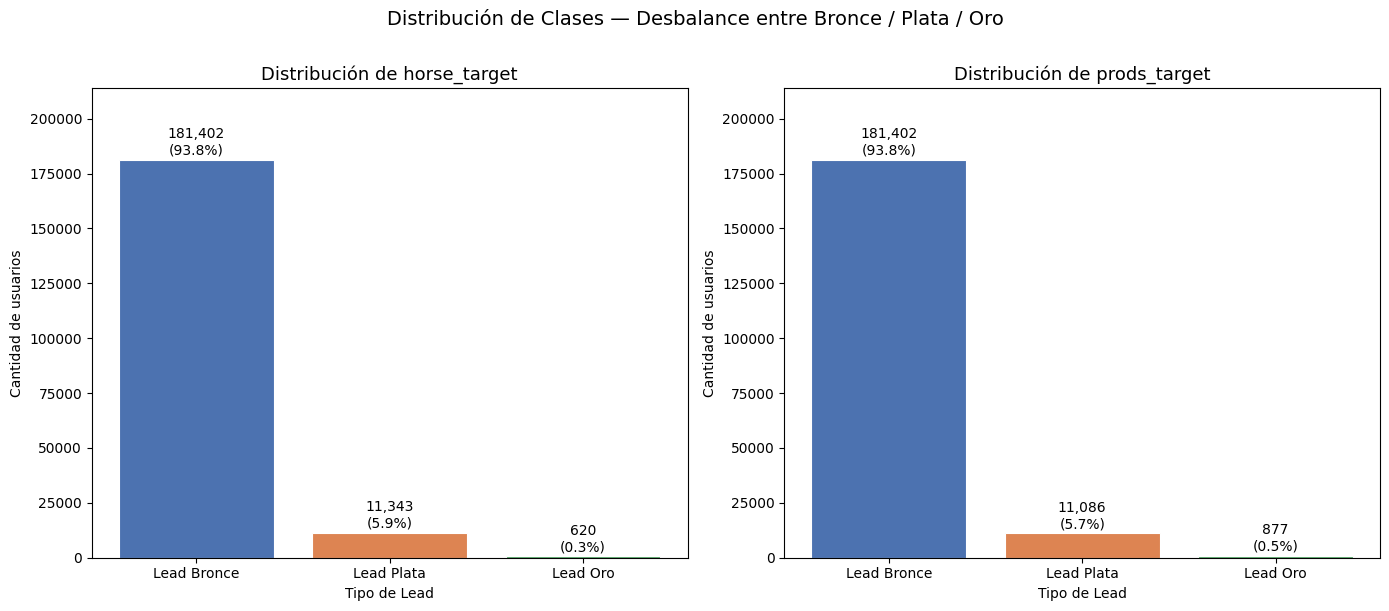

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = ['#4C72B0', '#DD8452', '#55A868']

for target, ax in zip(targets, axes):
    counts = df_final[target].value_counts().reindex(orden_leads)
    bars = ax.bar(orden_leads, counts.values, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(f'Distribución de {target}', fontsize=13)
    ax.set_xlabel('Tipo de Lead')
    ax.set_ylabel('Cantidad de usuarios')

    # Agregar etiquetas con % encima de cada barra
    total = counts.sum()
    for bar, val in zip(bars, counts.values):
        pct = val / total * 100
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + total * 0.005,
                f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10)

    ax.set_ylim(0, counts.max() * 1.18)

plt.suptitle('Distribución de Clases — Desbalance entre Bronce / Plata / Oro', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [14]:
for target in targets: 
    values = df_final[target].value_counts()
    print(values)
    print("-"*50)

horse_target
Lead Bronce    181402
Lead Plata      11343
Lead Oro          620
Name: count, dtype: int64
--------------------------------------------------
prods_target
Lead Bronce    181402
Lead Plata      11086
Lead Oro          877
Name: count, dtype: int64
--------------------------------------------------


Podemos ver un gran desbalanceo de clases: hay muchos más Leads de Bronce y muy pocos Leads de Oro.

Para manejar este desbalance en el modelado usamos dos estrategias según el algoritmo:
- **Random Forest**: SMOTE en el dataset de entrenamiento para sobremuestrear la clase minoritaria
- **XGBoost**: `scale_pos_weight` calculado como `n_negativos / n_positivos`, que ajusta el peso de cada clase sin generar muestras sintéticas

Adicionalmente, RF usa `class_weight='balanced'` como parámetro de regularización complementario.


#### Distribución de las variables relacionadas al precio

In [15]:
# Resumen estadístico de las variables de precio
price_cols = [
    'avg_horse_price_viewed', 'max_horse_price_viewed', 'min_horse_price_viewed',
    'avg_product_price_viewed', 'max_product_price_viewed'
]
df_final[price_cols].describe().round(2)

,avg_horse_price_viewed,max_horse_price_viewed,min_horse_price_viewed,avg_product_price_viewed,max_product_price_viewed
count,193365.00,193365.00,193365.00,193365.00,193365.00
mean,28029.87,42624.14,21315.52,867.23,1446.68
std,37909.40,95362.83,29592.10,440.11,1045.56
min,15000.00,15000.00,15000.00,500.95,500.95
25%,19250.00,21000.00,15000.00,629.95,675.00
50%,22500.00,25000.00,17250.00,747.95,1075.50
75%,28300.00,45000.00,22000.00,928.23,1885.50
max,1000000.00,1000000.00,1000000.00,4765.50,4765.50


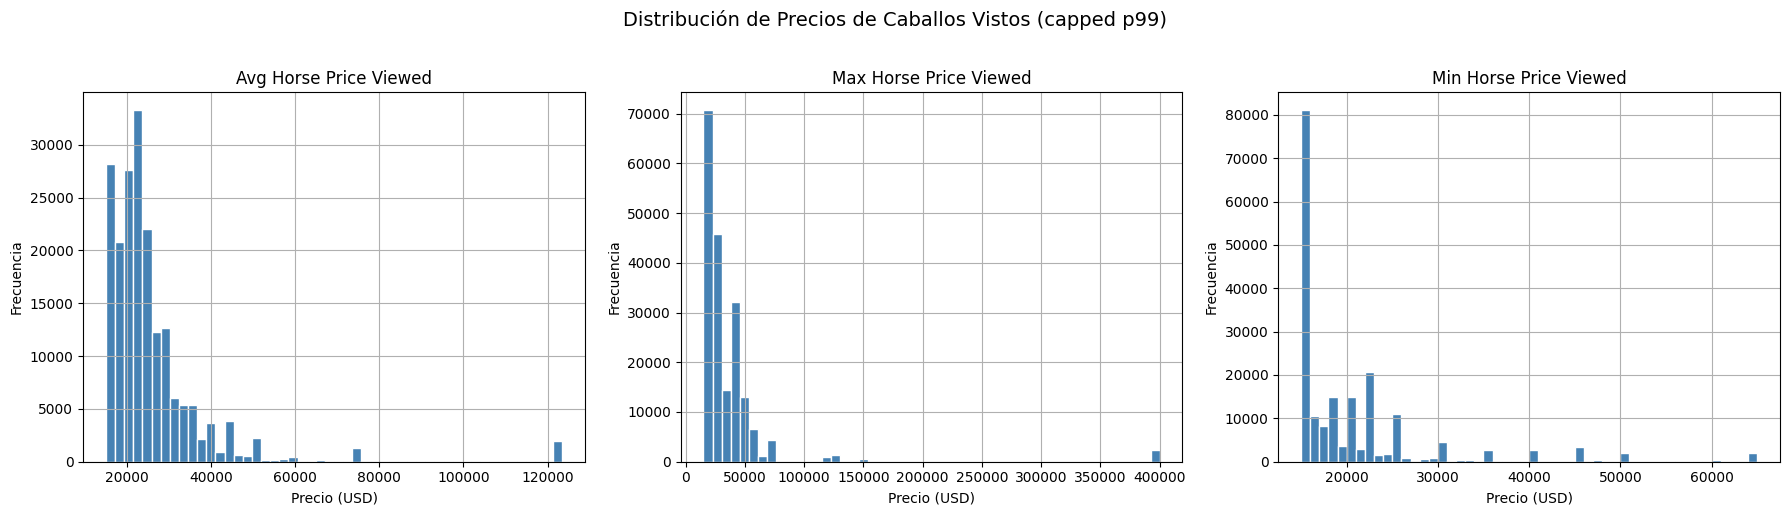

In [16]:
# Distribución de precios de caballos vistos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['avg_horse_price_viewed', 'max_horse_price_viewed', 'min_horse_price_viewed']):
    df_final[col].clip(upper=df_final[col].quantile(0.99)).hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Precio (USD)')
    ax.set_ylabel('Frecuencia')

plt.suptitle('Distribución de Precios de Caballos Vistos (capped p99)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

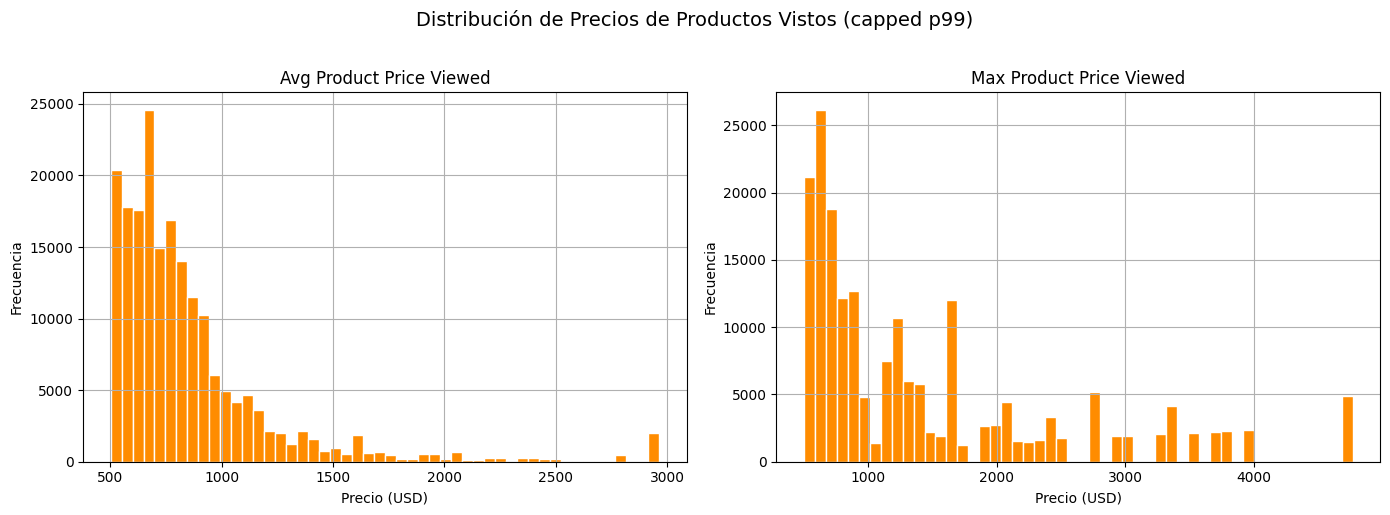

In [17]:
# Distribución de precios de productos vistos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ['avg_product_price_viewed', 'max_product_price_viewed']):
    df_final[col].clip(upper=df_final[col].quantile(0.99)).hist(bins=50, ax=ax, color='darkorange', edgecolor='white')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Precio (USD)')
    ax.set_ylabel('Frecuencia')

plt.suptitle('Distribución de Precios de Productos Vistos (capped p99)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Se observa que las distribuciones de precio tienen una cola larga hacia la derecha (skew positivo), lo cual es esperado en un marketplace de caballos donde los precios pueden variar desde cientos hasta cientos de miles de dólares. El capping al percentil 99 se aplicará en el preprocesamiento para reducir el efecto de outliers extremos.

#### Distribución de las variables relacionadas al engagement de caballos

Las variables de engagement miden cuánto interactuó el usuario con caballos y productos (cantidad de vistas, agregados al carrito, etc.). Son las features más importantes para el lead scoring.

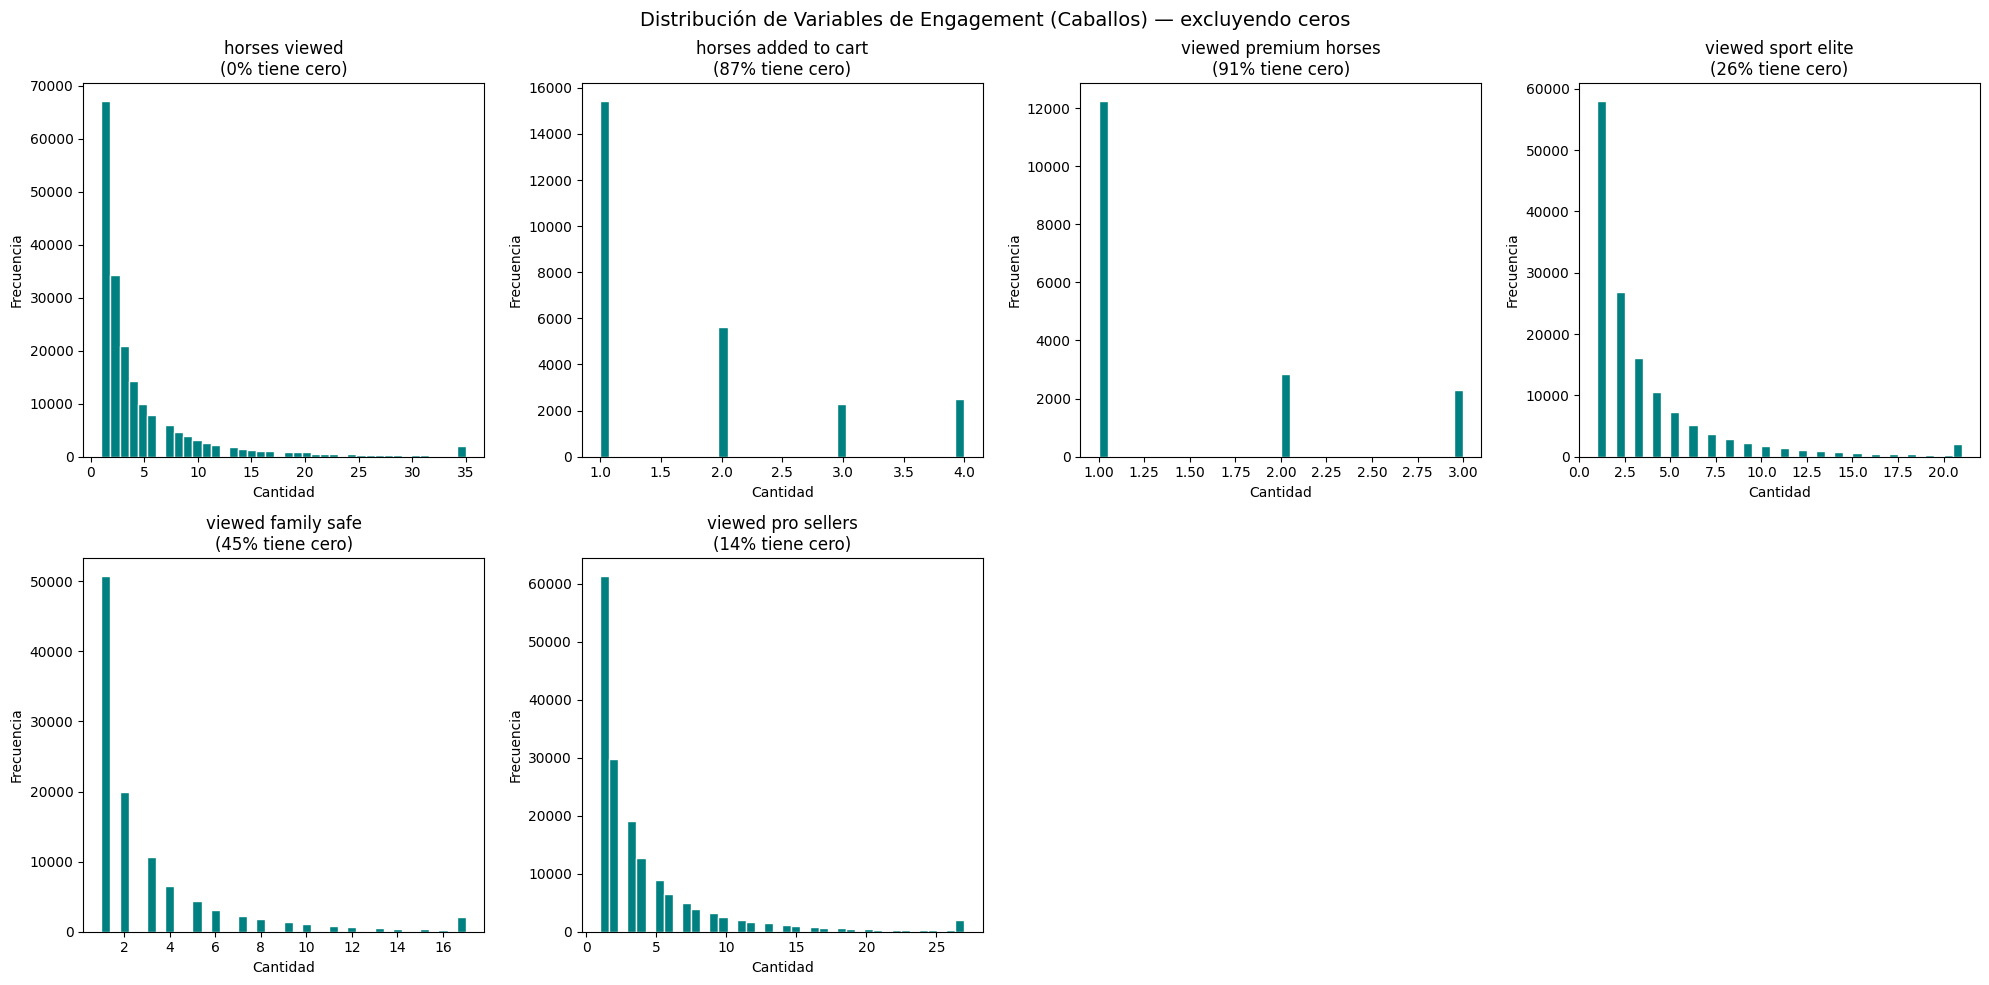

In [18]:
# Distribución de las variables de engagement de caballos
engagement_horse = [
    'horses_viewed', 'horses_added_to_cart', 'horses_purchased',
    'viewed_premium_horses', 'viewed_sport_elite', 'viewed_family_safe', 'viewed_pro_sellers'
]

# Filtramos solo columnas que existen
engagement_horse = [c for c in engagement_horse if c in df_final.columns]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, col in enumerate(engagement_horse):
    data = df_final[col].clip(upper=df_final[col].quantile(0.99))
    axes[idx].hist(data[data > 0], bins=40, color='teal', edgecolor='white')
    axes[idx].set_title(col.replace('_', ' '))
    axes[idx].set_xlabel('Cantidad')
    axes[idx].set_ylabel('Frecuencia')
    pct_zero = (df_final[col] == 0).mean() * 100
    axes[idx].set_title(f'{col.replace("_", " ")}\n({pct_zero:.0f}% tiene cero)')

for idx in range(len(engagement_horse), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Distribución de Variables de Engagement (Caballos) — excluyendo ceros', fontsize=14)
plt.tight_layout()
plt.show()

La mayoría de los usuarios tienen 0 interacciones con muchas de estas variables, lo que genera distribuciones muy sesgadas. El porcentaje con cero en cada feature nos indica cuán 'escasas' son. Las variables de engagement son las que más van a diferenciar los niveles de lead.

#### Distribución de las variables relacionadas al engagement de productos

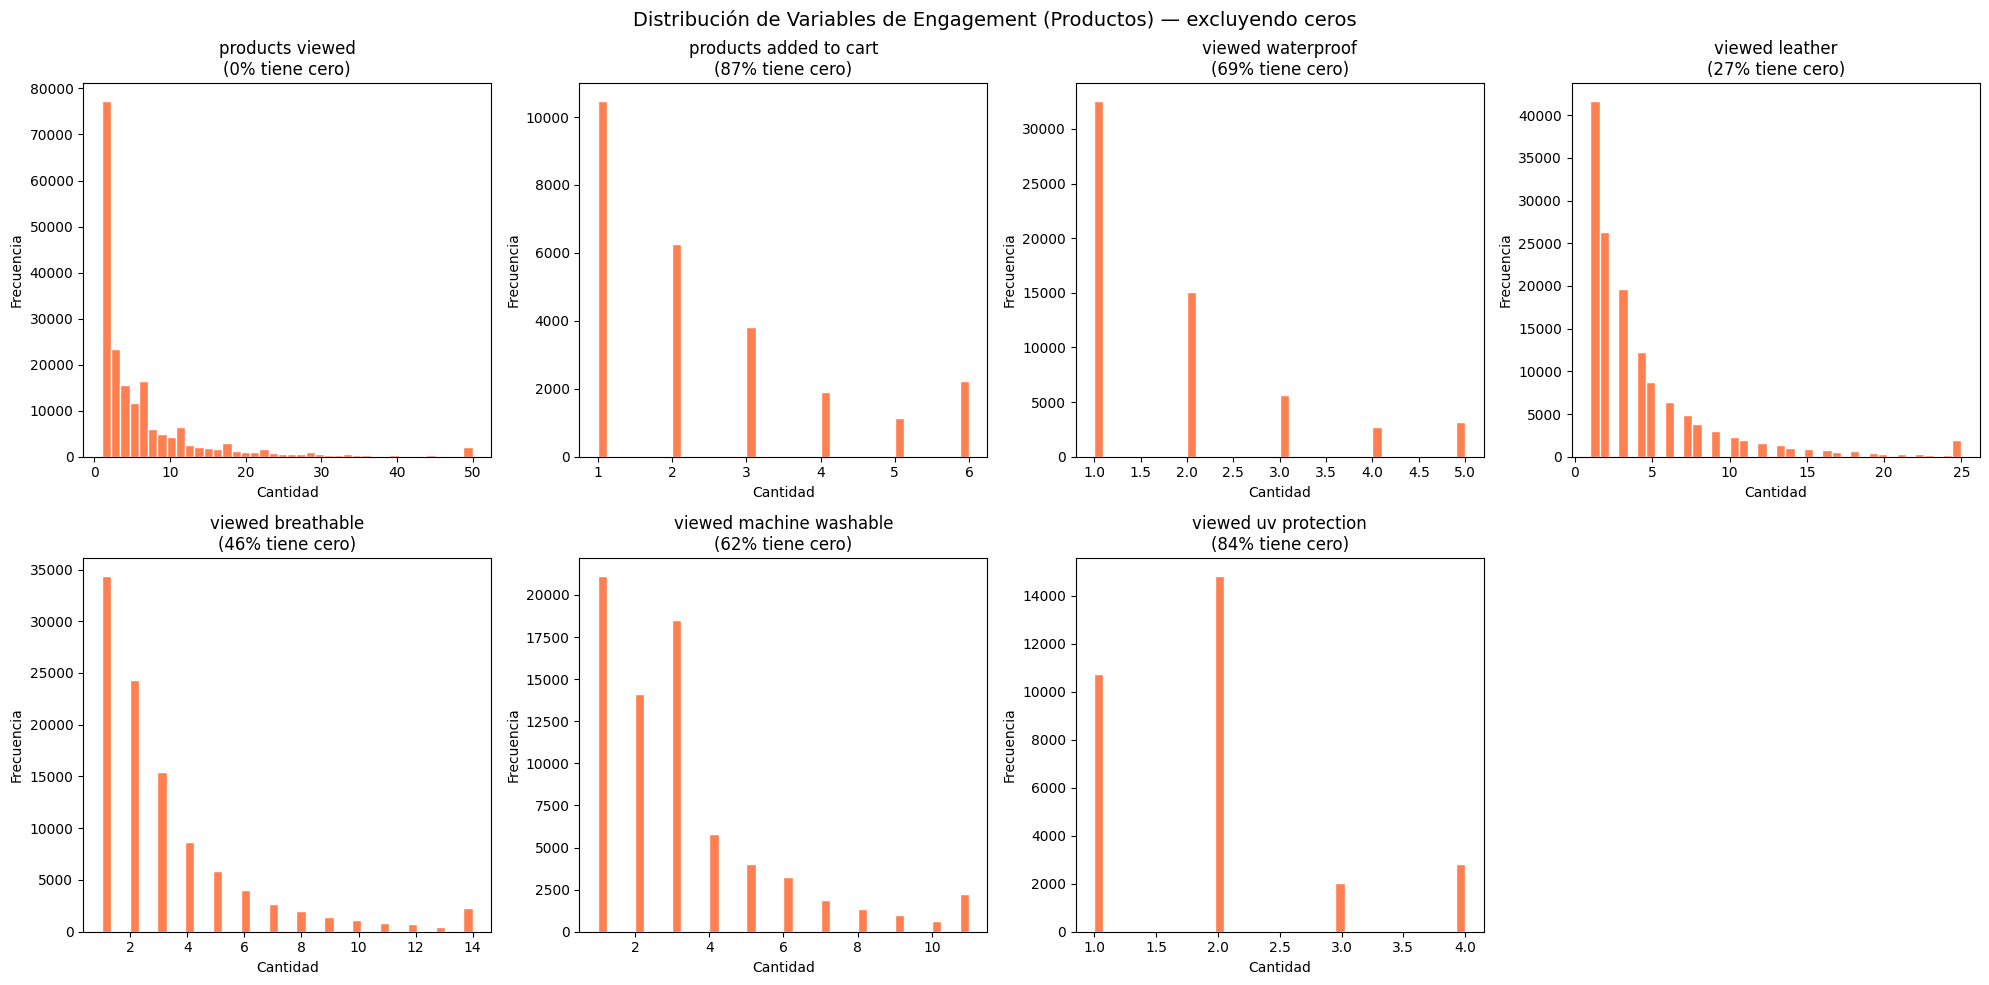

In [19]:
# Distribución de las variables de engagement de productos
engagement_prod = [
    'products_viewed', 'products_added_to_cart', 'products_purchased',
    'viewed_waterproof', 'viewed_leather', 'viewed_breathable', 'viewed_machine_washable' ,'viewed_uv_protection'
]

engagement_prod = [c for c in engagement_prod if c in df_final.columns]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, col in enumerate(engagement_prod):
    data = df_final[col].clip(upper=df_final[col].quantile(0.99))
    axes[idx].hist(data[data > 0], bins=40, color='coral', edgecolor='white')
    pct_zero = (df_final[col] == 0).mean() * 100
    axes[idx].set_title(f'{col.replace("_", " ")}\n({pct_zero:.0f}% tiene cero)')
    axes[idx].set_xlabel('Cantidad')
    axes[idx].set_ylabel('Frecuencia')

for idx in range(len(engagement_prod), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Distribución de Variables de Engagement (Productos) — excluyendo ceros', fontsize=14)
plt.tight_layout()
plt.show()

Las distribuciones de engagement de productos muestran el mismo patrón que las de 
caballos pero con asimetría aún más marcada:

- `products_viewed` y `products_added_to_cart` tienen más del 90% de usuarios en cero, 
  lo que refleja que la mayoría de los visitantes llegan por los caballos y el interés 
  en productos es secundario. No es un problema de calidad de datos — es información 
  real: la mayoría de los Leads Bronce directamente no interactúa con productos.

- `viewed_leather` y `viewed_breathable` son los atributos de producto más visualizados 
  cuando hay actividad, lo que tiene sentido dado el perfil de compradores de equipamiento 
  ecuestre de alta gama que prioriza materiales premium.

- `viewed_machine_washable` y `viewed_uv_protection` tienen distribuciones similares 
  pero con colas más cortas, indicando que son características buscadas por un segmento 
  más específico — compradores de ropa funcional para uso diario más que de tack premium.

#### Distribución de otras variables numéricas

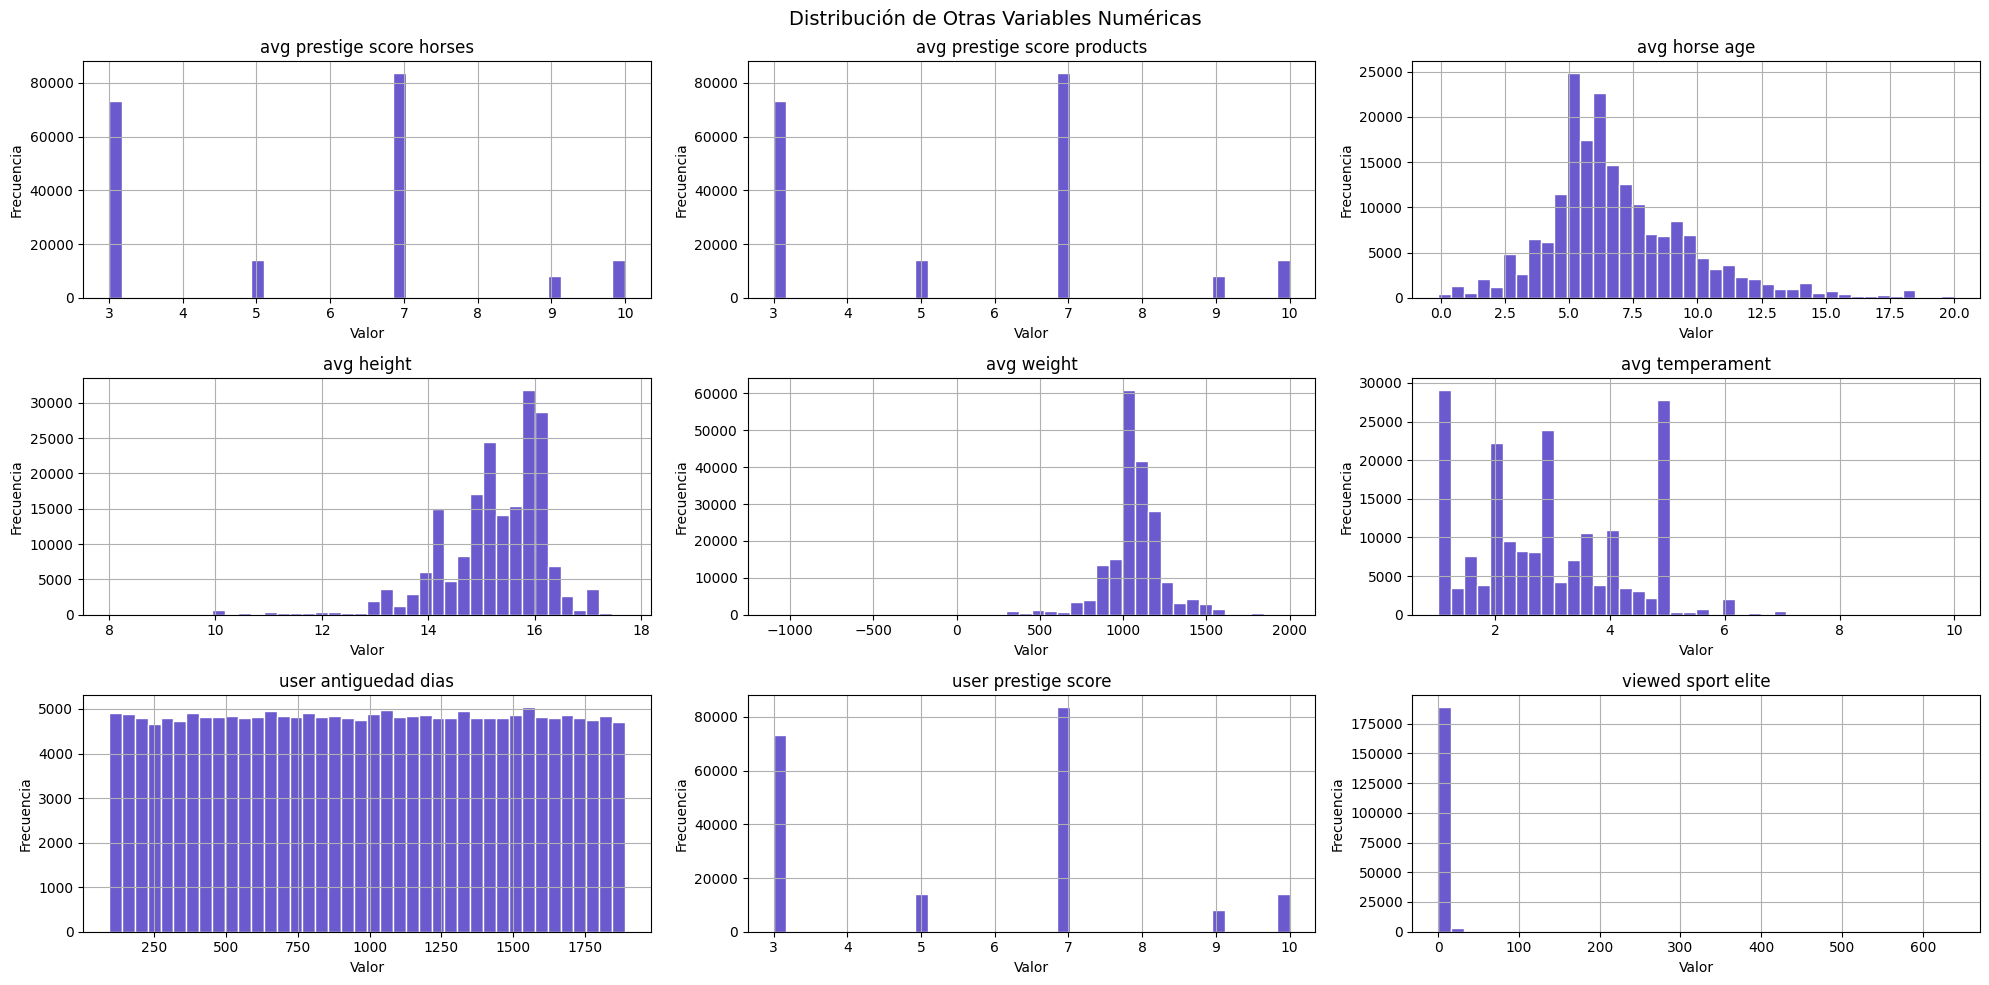

In [20]:
other_numeric = [
    'avg_prestige_score_horses',  'avg_prestige_score_products', 'avg_horse_age', 'avg_height', 'avg_weight',
    'avg_temperament', 'user_antiguedad_dias', 'user_prestige_score', 'viewed_sport_elite'
]
other_numeric = [c for c in other_numeric if c in df_final.columns]

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.flatten()

for idx, col in enumerate(other_numeric):
    df_final[col].hist(bins=40, ax=axes[idx], color='slateblue', edgecolor='white')
    axes[idx].set_title(col.replace('_', ' '))
    axes[idx].set_xlabel('Valor')
    axes[idx].set_ylabel('Frecuencia')

for idx in range(len(other_numeric), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Distribución de Otras Variables Numéricas', fontsize=14)
plt.tight_layout()
plt.show()

**`avg_prestige_score_horses` y `avg_prestige_score_products`**: Distribuciones discretas 
(valores fijos: 3, 5, 7, 9, 10) porque `prestige_score` es categórico en origen. 
Reflejan el prestige del usuario visitante promediado sobre los caballos/productos vistos, 
no del vendedor. Se espera poca separación entre niveles de lead — el cargo laboral del 
comprador no predice directamente si va a comprar.

**`avg_horse_age`**: Distribución aproximadamente normal centrada entre 7 y 10 años, 
el rango de mayor valor comercial para caballos de deporte y trabajo. No se esperan 
diferencias marcadas entre niveles de lead en esta variable.

**`avg_height` y `avg_weight`**: Distribuciones dentro de los rangos físicos típicos 
del mercado ecuestre (14–17 hh de altura, 900–1200 lbs de peso). El scatter posterior 
confirma que los tres niveles de lead se distribuyen de forma similar en ese espacio — 
bajo poder discriminativo, candidatas a dropear.

**`avg_temperament`**: Escala del 1 al 10. La distribución esperada es asimétrica hacia 
valores bajos (1–4) dado que la mayoría de los caballos listados son animales manejables 
para facilitar la venta. Poca separación esperada entre niveles de lead.

**`user_antiguedad_dias`**: Distribución aproximadamente uniforme entre ~90 y ~1890 días, 
lo que refleja que la base de usuarios cubre todas las cohortes de forma pareja desde el 
inicio de la plataforma. La antigüedad sola no predice la intención de compra — un usuario 
puede llevar años explorando sin concretar.

**`user_prestige_score`**: Distribución discreta concentrada en el valor 7 (owners, CEOs, 
founders), que es el perfil dominante del mercado ecuestre. Los valores 9 y 10 (perfiles 
olímpicos e inversores) son minoritarios pero probablemente sobrerrepresentados en Lead Oro.

**`viewed_sport_elite`**: Distribución muy sesgada hacia cero — la mayoría de los usuarios 
no vio ningún caballo de élite deportiva. Cuando hay actividad, la cola es larga, lo que 
indica que un subgrupo de usuarios se especializa fuertemente en ese segmento.

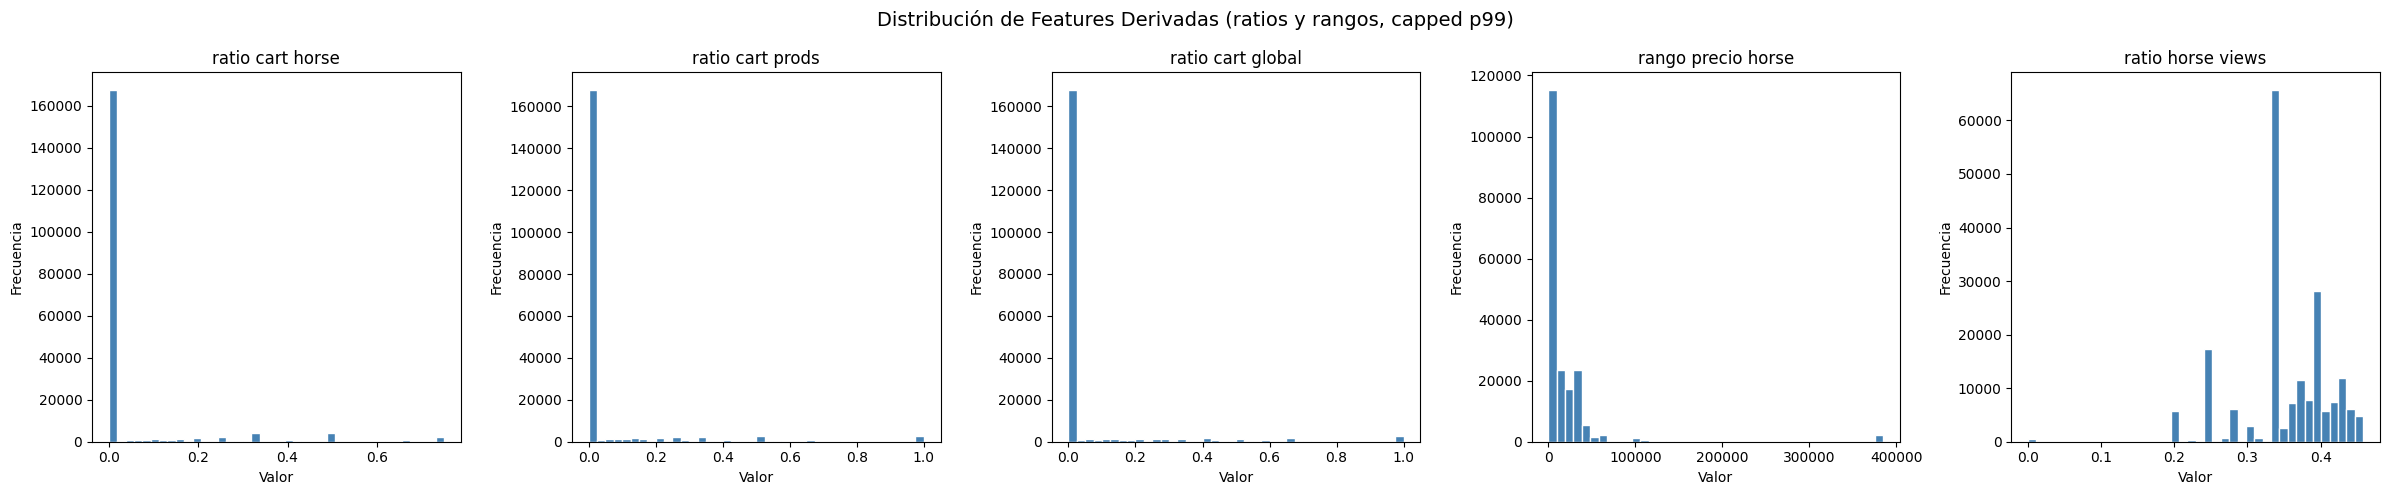

In [21]:
derivadas = [
    'ratio_cart_horse', 'ratio_cart_prods', 'ratio_cart_global',
    'rango_precio_horse', 'ratio_horse_views'
]

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for idx, col in enumerate(derivadas):
    data = df_final[col].clip(upper=df_final[col].quantile(0.99))
    axes[idx].hist(data, bins=40, color='steelblue', edgecolor='white')
    axes[idx].set_title(col.replace('_', ' '))
    axes[idx].set_xlabel('Valor')
    axes[idx].set_ylabel('Frecuencia')

plt.suptitle('Distribución de Features Derivadas (ratios y rangos, capped p99)', fontsize=14)
plt.tight_layout()
plt.show()

Las features derivadas muestran distribuciones esperadas:

**`ratio_cart_horse` y `ratio_cart_prods`**: Muy concentradas cerca de cero — la mayoría 
de los usuarios que ven caballos y productos no llegan a agregar al carrito. La cola hacia 
valores altos corresponde a usuarios con alta intención de compra, probablemente Plata u Oro.

**`ratio_cart_global`**: Misma forma que los anteriores pero más comprimida — es el 
promedio entre los dos ratios individuales.

**`rango_precio_horse`**: Distribución sesgada a la derecha. Un rango amplio indica que 
el usuario exploró caballos de precios muy distintos — posible señal de exploración sin 
foco o de comparación entre opciones. Correlaciona 0.95 con `max_horse_price_viewed`, 
lo que lo hace redundante — ya fue documentado en los grupos colineales.

**`ratio_horse_views`**: Concentrado cerca de 1 para la mayoría de usuarios (vieron 
casi exclusivamente caballos), con una cola hacia valores bajos para los que también 
exploraron productos. Útil para identificar usuarios con interés mixto.

### Análisis Bivariado

#### Variables Numéricas vs Horse Target

In [22]:
# Definimos el orden y los colores para cada panel
leads = ['Lead Bronce', 'Lead Plata', 'Lead Oro']
colores = ['#cd7f32', '#C0C0C0', '#FFD700'] 

/tmp/ipykernel_80795/3218065481.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y=col,
/tmp/ipykernel_80795/3218065481.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y=col,
/tmp/ipykernel_80795/3218065481.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y=col,


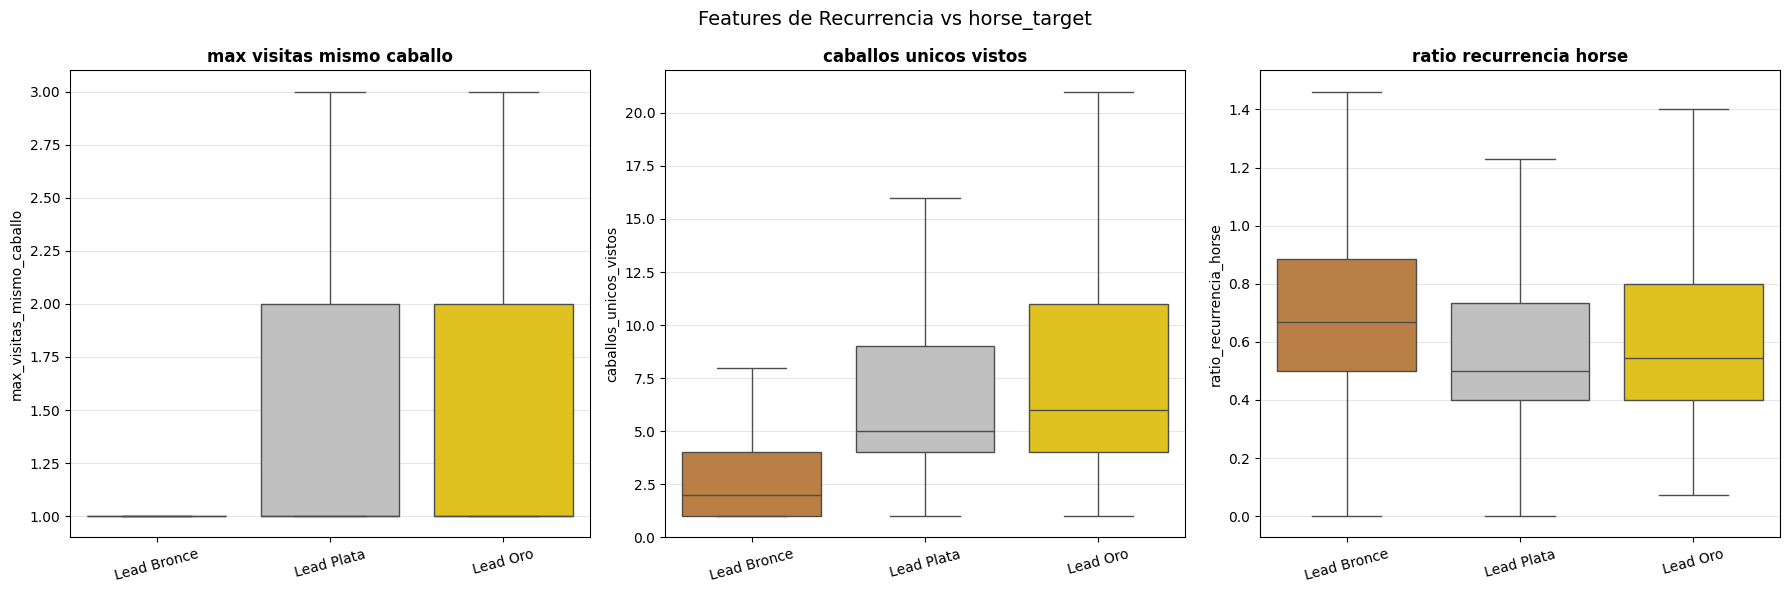

In [23]:
# Features de recurrencia vs horse_target
cols_recurrencia = [
    'max_visitas_mismo_caballo',
    'caballos_unicos_vistos',
    'ratio_recurrencia_horse'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, cols_recurrencia):
    data_plot = df_final[[col, 'horse_target']].copy()
    data_plot[col] = data_plot[col].clip(upper=data_plot[col].quantile(0.98))
    sns.boxplot(data=data_plot, x='horse_target', y=col,
                order=leads, palette=colores, ax=ax, showfliers=False)
    ax.set_title(col.replace('_', ' '), fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Features de Recurrencia vs horse_target', fontsize=14)
plt.tight_layout()
plt.show()

Las features de recurrencia confirman el patrón conductual más claro del dataset:

- **`max_visitas_mismo_caballo`**: Los Leads de Oro tienen la mediana y el rango 
  intercuartílico más altos. Volver varias veces al mismo anuncio es la señal más 
  directa de intención de compra — un curioso navega muchos caballos distintos y 
  vuelve poco a cada uno, un comprador serio regresa al mismo anuncio repetidamente 
  antes de decidir.

- **`caballos_unicos_vistos`**: El patrón es el inverso al anterior. Los Bronce 
  tienden a ver más caballos únicos — navegan ampliamente sin foco. Los Oro ven menos 
  caballos distintos pero con mayor profundidad por anuncio. Exploración amplia sin 
  recurrencia es la firma del curioso.

- **`ratio_recurrencia_horse`**: Sintetiza ambas señales anteriores. Oro tiene el 
  ratio más alto (muchas vistas concentradas en pocos caballos únicos), Bronce el 
  más bajo. Captura la concentración de atención, que resulta ser el mejor predictor 
  conductual de compra de las features nuevas.

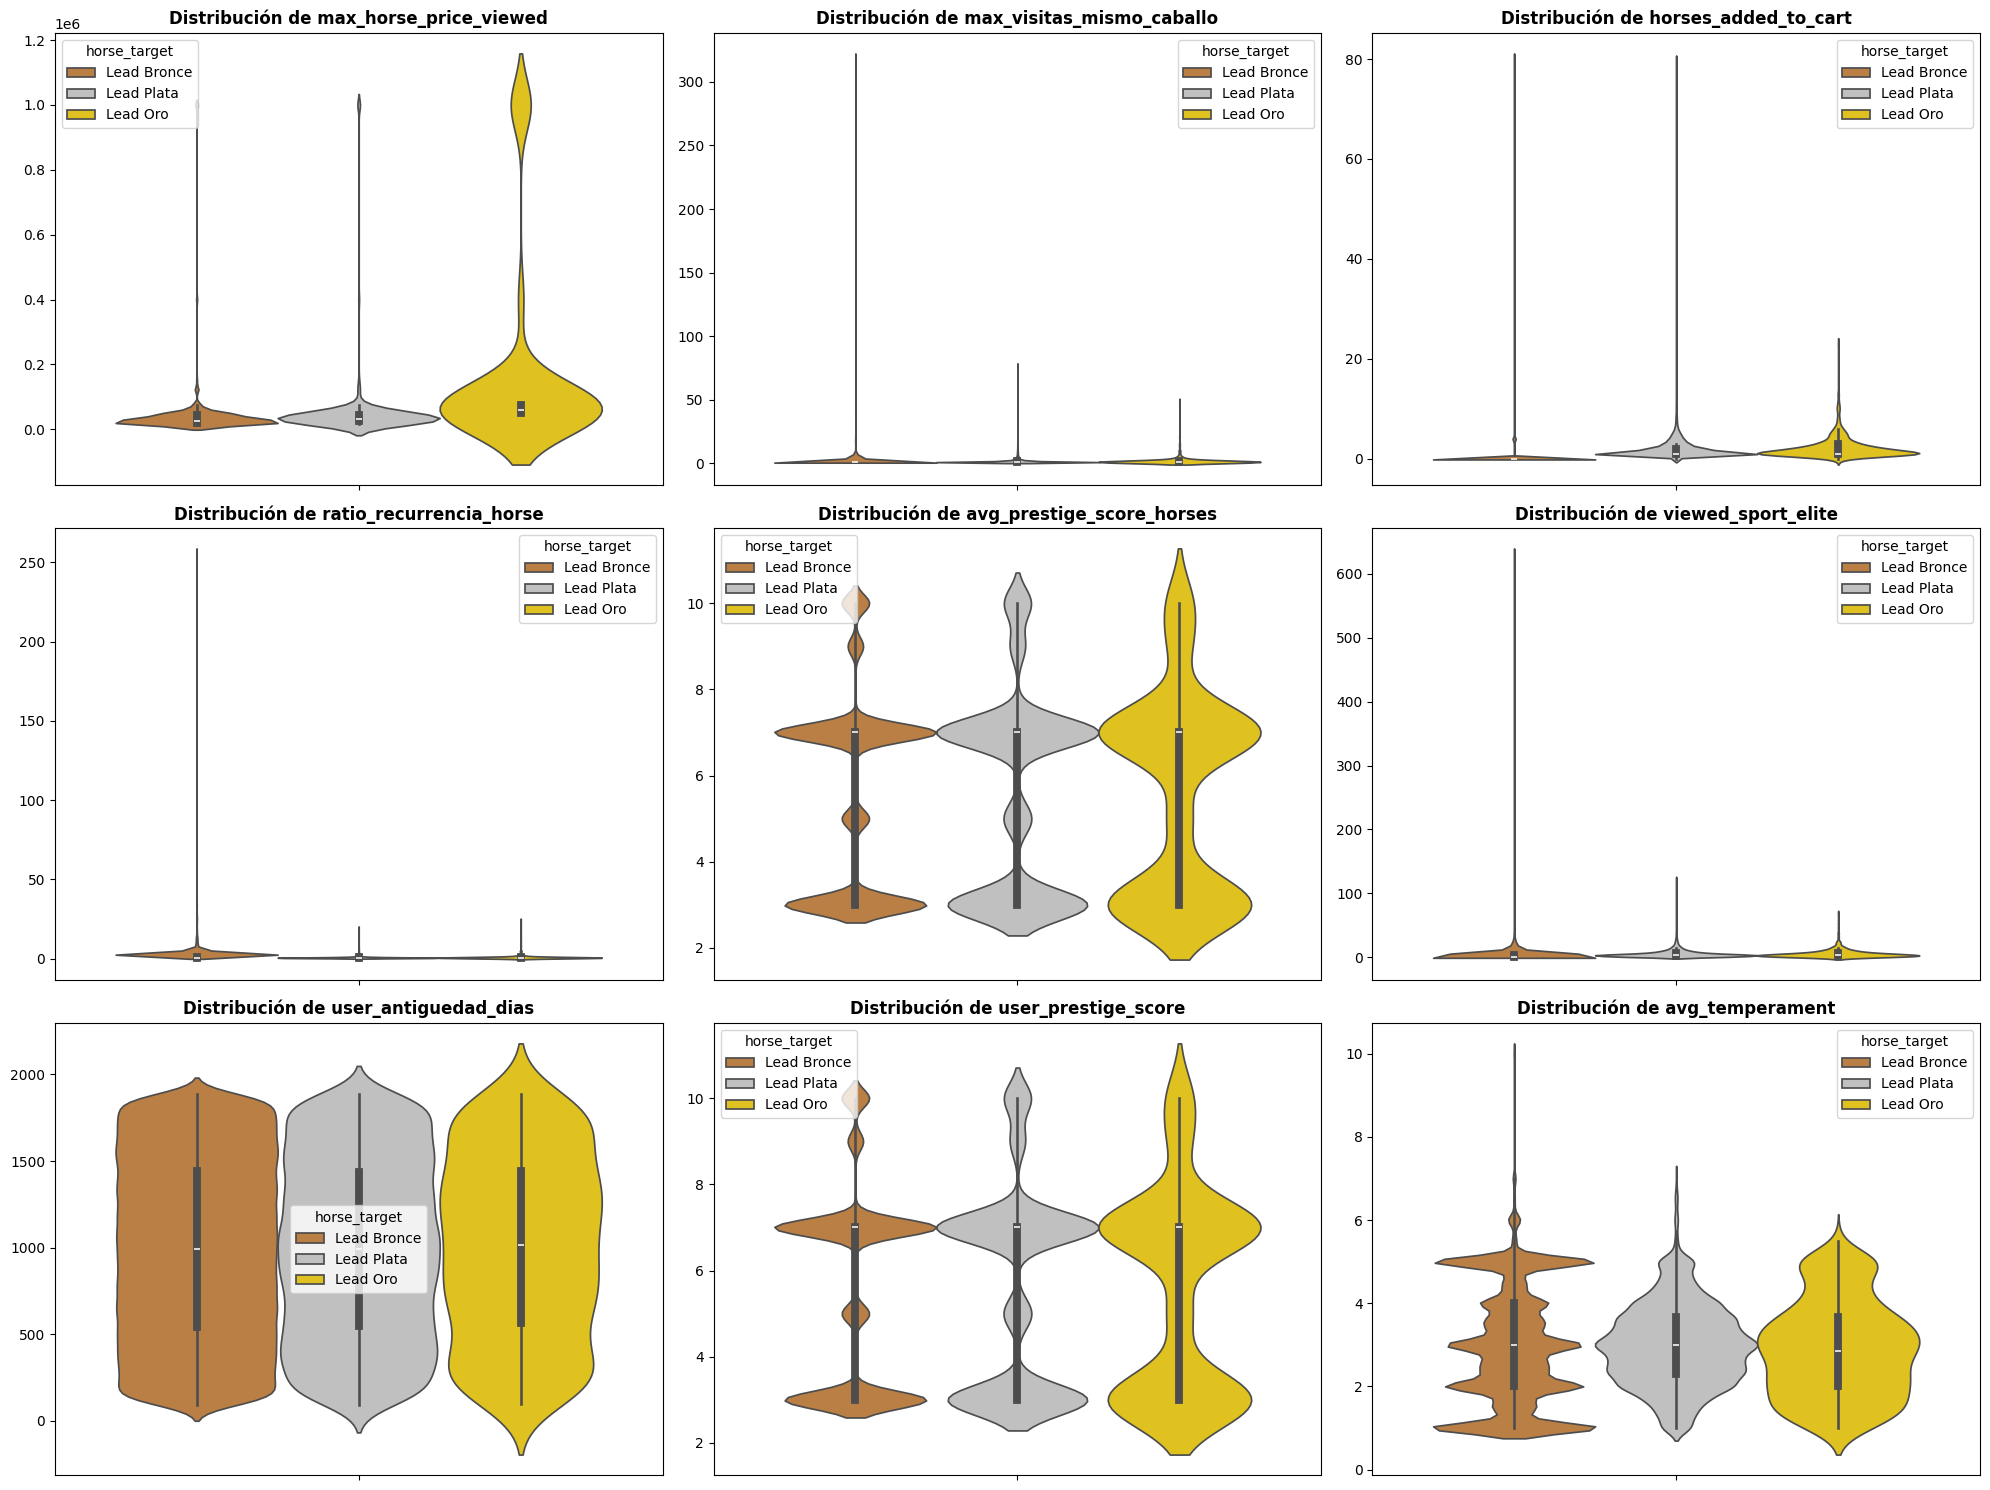

In [24]:
top_features = [
    'max_horse_price_viewed', 
    'max_visitas_mismo_caballo', 
    'horses_added_to_cart', 
    'ratio_recurrencia_horse',  
    'avg_prestige_score_horses', 
    'viewed_sport_elite',
    'user_antiguedad_dias',
    'user_prestige_score',
    'avg_temperament'
]

# Creamos una cuadrícula de 3 filas y 3 columnas
fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes = axes.flatten() # Aplanamos para iterar fácilmente

for i, col in enumerate(top_features):
    if col in df_final.columns:
        sns.violinplot(data=df_final, y=col, ax=axes[i], hue="horse_target", hue_order=leads, palette=colores)
        axes[i].set_title(f"Distribución de {col}", fontweight='bold')
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Los gráficos de violín contra `horse_target` muestran:

- **`max_horse_price_viewed`**: Es la variable con mayor poder discriminativo del dataset. 
  La mediana de Lead Oro está desplazada 3-4x por encima de la mediana de Bronce. 
  La distribución de Oro tiene una cola hacia precios muy altos (>100k) que casi no 
  aparece en Plata ni Bronce.

- **`horses_added_to_cart`**: Clara separación entre Bronce (mediana 0) y Plata/Oro 
  (medianas positivas). La distribución de Oro no es marcadamente mayor que la de Plata, 
  lo que sugiere que los compradores Oro agregan al carrito con decisión — no necesitan 
  muchos intentos antes de comprar.

- **`viewed_sport_elite`**: Separación moderada. Oro y Plata ven más caballos de élite 
  deportiva que Bronce, pero la diferencia no es tan pronunciada como en precio o carrito. 
  Actúa como señal de refinamiento del perfil más que como discriminador principal.

- **`avg_prestige_score_horses`**: Poca separación entre clases. Confirma que el prestige 
  del comprador (su cargo laboral) no predice directamente el nivel de lead — un CEO puede 
  estar curioseando sin intención de compra.

- **`ratio_recurrencia_horse`**: Los Leads de Oro muestran una distribución desplazada 
  hacia valores más altos que Bronce. Un usuario que vuelve al mismo caballo varias veces 
  antes de decidir tiene mayor intención de compra que uno que navega muchos caballos 
  distintos sin profundizar.

- **`max_visitas_mismo_caballo`**: Patrón similar a `ratio_recurrencia_horse` pero más 
  concentrado. Los Oro tienen colas más largas hacia valores altos — vuelven más veces al 
  mismo anuncio que Bronce. Es la señal de intención más directa de las features nuevas.

- **`user_antiguedad_dias`**: Distribución similar entre clases. La antigüedad sola no 
  discrimina — hay compradores nuevos y veteranos en todos los niveles.

- **`user_prestige_score`**: Leve desplazamiento en Oro hacia valores altos (9-10). 
  La mayoría de todos los niveles tiene score 7, pero la proporción de scores 9-10 es 
  mayor en Oro que en Bronce.

- **`avg_temperament`**: Distribuciones muy similares entre niveles de lead. 
  El temperamento promedio de los caballos vistos no discrimina — tanto compradores 
  como curiosos exploran caballos de temperamento variado.

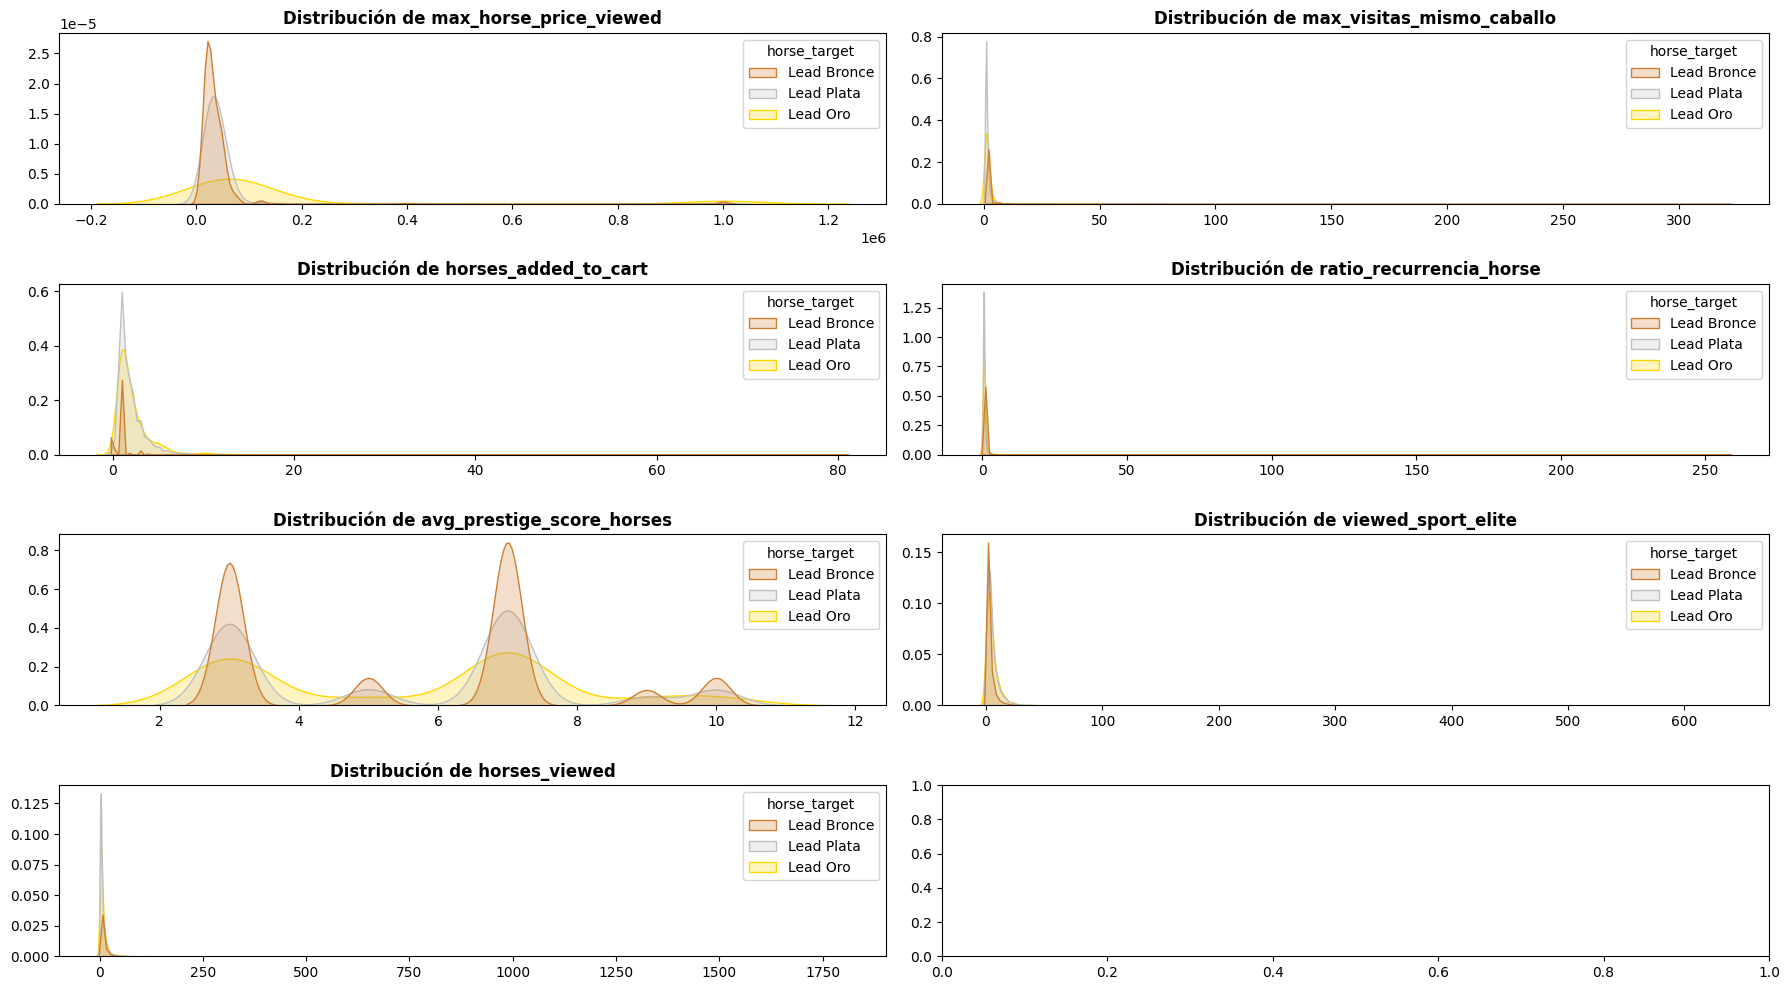

In [25]:
top_features = [
    'max_horse_price_viewed', 
    'max_visitas_mismo_caballo', 
    'horses_added_to_cart', 
    'ratio_recurrencia_horse',  
    'avg_prestige_score_horses', 
    'viewed_sport_elite',
    'horses_viewed'
]

fig, axes = plt.subplots(4, 2, figsize=(18, 10))
axes = axes.flatten() # Aplanamos para iterar fácilmente

for i, col in enumerate(top_features):
    if col in df_final.columns:
        sns.kdeplot(data=df_final, x=col, ax=axes[i], hue='horse_target', common_norm=False, fill=True, hue_order=leads, palette=colores)
        axes[i].set_title(f"Distribución de {col}", fontweight='bold')
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Los KDE confirman y enriquecen lo visto en los violines:

- **`max_horse_price_viewed`**: Las tres curvas se solapan en precios bajos (<10k) donde 
  coexisten todos los perfiles. A partir de ~30k la curva de Oro se separa claramente — 
  ese rango es casi exclusivo de compradores de alto valor.

- **`horses_added_to_cart`**: La masa de Bronce está completamente concentrada en 0. 
  Las curvas de Plata y Oro se extienden a la derecha, con Oro teniendo una cola más 
  larga hacia valores altos.

- **`ratio_recurrencia_horse`**: Oro tiene su pico desplazado hacia la derecha respecto 
  a Bronce. Usuarios con ratio > 1.5 son predominantemente Plata u Oro.

- **`max_visitas_mismo_caballo`**: La distribución de Oro cae más lentamente que Bronce 
  conforme aumentan las visitas al mismo caballo — volver al mismo anuncio es señal de 
  intención real.

- **`avg_prestige_score_horses`**: Las tres curvas se superponen casi completamente, 
  confirmando el bajo poder discriminativo de esta variable.

- **`viewed_sport_elite`**: Oro y Plata tienen curvas con cola más larga hacia valores 
  altos, pero el solapamiento con Bronce es considerable. Señal de refinamiento de perfil 
  más que discriminador fuerte.

- **`horses_viewed`**: Ver análisis detallado en la celda siguiente — los Oro ven pocos 
  caballos en total pero con alta recurrencia por caballo, combinación distintiva.

Entonces veamos un sola feature que esté relacionada con las vistas.

Text(0.5, 1.0, 'Cantidad de caballos vistos')

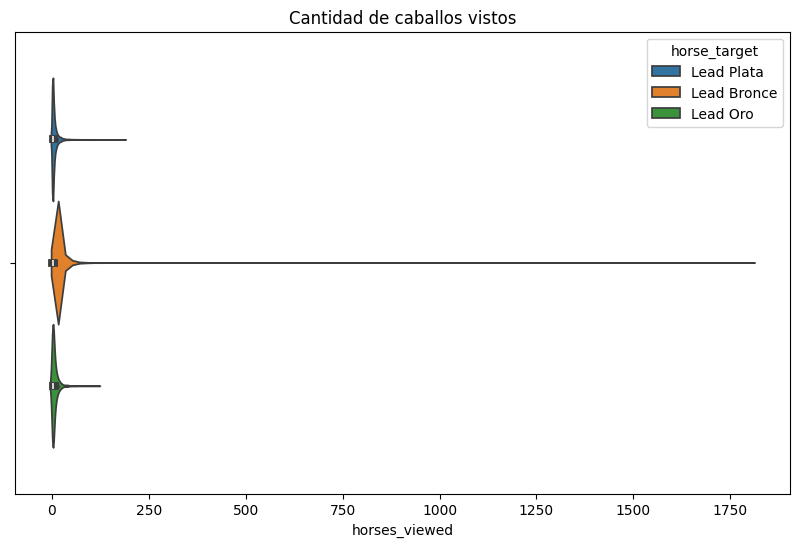

In [26]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_final, x='horses_viewed', hue="horse_target")
plt.title("Cantidad de caballos vistos") 

(-1.0, 30.0)

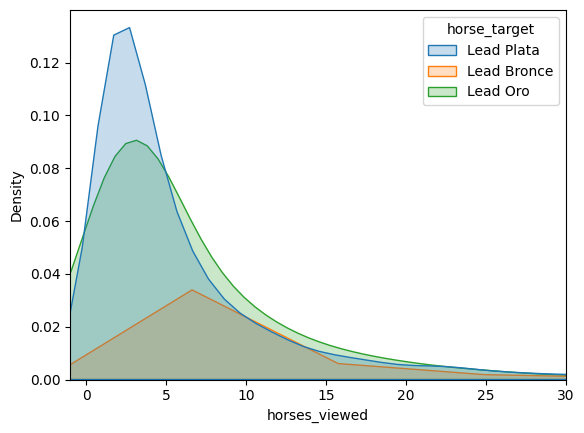

In [27]:
sns.kdeplot(data=df_final, x='horses_viewed', hue='horse_target', common_norm=False, fill=True)
plt.xlim(-1, 30)

El KDE muestra patrones claros:

- **Leads de Oro**: tienden a ver pocos caballos (entre 1 y 10). Saben lo que quieren y van directo a la compra.
- **Leads de Plata**: distribución más dispersa, muestran más exploración antes de agregar al carrito.
- **Leads de Bronce**: la gran mayoría ve muy pocos caballos (0-5), aunque hay una cola larga de usuarios que ven muchísimos — probablemente curiosos o bots que generan ese outlier.

Al final del EDA veamos los outliers más en detalle.

Veamos los valores de las demás features relacionadas con la vista de un usuario a caballos

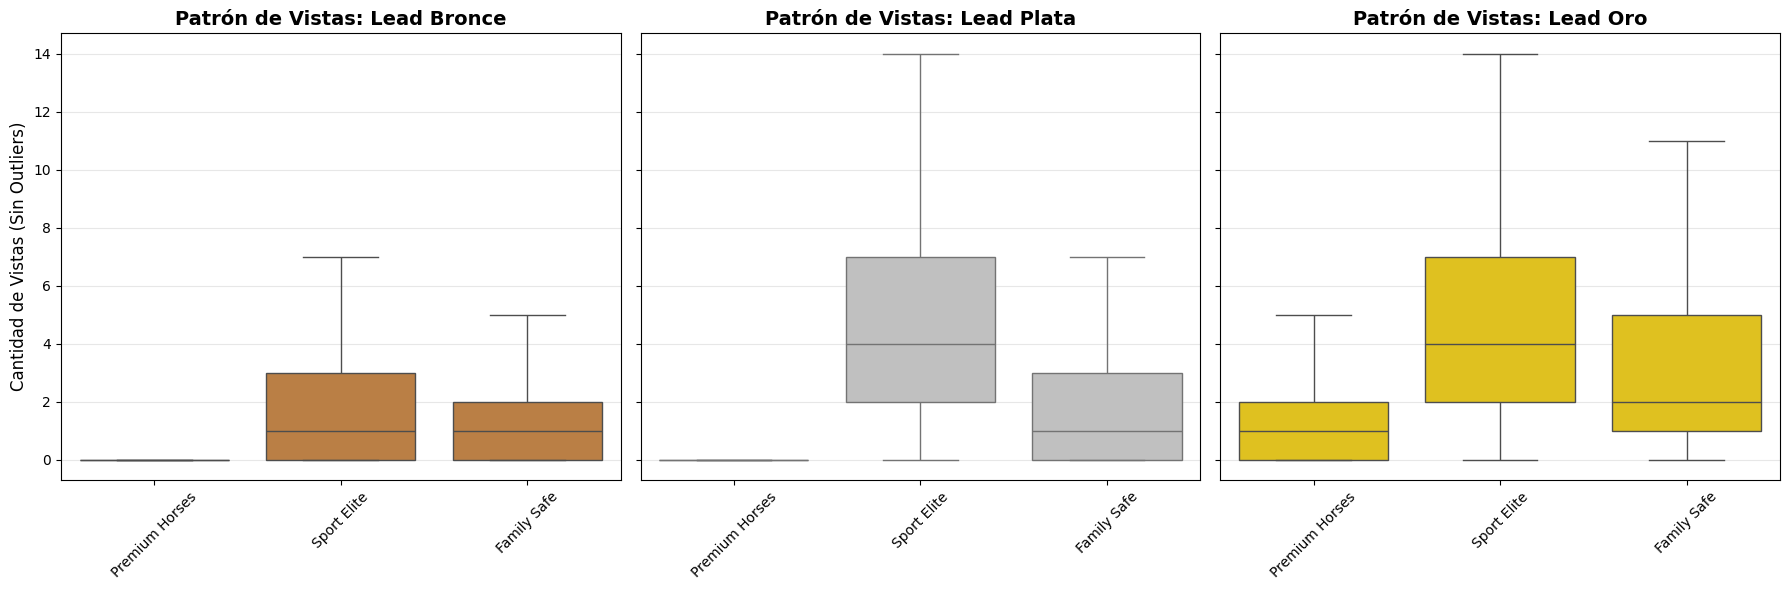

In [28]:
cols_vistas = [
    'viewed_premium_horses', 
    'viewed_sport_elite', 
    'viewed_family_safe'
]

df_vistas = df_final[['horse_target'] + cols_vistas]
df_melted = pd.melt(
    df_vistas, 
    id_vars=['horse_target'], 
    value_vars=cols_vistas,
    var_name='Tipo_de_Caballo', 
    value_name='Vistas'
)

df_melted['Tipo_de_Caballo'] = df_melted['Tipo_de_Caballo'].str.replace('viewed_', '').str.replace('_', ' ').str.title()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True) # sharey=True iguala el eje Y para que sean comparables

# Bucle para dibujar cada gráfico
for i, lead in enumerate(leads):
    # Filtramos solo los datos del lead actual
    datos_lead = df_melted[df_melted['horse_target'] == lead]
    
    # Usamos boxplot ocultando outliers extremos para ver la "masa normal"
    sns.boxplot(
        data=datos_lead, 
        x='Tipo_de_Caballo', 
        y='Vistas', 
        ax=axes[i],
        color=colores[i],
        showfliers=False 
    )
    
    # Diseño de cada panel
    axes[i].set_title(f"Patrón de Vistas: {lead}", fontsize=14, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45) 
    axes[i].set_xlabel("")
    axes[i].grid(axis='y', alpha=0.3)
    
    if i == 0:
        axes[i].set_ylabel("Cantidad de Vistas (Sin Outliers)", fontsize=12)
    else:
        axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Los Leads de Oro y Plata muestran mayor interacción con caballos premium, de elite deportiva y familiares que los Bronce. Esto valida que estas features son señales útiles para distinguir los niveles de lead.

/tmp/ipykernel_80795/2420098468.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y=col,
/tmp/ipykernel_80795/2420098468.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y=col,
/tmp/ipykernel_80795/2420098468.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y=col,


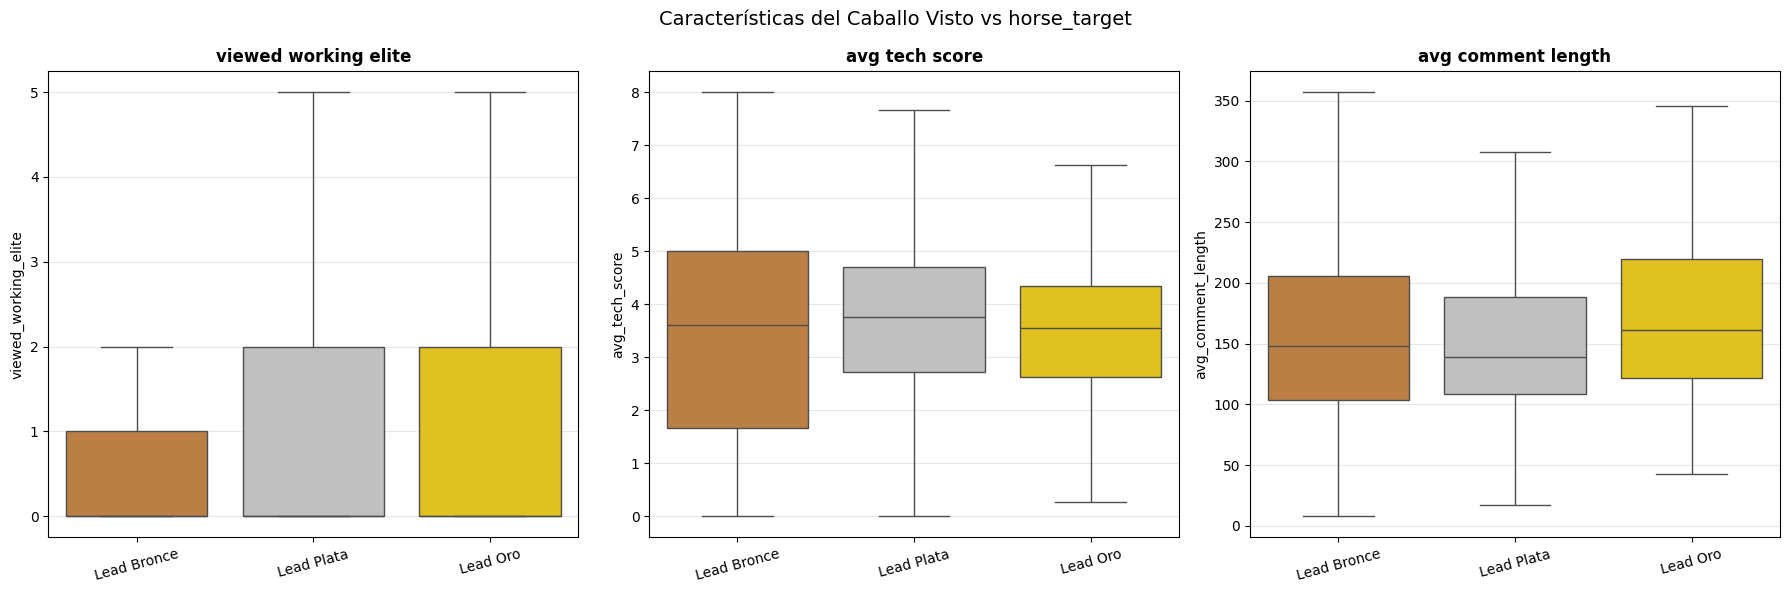

In [29]:
# Bivariado — Características del caballo vs horse_target
cols_horse_attrs = [
    'viewed_working_elite',
    'avg_tech_score',
    'avg_comment_length'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, cols_horse_attrs):
    data_plot = df_final[[col, 'horse_target']].copy()
    data_plot[col] = data_plot[col].clip(upper=data_plot[col].quantile(0.98))
    sns.boxplot(data=data_plot, x='horse_target', y=col,
                order=leads, palette=colores, ax=ax, showfliers=False)
    ax.set_title(col.replace('_', ' '), fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Características del Caballo Visto vs horse_target', fontsize=14)
plt.tight_layout()
plt.show()

- **`viewed_working_elite`**: Los Leads de Oro y Plata muestran mayor cantidad de 
  vistas a caballos de élite para trabajo que Bronce, aunque la diferencia es moderada. 
  El perfil comprador de caballos de trabajo (ganadería, rancho) es distinto al 
  deportivo pero igualmente serio — ambos perfiles apuntan a animales especializados 
  de alto valor.

- **`avg_tech_score`**: Score técnico promedio de los caballos visitados. La separación 
  entre niveles es leve, lo que indica que el tipo técnico del caballo buscado no 
  discrimina tanto como el comportamiento de búsqueda (recurrencia, precio). Un 
  comprador Oro puede buscar caballos con distintos perfiles técnicos según su actividad.

- **`avg_comment_length`**: Largo promedio de las descripciones de los caballos 
  visitados. Una diferencia en Oro indicaría que los compradores serios leen anuncios 
  más detallados. Si las distribuciones son similares entre niveles, confirma que este 
  atributo del anuncio no discrimina la intención de compra.

/tmp/ipykernel_80795/3057496181.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='horse_target', y='user_antiguedad_dias',


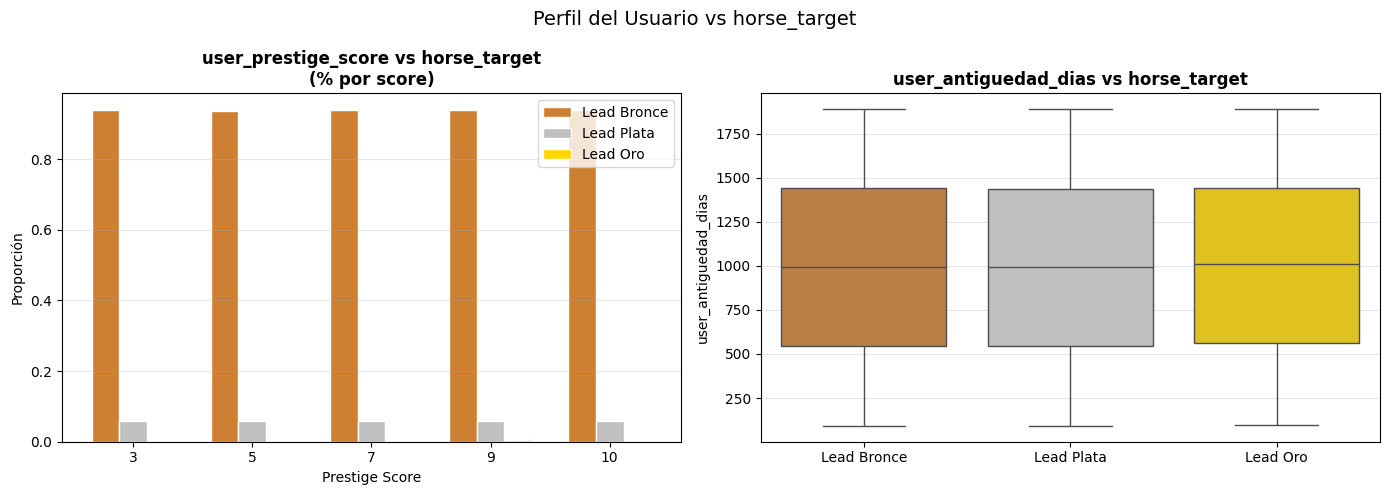

In [30]:
# Perfil del usuario vs horse_target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# user_prestige_score: mejor como barras apiladas normalizadas
prestige_cross = df_final.groupby(['user_prestige_score', 'horse_target']).size().unstack(fill_value=0)
prestige_cross_pct = prestige_cross.div(prestige_cross.sum(axis=1), axis=0)
prestige_cross_pct[leads].plot(kind='bar', ax=axes[0],
    color=colores, edgecolor='white', width=0.7)
axes[0].set_title('user_prestige_score vs horse_target\n(% por score)', fontweight='bold')
axes[0].set_xlabel('Prestige Score')
axes[0].set_ylabel('Proporción')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='', loc='upper right')
axes[0].grid(axis='y', alpha=0.3)

# user_antiguedad_dias: continua, boxplot
data_plot = df_final[['user_antiguedad_dias', 'horse_target']].copy()
sns.boxplot(data=data_plot, x='horse_target', y='user_antiguedad_dias',
            order=leads, palette=colores, ax=axes[1], showfliers=False)
axes[1].set_title('user_antiguedad_dias vs horse_target', fontweight='bold')
axes[1].set_xlabel('')
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Perfil del Usuario vs horse_target', fontsize=14)
plt.tight_layout()
plt.show()

- **`user_prestige_score`**: Los scores 9 y 10 (perfiles olímpicos e inversores) 
  tienen mayor proporción de Lead Oro que el score 3 (perfil genérico). Sin embargo 
  el score 7 (owners, CEOs, founders) concentra la mayoría absoluta de usuarios en 
  todos los niveles por su alta frecuencia base — es el perfil dominante del mercado 
  ecuestre. La señal del prestige es real pero débil sola; se potencia combinada con 
  recurrencia alta.

- **`user_antiguedad_dias`**: Las distribuciones son similares entre niveles de lead, 
  confirmando que la antigüedad por sí sola no predice la intención de compra. Un 
  usuario puede llevar años en la plataforma sin concretar una compra.

#### Variables Numéricas vs Product Target

/tmp/ipykernel_80795/1761183775.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='prods_target', y=col,
/tmp/ipykernel_80795/1761183775.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='prods_target', y=col,
/tmp/ipykernel_80795/1761183775.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_plot, x='prods_target', y=col,


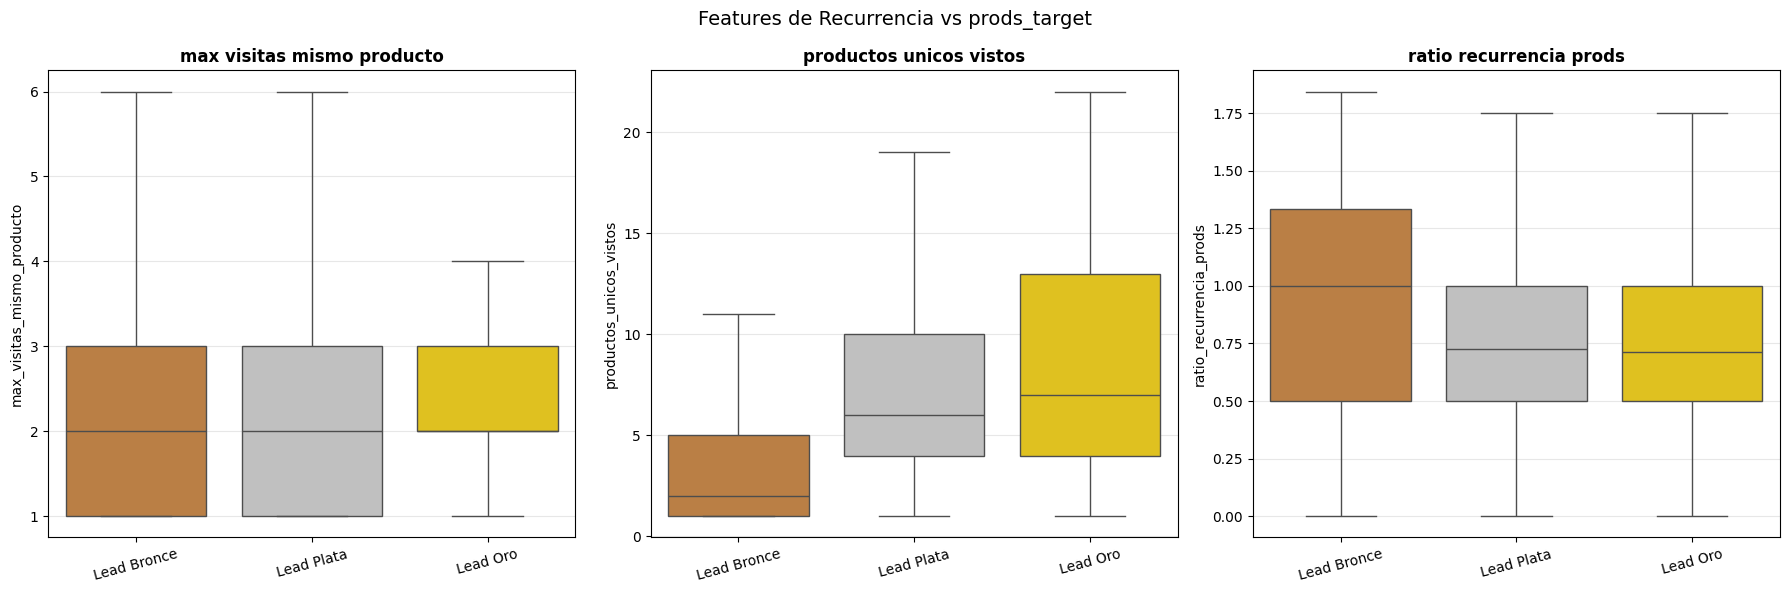

In [31]:
# Features de recurrencia vs prods_target
cols_rec_prods = [
    'max_visitas_mismo_producto',
    'productos_unicos_vistos',
    'ratio_recurrencia_prods'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, cols_rec_prods):
    data_plot = df_final[[col, 'prods_target']].copy()
    data_plot[col] = data_plot[col].clip(upper=data_plot[col].quantile(0.98))
    sns.boxplot(data=data_plot, x='prods_target', y=col,
                order=leads, palette=colores, ax=ax, showfliers=False, legend=False)
    ax.set_title(col.replace('_', ' '), fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Features de Recurrencia vs prods_target', fontsize=14)
plt.tight_layout()
plt.show()

Las features de recurrencia en productos replican el mismo patrón observado en caballos, 
aunque con diferencias más comprimidas dado que la mayoría de usuarios tiene poca 
actividad en productos:

- **`max_visitas_mismo_producto`**: Los Leads de Oro tienen medianas más altas, 
  aunque la separación es menor que en caballos. Volver al mismo producto antes de 
  comprar sigue siendo señal de intención, pero el proceso de decisión en productos 
  es más corto que en caballos.

- **`productos_unicos_vistos`**: Patrón inverso al anterior — los Bronce exploran 
  más productos distintos sin profundizar en ninguno.

- **`ratio_recurrencia_prods`**: Oro tiene el ratio más alto. La concentración de 
  atención sobre pocos productos específicos distingue al comprador del curioso, 
  igual que en caballos.

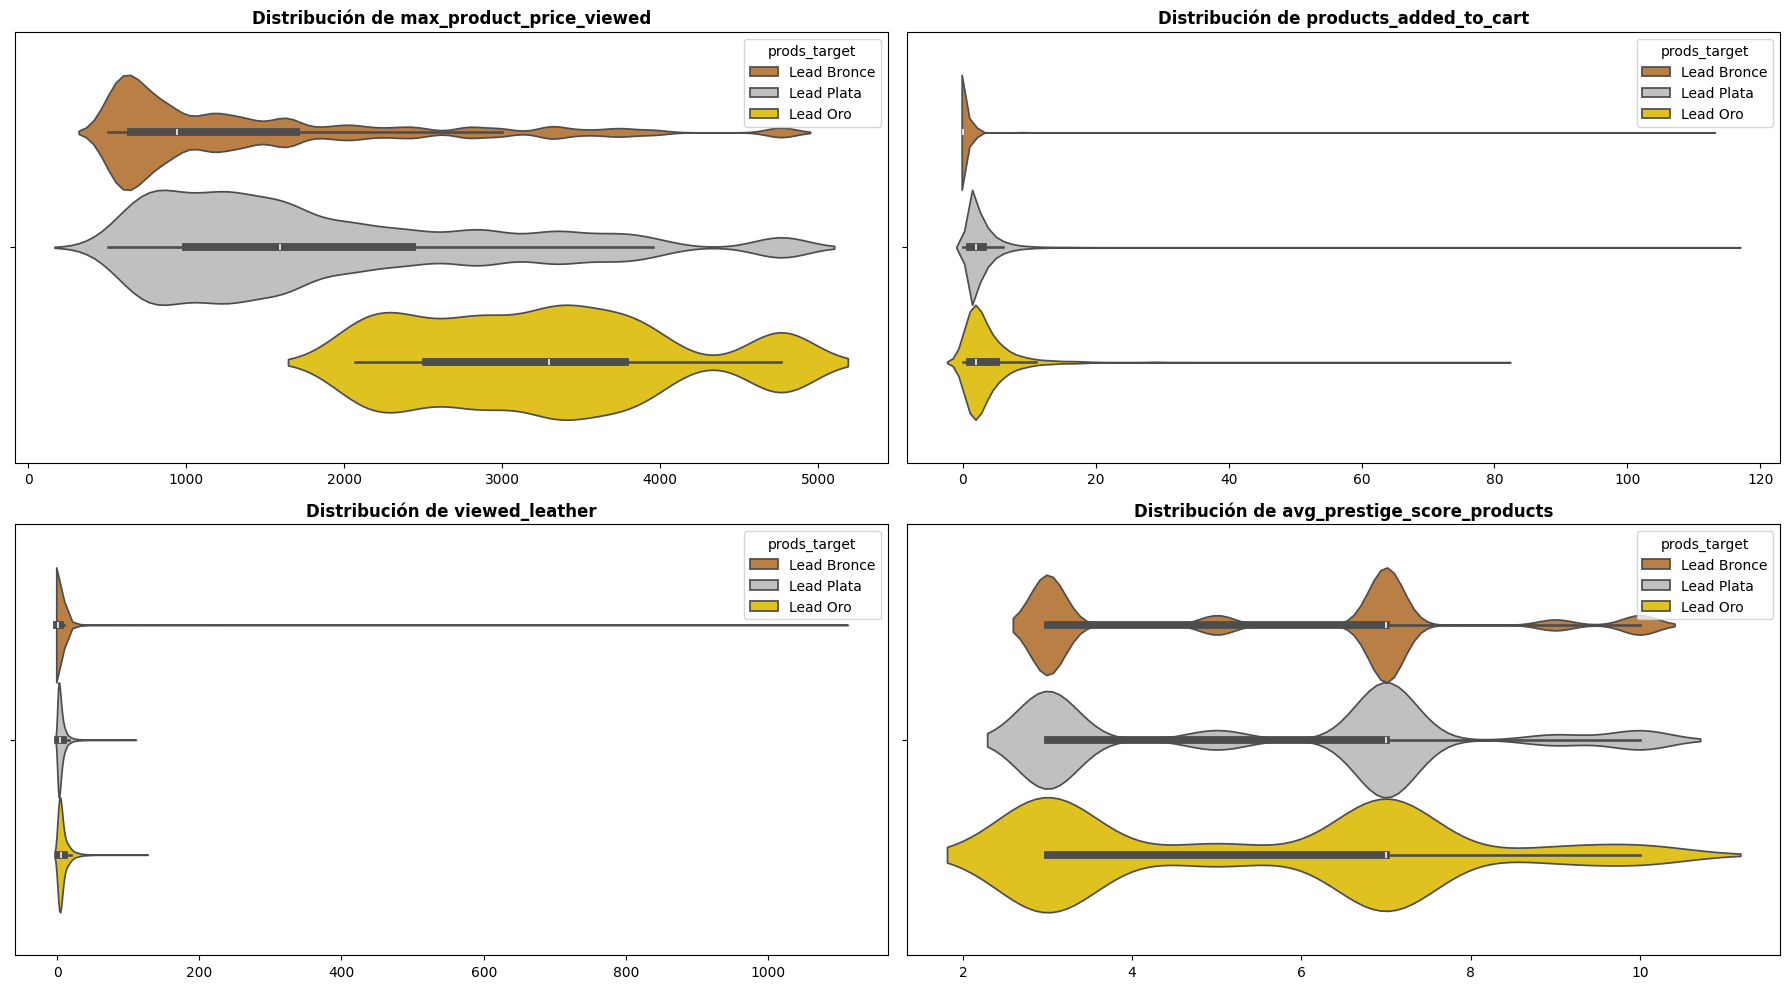

In [32]:
top_features = [
    'max_product_price_viewed', 
    'products_added_to_cart', 
    'viewed_leather', 
    'avg_prestige_score_products'
]

# Creamos una cuadrícula de 2 filas y 3 columnas
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten() # Aplanamos para iterar fácilmente

for i, col in enumerate(top_features):
    if col in df_final.columns:
        sns.violinplot(data=df_final, x=col, ax=axes[i], hue='prods_target', hue_order=leads, palette=colores)
        axes[i].set_title(f"Distribución de {col}", fontweight='bold')
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Los cuatro gráficos de violín de productos muestran:

- **`max_product_price_viewed`**: Mismo patrón que en caballos — los Leads de Oro miran productos más caros. La diferencia es menos pronunciada que en caballos, lo que tiene sentido: los productos ecuestre varían menos en precio que los caballos.

- **`products_added_to_cart`**: La separación entre Bronce y Plata/Oro es más marcada que en caballos. Un usuario que agrega productos al carrito casi siempre es al menos Lead Plata.
- **`viewed_leather`**: No se puede ver si hay una preferencia entre los leads más altos, por los outliers que se pueden ver en los leads de bronce. En el siguiente bloque de código vamos a observar más en detalle las características técnicas del producto y si afectan a los Leads.
- **`avg_prestige_score_products`**: Sin separación relevante entre clases, mismo caso que en caballos.

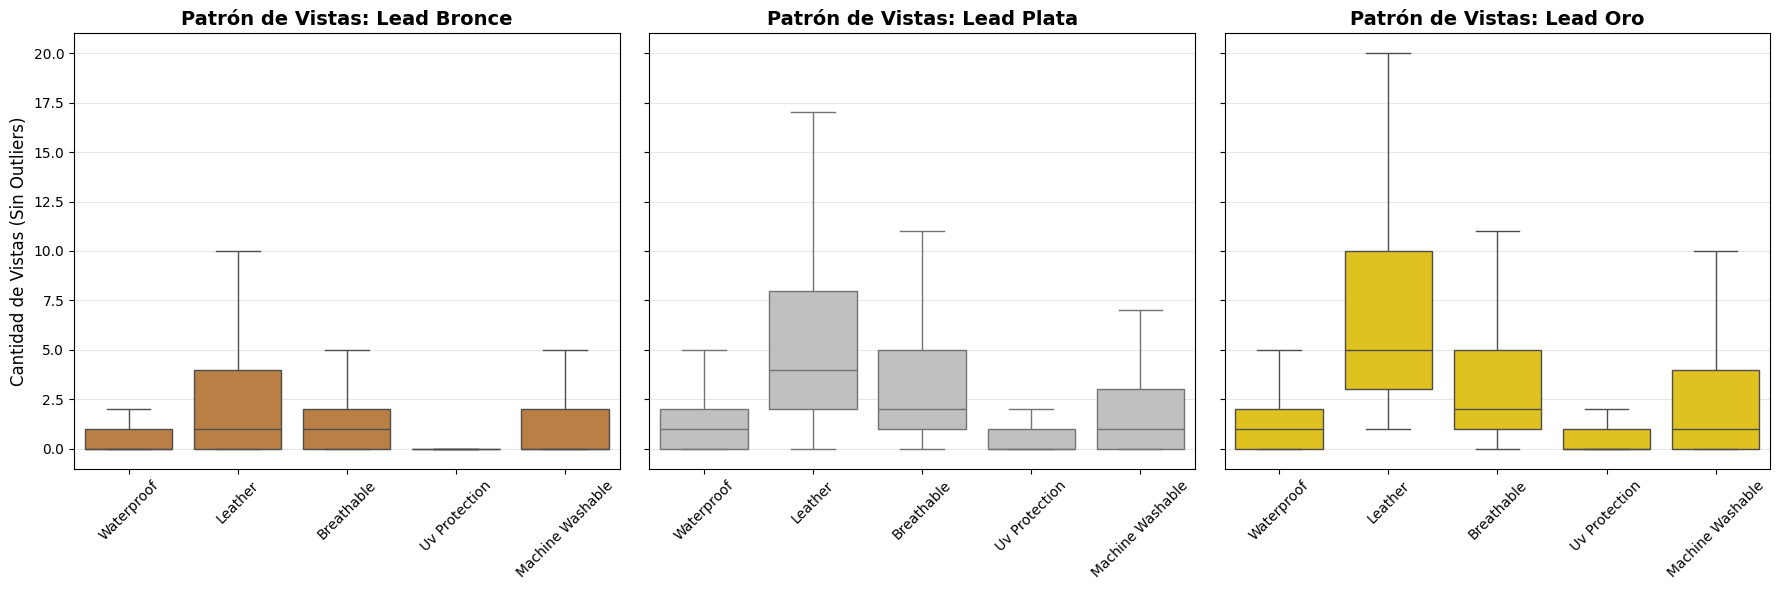

In [33]:
cols_vistas = [
    'viewed_waterproof', 
    'viewed_leather', 
    'viewed_breathable',
    "viewed_uv_protection",
    "viewed_machine_washable"
]

df_vistas = df_final[['prods_target'] + cols_vistas]
df_melted = pd.melt(
    df_vistas, 
    id_vars=['prods_target'], 
    value_vars=cols_vistas,
    var_name='Tipo_de_Producto', 
    value_name='Vistas'
)

df_melted['Tipo_de_Producto'] = df_melted['Tipo_de_Producto'].str.replace('viewed_', '').str.replace('_', ' ').str.title()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True) # sharey=True iguala el eje Y para que sean comparables

# Definimos el orden y los colores para cada panel
leads = ['Lead Bronce', 'Lead Plata', 'Lead Oro']
colores = ['#cd7f32', '#C0C0C0', '#FFD700'] 

# Bucle para dibujar cada gráfico
for i, lead in enumerate(leads):
    # Filtramos solo los datos del lead actual
    datos_lead = df_melted[df_melted['prods_target'] == lead]
    
    # Usamos boxplot ocultando outliers extremos para ver la "masa normal"
    sns.boxplot(
        data=datos_lead, 
        x='Tipo_de_Producto', 
        y='Vistas', 
        ax=axes[i],
        color=colores[i],
        showfliers=False 
    )
    
    # Diseño de cada panel
    axes[i].set_title(f"Patrón de Vistas: {lead}", fontsize=14, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45) 
    axes[i].set_xlabel("")
    axes[i].grid(axis='y', alpha=0.3)
    
    if i == 0:
        axes[i].set_ylabel("Cantidad de Vistas (Sin Outliers)", fontsize=12)
    else:
        axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Los Leads de Oro y Plata también tienden a ver más productos de cuero (*leather*), impermeables (*waterproof*) y transpirables (*breathable*), lo que sugiere un perfil de comprador más sofisticado e informado sobre equipamiento ecuestre.

#### Variables Binarias vs Targets

En este caso, cómo las variables binarias salen del dataset de caballos, vamos a comparar ambas únicamente con **horse_target**.

Las variables binarias `has_shipping_viewed` y `has_registry_viewed` indican si el usuario interactuó con caballos que ofrecen transporte o tienen registro de pedigree, respectivamente. Veremos si estos atributos discriminan entre los niveles de lead.

In [34]:
cols_binary = cols_binary[:2]
cols_binary

['has_registry_viewed', 'has_shipping_viewed']

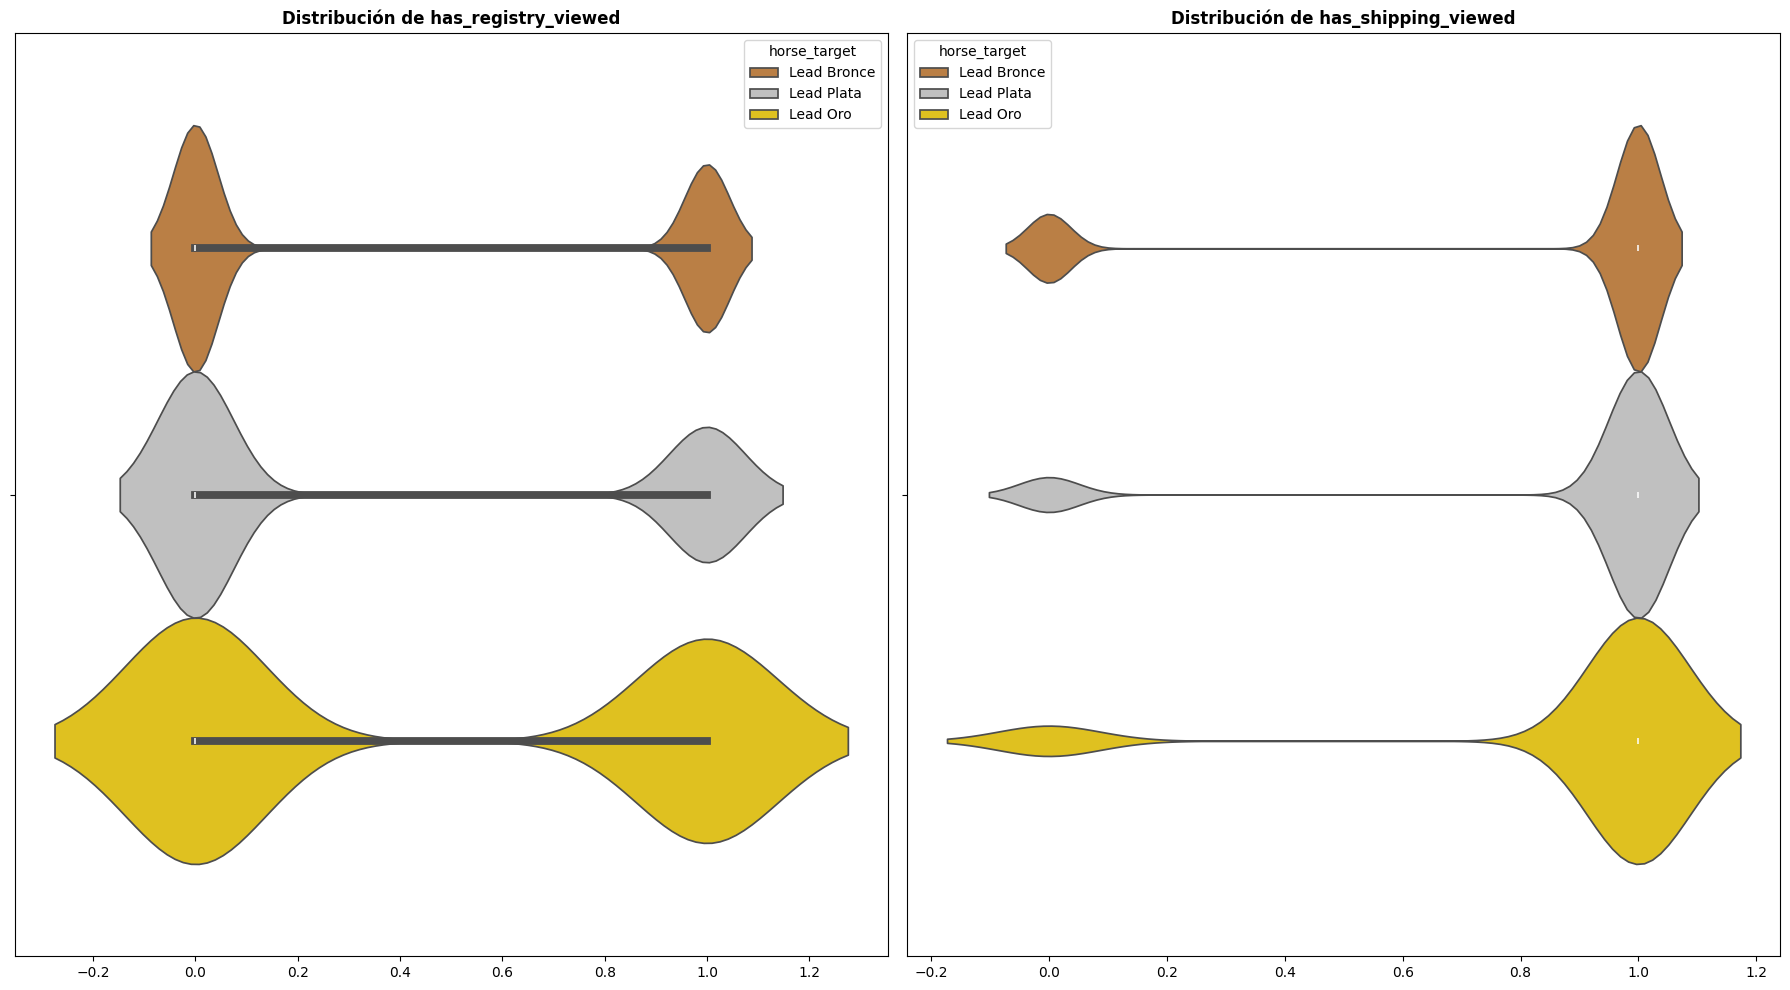

In [35]:
# Creamos una cuadrícula de 2 filas y 3 columnas
fig, axes = plt.subplots(1, 2, figsize=(18, 10))
axes = axes.flatten() # Aplanamos para iterar fácilmente

for i, col in enumerate(cols_binary):
    if col in df_final.columns:
        sns.violinplot(data=df_final, x=col, ax=axes[i], hue='horse_target', hue_order=leads, palette=colores)
        axes[i].set_title(f"Distribución de {col}", fontweight='bold')
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Los caballos con registro (*has_registry*) tienden a atraer más a Leads de Oro y Plata, lo que tiene sentido: un comprador serio prefiere caballos con pedigree verificado. El shipping también muestra una leve diferencia entre niveles.

#### Variable vs Variable

Analizamos relaciones entre variables para detectar comportamientos cruzados interesantes que pueden no ser capturados por el análisis univariado.

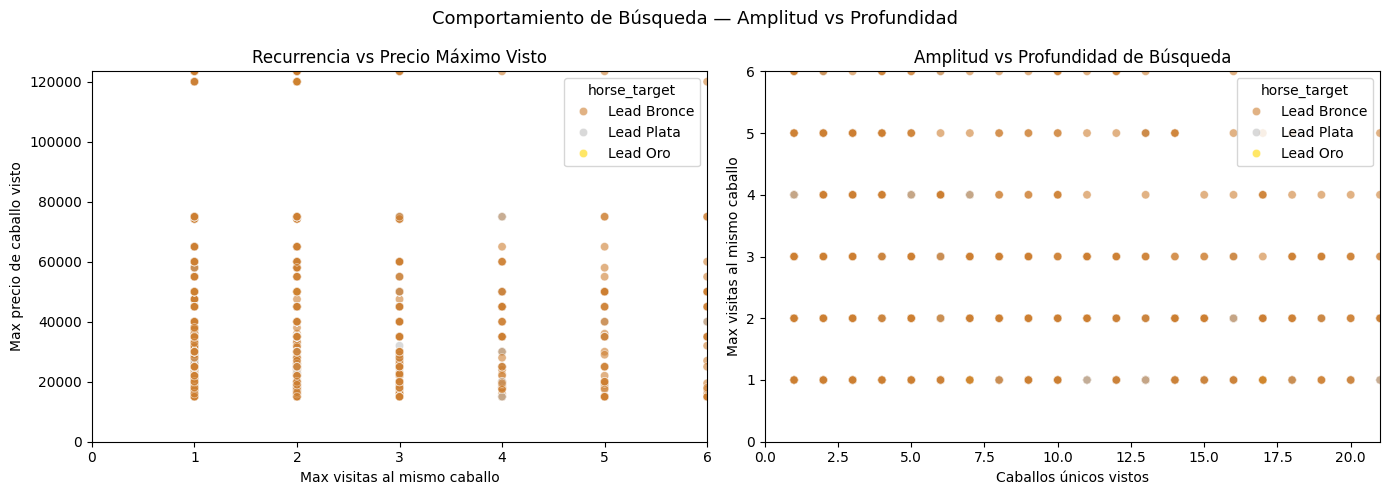

In [36]:
# Recurrencia vs Precio — ¿los que vuelven al mismo caballo buscan caballos más caros?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df_final.sample(5000, random_state=42),
    x='max_visitas_mismo_caballo', y='max_horse_price_viewed',
    hue='horse_target', hue_order=leads,
    palette=colores, alpha=0.6, ax=axes[0]
)
axes[0].set_title('Recurrencia vs Precio Máximo Visto')
axes[0].set_xlabel('Max visitas al mismo caballo')
axes[0].set_ylabel('Max precio de caballo visto')
axes[0].set_ylim(0, df_final['max_horse_price_viewed'].quantile(0.98))
axes[0].set_xlim(0, df_final['max_visitas_mismo_caballo'].quantile(0.98))

# Caballos únicos vs Max visitas — confirma la relación inversa
sns.scatterplot(
    data=df_final.sample(5000, random_state=42),
    x='caballos_unicos_vistos', y='max_visitas_mismo_caballo',
    hue='horse_target', hue_order=leads,
    palette=colores, alpha=0.6, ax=axes[1]
)
axes[1].set_title('Amplitud vs Profundidad de Búsqueda')
axes[1].set_xlabel('Caballos únicos vistos')
axes[1].set_ylabel('Max visitas al mismo caballo')
axes[1].set_xlim(0, df_final['caballos_unicos_vistos'].quantile(0.98))
axes[1].set_ylim(0, df_final['max_visitas_mismo_caballo'].quantile(0.98))

plt.suptitle('Comportamiento de Búsqueda — Amplitud vs Profundidad', fontsize=13)
plt.tight_layout()
plt.show()

El scatter de amplitud vs profundidad de búsqueda revela el patrón más interesante 
del dataset: los Leads de Oro tienden a concentrarse con pocos caballos únicos y 
muchas visitas al mismo, mientras que los Bronce dominan la zona de muchos caballos 
únicos y pocas visitas por caballo. Este patrón confirma que **la concentración de 
atención es la firma conductual del comprador real** en este marketplace — quien 
explora mucho sin volver es un curioso, quien vuelve al mismo anuncio va a comprar.

<Axes: xlabel='horses_viewed', ylabel='products_viewed'>

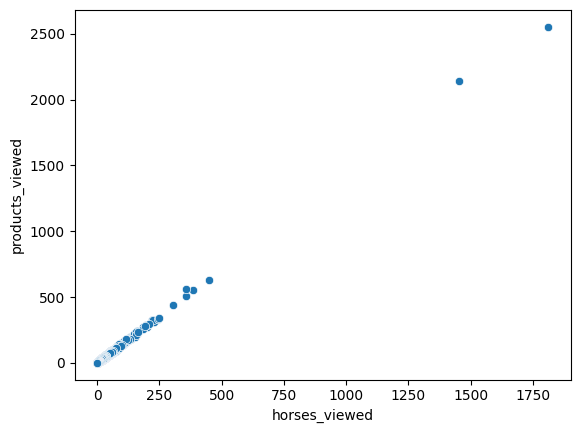

In [37]:
sns.scatterplot(data=df_final, x="horses_viewed", y="products_viewed")

La mayoría de los usuarios se concentra en el origen (0,0): solo vieron caballos O solo productos, no ambos. Hay una pequeña fracción con actividad en ambas dimensiones, que probablemente corresponde a los Leads de mayor calidad.

<Axes: xlabel='avg_horse_price_viewed', ylabel='avg_prestige_score_horses'>

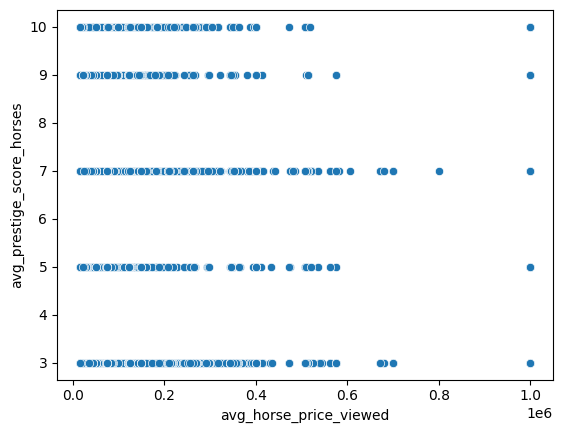

In [38]:
sns.scatterplot(data=df_final, x="avg_horse_price_viewed", y="avg_prestige_score_horses")

No se observa una correlación clara entre el precio promedio de los caballos vistos y el prestige score del usuario. Esto sugiere que el poder adquisitivo del lead (inferido por su cargo) no predice directamente el rango de precios que explora.

<Axes: xlabel='avg_height', ylabel='avg_weight'>

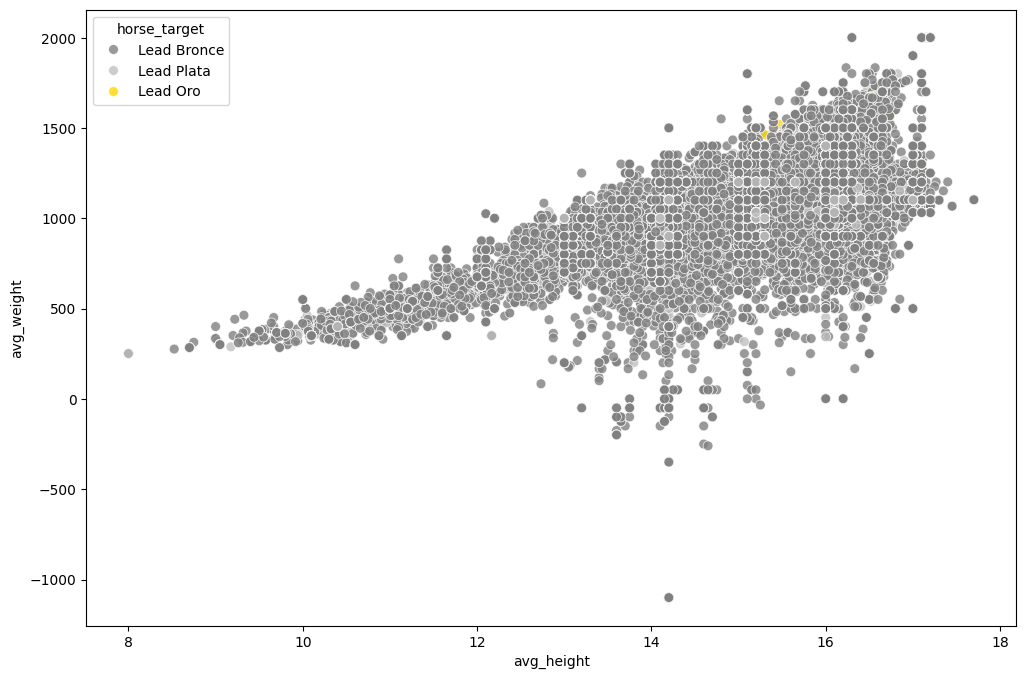

In [39]:
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_final, x='avg_height', y='avg_weight', hue='horse_target', hue_order=["Lead Bronce", "Lead Plata", "Lead Oro"], alpha=0.8, s=50, palette=['#808080', '#C0C0C0', '#FFD700'])

La relación altura/peso de los caballos vistos muestra la distribución física típica del mercado ecuestre. Los tres tipos de lead están distribuidos de forma similar, lo que indica que estas variables físicas probablemente no sean predictores fuertes del nivel de lead por sí solas.

In [40]:
print('Variables con mayor poder discriminativo:')
print('  Caballos  → max_horse_price_viewed, horses_added_to_cart, max_visitas_mismo_caballo,')
print('              ratio_recurrencia_horse, viewed_sport_elite, caballos_unicos_vistos')
print('  Productos → products_added_to_cart, max_product_price_viewed, viewed_leather,')
print('              ratio_recurrencia_prods, max_visitas_mismo_producto')
print()
print('Variables con bajo poder discriminativo:')
print('  avg_height, avg_weight, avg_temperament, avg_prestige_score_horses,')
print('  avg_prestige_score_products, user_antiguedad_dias (sola)')
print()
print('Variables con señal moderada (a confirmar por feature importance)')
print('  viewed_working_elite, avg_tech_score, user_card_issuer, user_prestige_score')

Variables con mayor poder discriminativo:
  Caballos  → max_horse_price_viewed, horses_added_to_cart, max_visitas_mismo_caballo,
              ratio_recurrencia_horse, viewed_sport_elite, caballos_unicos_vistos
  Productos → products_added_to_cart, max_product_price_viewed, viewed_leather,
              ratio_recurrencia_prods, max_visitas_mismo_producto

Variables con bajo poder discriminativo:
  avg_height, avg_weight, avg_temperament, avg_prestige_score_horses,
  avg_prestige_score_products, user_antiguedad_dias (sola)

Variables con señal moderada (a confirmar por feature importance)
  viewed_working_elite, avg_tech_score, user_card_issuer, user_prestige_score


### Correlación

In [41]:
correlation_matrix = df_final.corr(numeric_only=True)

In [42]:
correlation_matrix

,horses_viewed,horses_added_to_cart,avg_horse_price_viewed,max_horse_price_viewed,min_horse_price_viewed,viewed_premium_horses,viewed_sport_elite,viewed_family_safe,avg_horse_age,viewed_pro_sellers,...,max_visitas_mismo_producto,total_views,total_cart_adds,ratio_cart_horse,ratio_cart_prods,ratio_cart_global,rango_precio_horse,prestige_gap,ratio_horse_views,has_both_interests
horses_viewed,1.000000,0.114839,-0.000147,0.109406,-0.066865,0.266719,0.839497,0.845309,0.000689,0.936355,...,0.749530,0.998033,0.113030,-0.021203,-0.023768,-0.027249,0.135586,NaN,0.312336,0.024594
horses_added_to_cart,0.114839,1.000000,-0.003243,0.042522,-0.037274,0.063869,0.263597,0.134683,-0.006624,0.254997,...,0.109604,0.114341,0.989838,0.743916,0.644858,0.588512,0.056345,NaN,0.091328,-0.055380
avg_horse_price_viewed,-0.000147,-0.003243,1.000000,0.736776,0.764422,0.255537,0.000048,0.017347,0.085671,-0.012176,...,0.000008,-0.000294,-0.003233,-0.000031,0.000604,0.001663,0.520415,NaN,0.001859,-0.009227
max_horse_price_viewed,0.109406,0.042522,0.736776,1.000000,0.281662,0.379802,0.119944,0.098014,0.093658,0.081917,...,0.104808,0.108408,0.041941,0.018308,0.014684,0.012530,0.950680,NaN,0.093690,0.002116
min_horse_price_viewed,-0.066865,-0.037274,0.764422,0.281662,1.000000,0.073405,-0.064076,-0.050596,0.049939,-0.069072,...,-0.076691,-0.066481,-0.036707,-0.022780,-0.017553,-0.013800,-0.029845,NaN,-0.103463,-0.018322
viewed_premium_horses,0.266719,0.063869,0.255537,0.379802,0.073405,1.000000,0.203726,0.223495,0.028602,0.247584,...,0.219101,0.264700,0.063030,0.009130,0.005738,0.003541,0.371922,NaN,0.123454,0.006601
viewed_sport_elite,0.839497,0.263597,0.000048,0.119944,-0.064076,0.203726,1.000000,0.582335,0.002224,0.859686,...,0.646177,0.837481,0.259599,0.096340,0.077499,0.065414,0.145662,NaN,0.302625,0.016003
viewed_family_safe,0.845309,0.134683,0.017347,0.098014,-0.050596,0.223495,0.582335,1.000000,0.012708,0.773661,...,0.620702,0.844072,0.133816,0.020654,0.014347,0.008724,0.118459,NaN,0.236805,0.014453
avg_horse_age,0.000689,-0.006624,0.085671,0.093658,0.049939,0.028602,0.002224,0.012708,1.000000,-0.011407,...,-0.000193,0.000687,-0.006201,-0.007293,-0.006085,-0.006452,0.081423,NaN,0.001946,0.003937
viewed_pro_sellers,0.936355,0.254997,-0.012176,0.081917,-0.069072,0.247584,0.859686,0.773661,-0.011407,1.000000,...,0.709972,0.934240,0.251343,0.081583,0.063743,0.052647,0.107664,NaN,0.310219,0.017150


<Axes: >

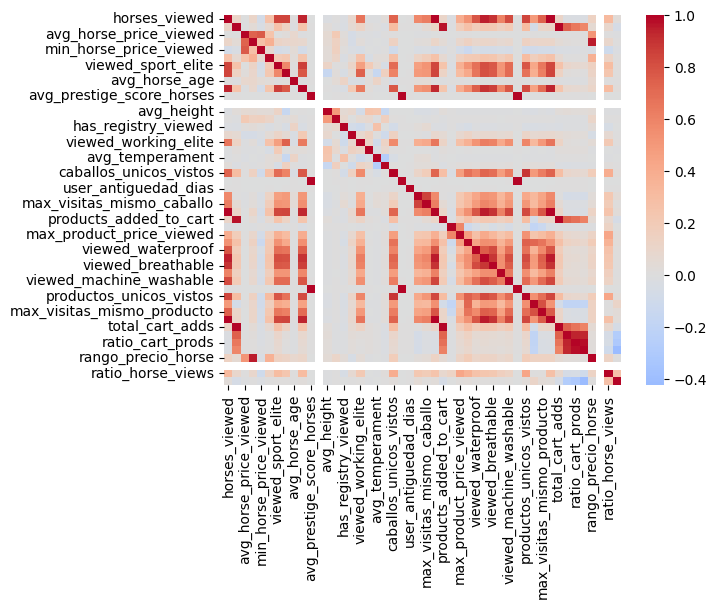

In [43]:
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", center=0)

Viendo que es difícil extraer correlaciones de tantas columnas, vamos a observar las correlaciones solo con los targets y también vemos correlaciones mayores a 0.50 (o menores a -0.50) para detectar columnas que pueden llegar a ser eliminadas.

Si detectamos 2 columnas con correlación alta (>0.80) entre ellas, luego vemos cuál de las dos tiene mayor correlación con los targets para ver cuál eliminamos.

Generamos la matriz de correlación sobre el dataset final (todas las features numéricas, incluyendo los targets mapeados a 0/1/2)

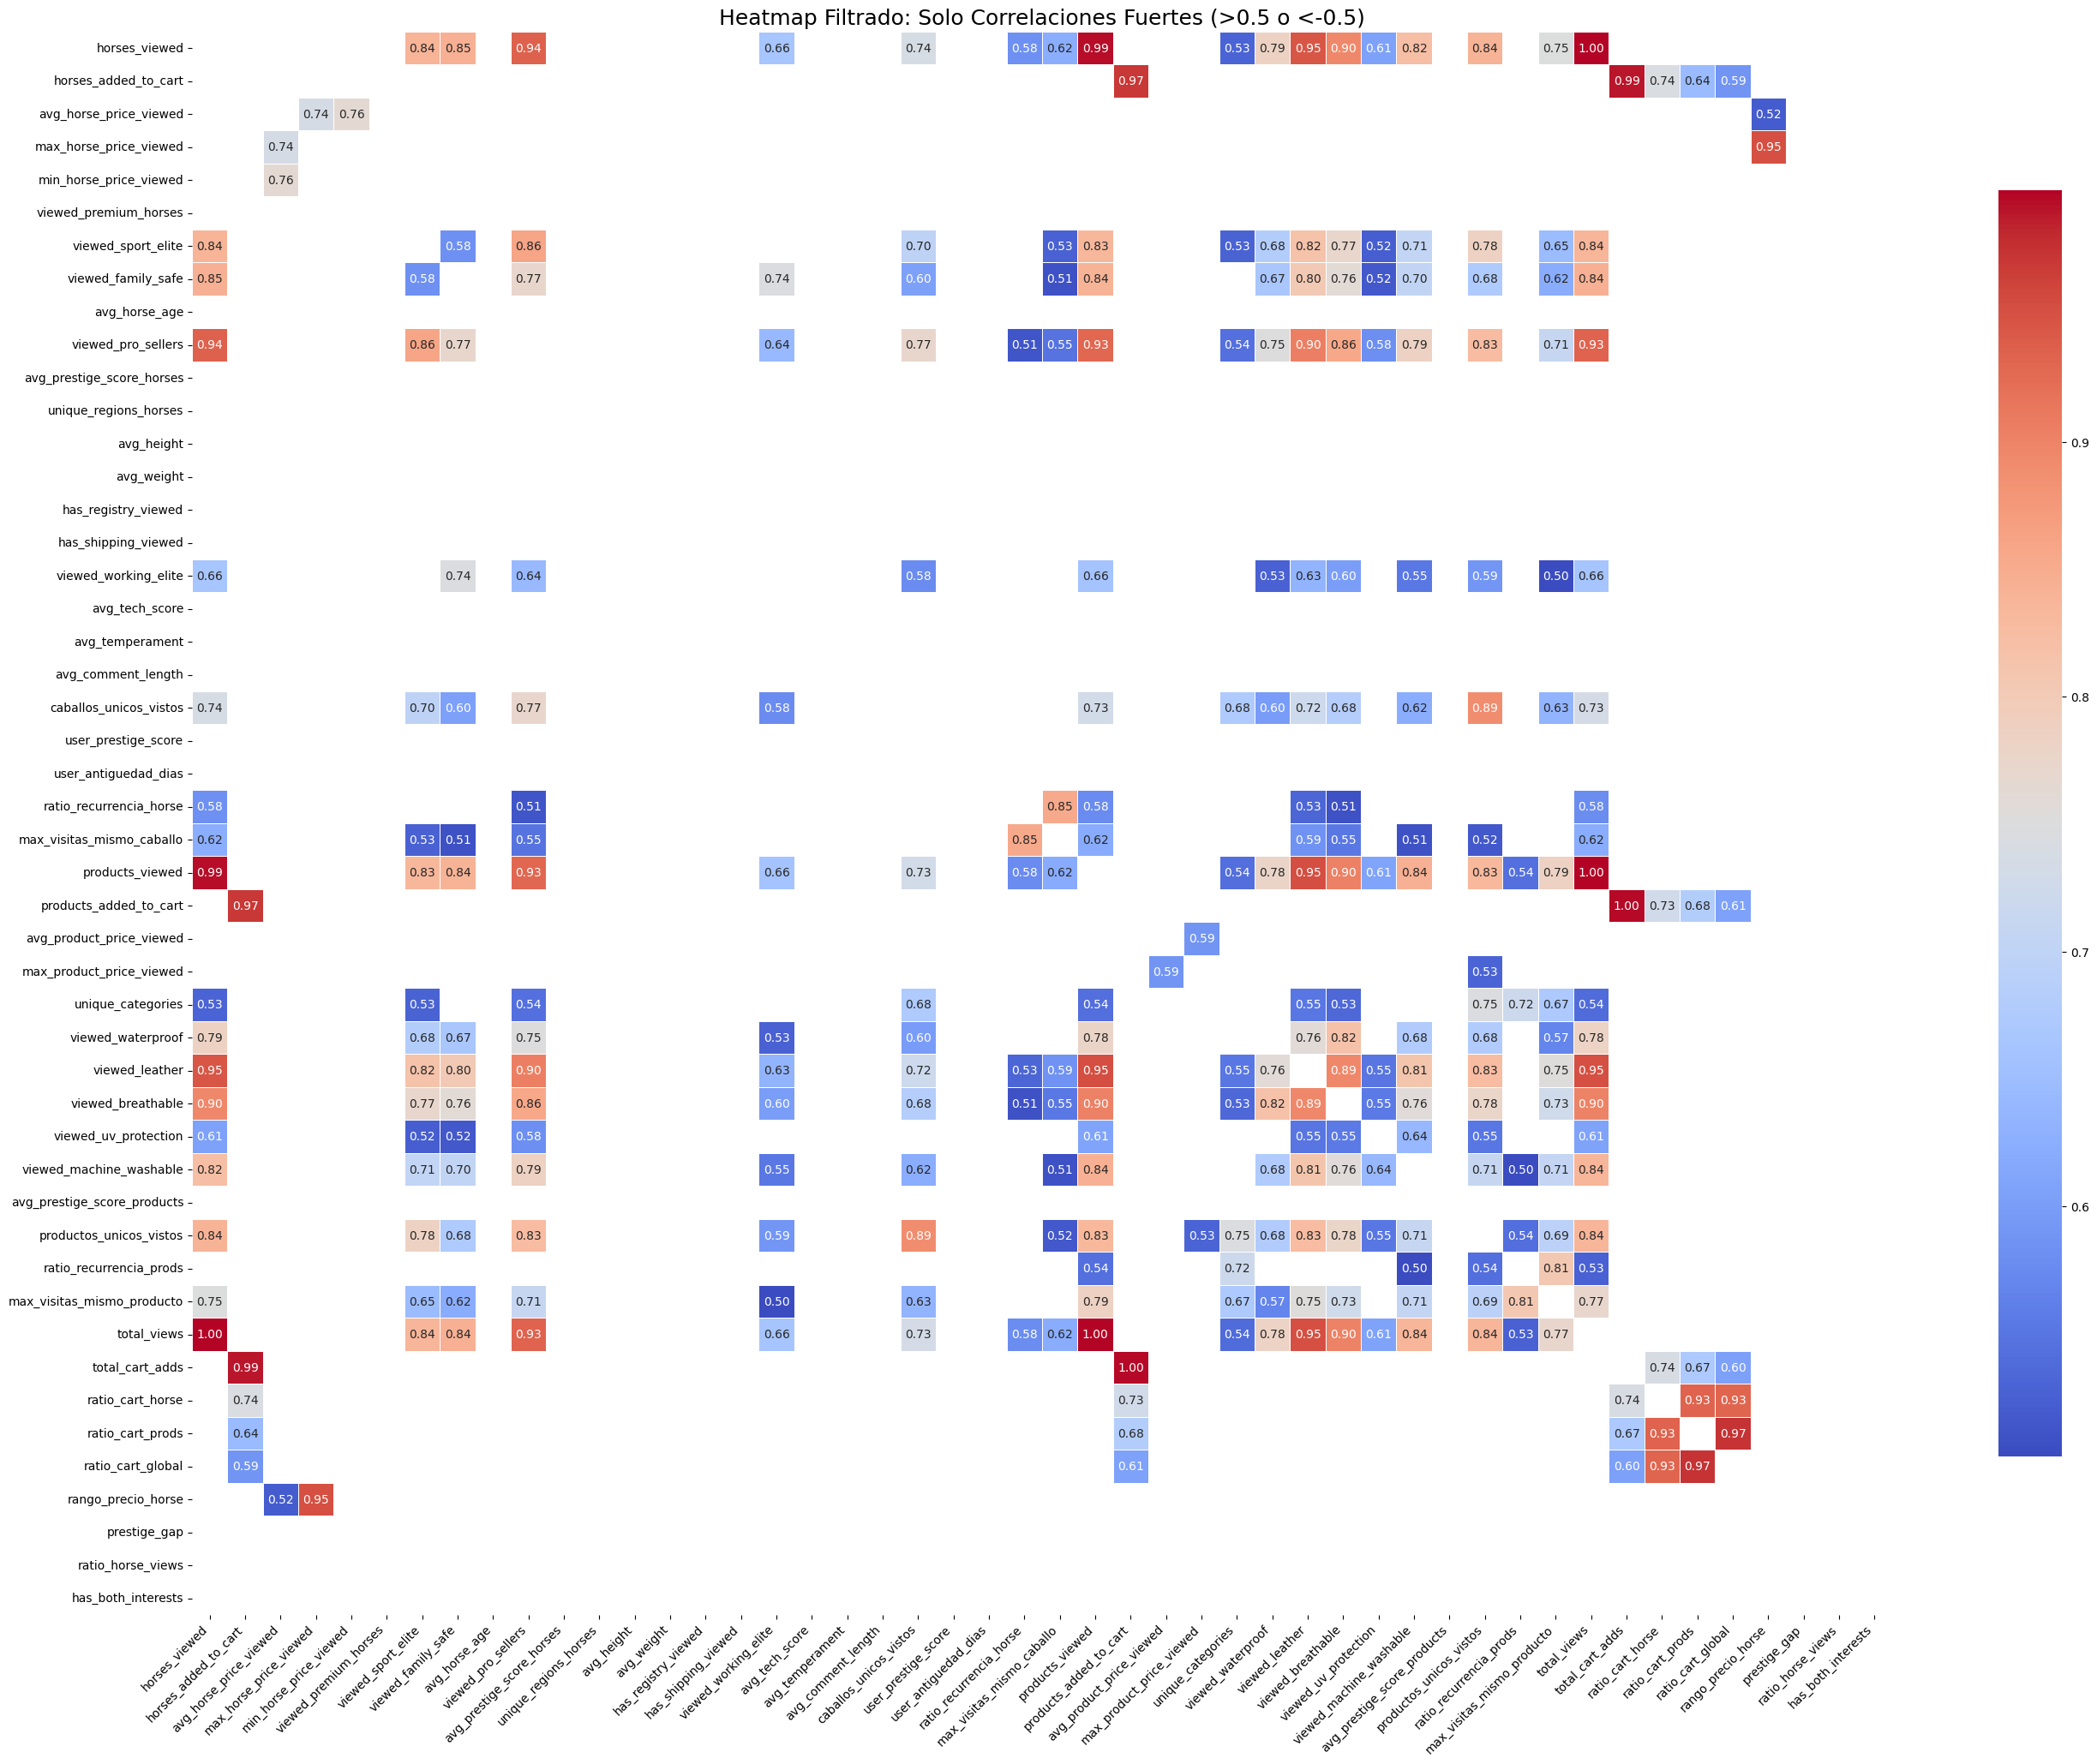

In [44]:
plt.figure(figsize=(32, 24))

corr = df_final.corr(numeric_only=True)

corr_fuerte = corr[((corr >= 0.5) | (corr <= -0.5)) & (corr != 1.000)]

sns.heatmap(
    corr_fuerte, 
    annot=True,       
    fmt=".2f",        
    cmap="coolwarm",  
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title("Heatmap Filtrado: Solo Correlaciones Fuertes (>0.5 o <-0.5)", fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.show()

Del heatmap filtrado (correlaciones > 0.5 o < -0.5) se identifican los siguientes 
grupos con el dataset completo:

- **Vistas globales** (~0.99): `total_views`, `horses_viewed` y `products_viewed` 
  son prácticamente la misma variable — `total_views` es combinación lineal exacta de 
  los otros dos.

- **Vistas de atributos de caballos y productos** (~0.77–0.94 con `horses_viewed`): 
  `viewed_pro_sellers`, `viewed_sport_elite`, `viewed_family_safe`, `viewed_leather`, 
  `viewed_breathable`, `viewed_machine_washable`, `productos_unicos_vistos` y 
  `max_visitas_mismo_producto` correlacionan fuerte con `horses_viewed`. Esto indica 
  que todas escalan con el volumen de actividad del usuario — quien más caballos ve, 
  más de todo ve. El riesgo de redundancia es alto y se evaluará con feature importance.

- **Carritos** (~0.99): `total_cart_adds` es redundante respecto a 
  `horses_added_to_cart` y `products_added_to_cart` juntos.

- **Ratios de carrito** (~0.93–0.97): `ratio_cart_horse`, `ratio_cart_prods` y 
  `ratio_cart_global` miden casi lo mismo — la proporción de carritos sobre vistas. 
  `ratio_cart_global` es el más redundante de los tres.

- **Precios de caballos** (~0.52–0.95): `rango_precio_horse` y `max_horse_price_viewed` 
  correlacionan 0.951 — el rango está casi determinado por el máximo. 
  `avg_horse_price_viewed` y `min_horse_price_viewed` correlacionan 0.764.

- **Recurrencia de productos** (0.80): `ratio_recurrencia_prods` y 
  `max_visitas_mismo_producto` miden aspectos similares del mismo comportamiento.

La decisión de qué features conservar se tomará **después del modelado** usando 
feature importance — no eliminamos features por correlación en este punto.

Veamos de eliminar las columnas que menos correlación tengan con ambos targets luego.

Ahora veamos la correlación entre las variables categóricas y los targets

In [45]:
from scipy.stats.contingency import association

In [46]:
for var in categorical_cols[2:]:
    
    serie_var = df_final[var]
    if isinstance(serie_var, pd.DataFrame):
        serie_var = serie_var.iloc[:, 0]
        
    # Bucle para evaluar la misma variable contra ambos targets
    for target in targets:
        serie_target = df_final[target]
        if isinstance(serie_target, pd.DataFrame):
            serie_target = serie_target.iloc[:, 0]
            
        df_temp = pd.DataFrame({'Variable': serie_var, 'Target': serie_target}).dropna()
        
        # Hacemos el crosstab
        tabla_contingencia = pd.crosstab(df_temp['Variable'], df_temp['Target'])
        
        # Calculamos la V de Cramér
        cramer_v = association(tabla_contingencia, method="cramer")
        
        print(f" {var} vs {target}: {cramer_v:.4f}")
        
    print("-" * 60)

 gender_with_most_appearances vs horse_target: 0.0499
 gender_with_most_appearances vs prods_target: 0.0479
------------------------------------------------------------
 breedFamily_with_most_appearances vs horse_target: 0.0517
 breedFamily_with_most_appearances vs prods_target: 0.0323
------------------------------------------------------------
 color_grouped_with_most_appearances vs horse_target: 0.0454
 color_grouped_with_most_appearances vs prods_target: 0.0401
------------------------------------------------------------
 user_region vs horse_target: 0.0055
 user_region vs prods_target: 0.0050
------------------------------------------------------------
 user_card_issuer vs horse_target: 0.0059
 user_card_issuer vs prods_target: 0.0077
------------------------------------------------------------
 user_domain vs horse_target: 0.0039
 user_domain vs prods_target: 0.0057
------------------------------------------------------------
 most_viewed_category vs horse_target: 0.0627
 most_vi

Podemos ver que las variables categóricas tienen bajísima correlación con los targets según Cramér's V. Sin embargo, en lugar de eliminarlas directamente, aplicamos **Target Encoding** a las categóricas que tienen cierto potencial de señal (`user_region`, `user_card_issuer`, `user_domain`, `gender_mode`, `breed_family_mode`, `color_mode`). Esto nos permite conservar la información sin explotar el número de columnas como haría OHE.

El encoding se calcula **solo sobre X_train** para evitar data leakage.

In [47]:
# Categóricas que conservamos para Target Encoding (fit sobre X_train)
COLS_TARGET_ENCODE = [c for c in [
    # Perfil del usuario 
    'user_region', 'user_card_issuer', 'user_domain',
    # Características del caballo más visto
    'gender_mode', 'breed_family_mode', 'color_mode',
    # Características del producto más visto
    'most_viewed_category', 'most_viewed_brand', 'most_viewed_target_user',
] if c in df_final.columns]

# Dropeamos las demás categóricas (bajísima correlación y no se van a encodear)
cols_drop_cat = [c for c in categorical_cols[2:] if c not in COLS_TARGET_ENCODE]
print('Columnas con Target Encoding:', COLS_TARGET_ENCODE)
print('Columnas dropeadas:', cols_drop_cat)


Columnas con Target Encoding: ['user_region', 'user_card_issuer', 'user_domain', 'most_viewed_category', 'most_viewed_brand', 'most_viewed_target_user']
Columnas dropeadas: ['gender_with_most_appearances', 'breedFamily_with_most_appearances', 'color_grouped_with_most_appearances']


In [48]:
df_final = df_final.drop(columns=cols_drop_cat, errors='ignore')

In [49]:
grupos_colineales = {
    "Vistas Globales (Corr 0.994 - 0.999)": [
        'total_views',
        'horses_viewed',
        'products_viewed',
    ],
    "Vistas de Atributos de Caballos (Corr 0.774 - 0.936)": [
        'horses_viewed',
        'viewed_pro_sellers',
        'viewed_sport_elite',
        'viewed_family_safe',
        'viewed_machine_washable',
        'viewed_breathable',
        'viewed_leather',
        'productos_unicos_vistos',
        'caballos_unicos_vistos',
        'max_visitas_mismo_producto',
    ],
    "Carritos (Corr 0.990 - 0.995)": [
        'total_cart_adds',
        'horses_added_to_cart',
        'products_added_to_cart',
    ],
    "Ratios de Carrito (Corr 0.932 - 0.975)": [
        'ratio_cart_horse',
        'ratio_cart_prods',
        'ratio_cart_global',
    ],
    "Precios de Caballos (Corr 0.520 - 0.951)": [
        'max_horse_price_viewed',
        'avg_horse_price_viewed',
        'min_horse_price_viewed',
        'rango_precio_horse',
    ],
    "Recurrencia de Productos (Corr 0.805)": [
        'ratio_recurrencia_prods',
        'max_visitas_mismo_producto',
    ],
}

Identificamos grupos de variables con alta correlación entre sí. Esta información es **solo exploratoria** — la documentamos para entender la estructura del dataset. La decisión de qué features conservar la vamos a tomar **después del modelado**, usando **feature importance**  en lugar de correlación. Así nos basamos en lo que el modelo realmente usa, no en métricas estadísticas simples.

Luego de analizar las correlaciones entre variables y con los targets, registramos las variables candidatas a ser ruido (correlación < 0.05 con ambos targets). Igual que con la colinealidad, **no las eliminamos acá** — esto es solo documentación exploratoria.

**Nota:** El análisis de ruido a continuación es **exploratorio**. No se van a dropear features en base a este análisis — la selección final se hará con feature importance del modelo entrenado, que es más robusta que la correlación para capturar relaciones no lineales.

In [50]:
umbral_ruido = 0.05
columnas_ruido_pearson = []
columnas_ruido_spearman = []

for var in numeric_cols[:-1]:
    # Calculamos correlación absoluta
    corr_horse_pearson = abs(df_final[var].corr(df_final['horse_target'].map({"Lead Bronce": 0, "Lead Plata": 1, "Lead Oro": 2})))
    corr_prods_pearson = abs(df_final[var].corr(df_final['prods_target'].map({"Lead Bronce": 0, "Lead Plata": 1, "Lead Oro": 2})))

    corr_horse_spearman = abs(df_final[var].corr(df_final['horse_target'].map({"Lead Bronce": 0, "Lead Plata": 1, "Lead Oro": 2}), method="spearman"))
    corr_prods_spearman = abs(df_final[var].corr(df_final['prods_target'].map({"Lead Bronce": 0, "Lead Plata": 1, "Lead Oro": 2}), method="spearman"))
    
    if corr_horse_pearson < umbral_ruido and corr_prods_pearson < umbral_ruido:
        if var not in columnas_ruido_pearson:
            columnas_ruido_pearson.append(var)
    if corr_horse_spearman < umbral_ruido and corr_prods_spearman < umbral_ruido:
        if var not in columnas_ruido_spearman:
            columnas_ruido_spearman.append(var)

print(f'Features candidatas a ruido (Pearson):  {len(columnas_ruido_pearson)}')
print(f'Features candidatas a ruido (Spearman): {len(columnas_ruido_spearman)}')

/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/alumni/Programació

Features candidatas a ruido (Pearson):  20
Features candidatas a ruido (Spearman): 14


/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/alumni/Programació

In [51]:
# Lista de features candidatas a ruido (documentación exploratoria)
print('Pearson:', columnas_ruido_pearson)
print('Spearman:', columnas_ruido_spearman)

Pearson: ['horses_viewed', 'avg_horse_price_viewed', 'max_horse_price_viewed', 'min_horse_price_viewed', 'avg_horse_age', 'avg_prestige_score_horses', 'avg_height', 'avg_weight', 'has_registry_viewed', 'avg_tech_score', 'avg_temperament', 'avg_comment_length', 'user_prestige_score', 'user_antiguedad_dias', 'ratio_recurrencia_horse', 'max_visitas_mismo_caballo', 'products_viewed', 'avg_product_price_viewed', 'avg_prestige_score_products', 'total_views']
Spearman: ['avg_horse_price_viewed', 'viewed_premium_horses', 'avg_horse_age', 'avg_prestige_score_horses', 'avg_height', 'avg_weight', 'has_registry_viewed', 'avg_tech_score', 'avg_temperament', 'avg_comment_length', 'user_prestige_score', 'user_antiguedad_dias', 'max_visitas_mismo_caballo', 'avg_prestige_score_products']


### Detección Outliers

In [52]:
Q1 = df_final['horses_viewed'].quantile(0.25)
Q3 = df_final['horses_viewed'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df_final[(df_final['horses_viewed'] < lower_bound) | (df_final['horses_viewed'] > upper_bound)]
print(f"Cantidad de outliers en 'horses_viewed': {len(outliers)}")
percentage_outliers_iqr = (len(outliers) / len(df_final)) * 100
print(f"Porcentaje de outliers detectados por IQR: {percentage_outliers_iqr:.2f}%")

Cantidad de outliers en 'horses_viewed': 18471
Porcentaje de outliers detectados por IQR: 9.55%


In [53]:
distribucion = outliers["horse_target"].value_counts()
porcentaje = outliers["horse_target"].value_counts(normalize=True) * 100

resumen_outliers = pd.DataFrame({
    'Cantidad de Usuarios': distribucion,
    '% Dentro del grupo Outlier': porcentaje
})

print(resumen_outliers)

              Cantidad de Usuarios  % Dentro del grupo Outlier
horse_target                                                  
Lead Bronce                  16719                   90.514861
Lead Plata                    1650                    8.932922
Lead Oro                       102                    0.552217


Podemos ver que los leads bronce vieron demasiados caballos, este outlier puede tener que ver con aquellos usuarios que compartían comportamiento de bots.
  
Vamos a tener que tratar estos outliers luego para no sesgar al modelo.

Busquemos todos los outliers que podemos encontrar en cada columna del dataset, y las vamos a tratar luego del split en el modelado.

In [54]:
# Detección automática de outliers por IQR en todas las features numéricas

print(f'{"Feature":<35} {"P99":>10} {"Max":>12} {"Ratio P99/Max":>14}')
print('─' * 75)

features_con_cola = []
for col in df_final.select_dtypes(include='number').columns:
    p99  = df_final[col].quantile(0.99)
    vmax = df_final[col].max()
    if p99 > 0:
        ratio = vmax / p99
        if ratio > 2:  
            features_con_cola.append(col)
            print(f'{col:<35} {p99:>10.2f} {vmax:>12.2f} {ratio:>14.1f}x')

print(f'\nFeatures con cola extrema detectadas: {len(features_con_cola)}')

Feature                                    P99          Max  Ratio P99/Max
───────────────────────────────────────────────────────────────────────────
horses_viewed                            35.00      1811.00           51.7x
horses_added_to_cart                      4.00        81.00           20.2x
avg_horse_price_viewed               123456.00   1000000.00            8.1x
max_horse_price_viewed               400000.00   1000000.00            2.5x
min_horse_price_viewed                65000.00   1000000.00           15.4x
viewed_premium_horses                     3.00        47.00           15.7x
viewed_sport_elite                       21.00       639.00           30.4x
viewed_family_safe                       17.00       912.00           53.6x
viewed_pro_sellers                       27.00      1234.00           45.7x
viewed_working_elite                     10.00       286.00           28.6x


avg_comment_length                      418.00      1298.00            3.1x
caballos_unicos_vistos                   27.00       235.00            8.7x
ratio_recurrencia_horse                   3.50       258.71           73.9x
max_visitas_mismo_caballo                 9.00       322.00           35.8x
products_viewed                          50.00      2554.00           51.1x
products_added_to_cart                    6.00       116.00           19.3x
viewed_waterproof                         5.00       196.00           39.2x
viewed_leather                           25.00      1111.00           44.4x
viewed_breathable                        14.00       630.00           45.0x
viewed_uv_protection                      4.00        96.00           24.0x
viewed_machine_washable                  11.00       451.00           41.0x
productos_unicos_vistos                  28.00       177.00            6.3x
ratio_recurrencia_prods                   2.00        14.35            7.2x
max_visitas_

## Modelado

### Preprocesamiento

Empecemos el preprocesamiento: primero el train/test split, luego el capping de outliers y el balanceo de clases. **No vamos a dropear features por correlación** — esa decisión la tomamos después del primer entrenamiento usando feature importance.

In [55]:
from sklearn.model_selection import train_test_split

Antes de hacer el split, eliminamos los casos inconsistentes del dataset: usuarios clasificados como Lead Oro en caballos pero Lead Bronce en productos. Son solo 1-2 filas que representan anomalías en la definición del target (un usuario que compró un caballo pero nunca compró productos).

In [56]:
X = df_final.drop(columns=["horse_target", "prods_target"])
y = df_final[["horse_target", "prods_target"]]

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y,test_size=0.2, random_state=42)

#### Target Encoding — categóricas de usuario y caballo

Aplicamos Target Encoding (con suavizado `smoothing=10`) a las 6 categóricas conservadas. El encoder se **fittea solo sobre X_train** usando `horse_target` como referencia ordinal (Bronce=0, Plata=1, Oro=2). El suavizado estabiliza categorías con pocas muestras acercándolas a la media global en lugar de sobreajustarse. El mismo encoder ya fitteado se aplica a X_test sin reentrenar.

In [58]:
from category_encoders import TargetEncoder

# Referencia ordinal: horse_target (más discriminativo entre targets)
target_ord = y_train['horse_target'].map({'Lead Bronce': 0, 'Lead Plata': 1, 'Lead Oro': 2})

# Filtramos solo las que efectivamente están en X_train
cols_te = [c for c in COLS_TARGET_ENCODE if c in X_train.columns]

te = TargetEncoder(cols=cols_te, smoothing=10)
X_train[cols_te] = te.fit_transform(X_train[cols_te], target_ord)
X_test[cols_te]  = te.transform(X_test[cols_te])

print(f'Target Encoding aplicado a {len(cols_te)} columnas: {cols_te}')
print(f'Shape X_train post-TE: {X_train.shape}')

Target Encoding aplicado a 6 columnas: ['user_region', 'user_card_issuer', 'user_domain', 'most_viewed_category', 'most_viewed_brand', 'most_viewed_target_user']
Shape X_train post-TE: (154692, 54)


In [59]:
target_horse_num = y_train['horse_target'].map({"Lead Bronce": 0, "Lead Plata": 1, "Lead Oro": 2})
target_prods_num = y_train['prods_target'].map({"Lead Bronce": 0, "Lead Plata": 1, "Lead Oro": 2})

Registramos las columnas colineales identificadas en el EDA como referencia, pero no las eliminamos antes del primer entrenamiento.  
La selección de features la hacemos con feature importance después del modelado.

In [60]:
columnas_colineales_doc = {}
for nombre_grupo, variables in grupos_colineales.items():
    columnas_colineales_doc[nombre_grupo] = variables
    print(f'{nombre_grupo}: {variables}')

Vistas Globales (Corr 0.994 - 0.999): ['total_views', 'horses_viewed', 'products_viewed']
Vistas de Atributos de Caballos (Corr 0.774 - 0.936): ['horses_viewed', 'viewed_pro_sellers', 'viewed_sport_elite', 'viewed_family_safe', 'viewed_machine_washable', 'viewed_breathable', 'viewed_leather', 'productos_unicos_vistos', 'caballos_unicos_vistos', 'max_visitas_mismo_producto']
Carritos (Corr 0.990 - 0.995): ['total_cart_adds', 'horses_added_to_cart', 'products_added_to_cart']
Ratios de Carrito (Corr 0.932 - 0.975): ['ratio_cart_horse', 'ratio_cart_prods', 'ratio_cart_global']
Precios de Caballos (Corr 0.520 - 0.951): ['max_horse_price_viewed', 'avg_horse_price_viewed', 'min_horse_price_viewed', 'rango_precio_horse']
Recurrencia de Productos (Corr 0.805): ['ratio_recurrencia_prods', 'max_visitas_mismo_producto']


In [61]:
# Correlación de cada grupo con los targets (solo documentación)
target_horse_num = y_train['horse_target'].map({'Lead Bronce': 0, 'Lead Plata': 1, 'Lead Oro': 2})
target_prods_num = y_train['prods_target'].map({'Lead Bronce': 0, 'Lead Plata': 1, 'Lead Oro': 2})

print('Correlaciones de features colineales con targets (X_train):')
for nombre_grupo, variables in grupos_colineales.items():
    print(f'\n--- {nombre_grupo} ---')
    for var in variables:
        if var in X_train.columns:
            c_h = abs(X_train[var].corr(target_horse_num))
            c_p = abs(X_train[var].corr(target_prods_num))
            print(f'  {var:<35} | horse: {c_h:.4f} | prods: {c_p:.4f}')

Correlaciones de features colineales con targets (X_train):

--- Vistas Globales (Corr 0.994 - 0.999) ---


  total_views                         | horse: 0.0530 | prods: 0.0540
  horses_viewed                       | horse: 0.0535 | prods: 0.0544
  products_viewed                     | horse: 0.0526 | prods: 0.0535

--- Vistas de Atributos de Caballos (Corr 0.774 - 0.936) ---
  horses_viewed                       | horse: 0.0535 | prods: 0.0544
  viewed_pro_sellers                  | horse: 0.1481 | prods: 0.1492
  viewed_sport_elite                  | horse: 0.1506 | prods: 0.1531
  viewed_family_safe                  | horse: 0.0782 | prods: 0.0766
  viewed_machine_washable             | horse: 0.1116 | prods: 0.1115
  viewed_breathable                   | horse: 0.1187 | prods: 0.1187
  viewed_leather                      | horse: 0.1266 | prods: 0.1283
  productos_unicos_vistos             | horse: 0.1736 | prods: 0.1748
  caballos_unicos_vistos              | horse: 0.1671 | prods: 0.1692
  max_visitas_mismo_producto          | horse: 0.0547 | prods: 0.0557

--- Carritos (Corr 0.990 - 

### Variables excluidas

Basado en el análisis de colinealidad (arriba) y correlación con targets (abajo), registramos las **23 features que se eliminan** para entrenar el modelo con 28 features.

Tres grupos justifican la exclusión:

**Grupo 1 — Cero varianza** (3 features): constantes en todo el dataset, confirmado en EDA.

**Grupo 2 — Colineales redundantes** (6 features): aportan la misma señal que sus componentes con mayor correlación individual con los targets.

**Grupo 3 — Baja señal** (14 features): correlación Pearson < 0.05 con ambos targets en X_train.


In [62]:
# Grupo 1: cero varianza
COLS_DROP_ZERO_VAR = [
    'unique_regions_horses',   
    'prestige_gap',            
    'has_both_interests',      
]

# Grupo 2: colineales redundantes — se conserva el componente con mayor
# correlación individual con los targets 
COLS_DROP_COLINEALES = [
    'total_views',                
    'total_cart_adds',            
    'ratio_cart_global',         
    'avg_horse_price_viewed',     
    'min_horse_price_viewed',    
    'max_visitas_mismo_producto', 
]

# Grupo 3: baja señal numérica — correlación Pearson < 0.05 con ambos targets
# NOTA: las variables categóricas no se incluyen acá.
COLS_DROP_LOW_SIGNAL = [
    'avg_horse_age',
    'avg_prestige_score_horses',
    'avg_prestige_score_products',
    'avg_height',
    'avg_weight',
    'has_registry_viewed',
    'avg_tech_score',
    'avg_temperament',
    'avg_comment_length',
    'avg_product_price_viewed',
    'ratio_horse_views',
]

COLS_DROP_V2 = COLS_DROP_ZERO_VAR + COLS_DROP_COLINEALES + COLS_DROP_LOW_SIGNAL

print(f'Features totales en X_train:  {X_train.shape[1]}')
print(f'Features eliminadas en v2:    {len(COLS_DROP_V2)}')
print(f'Features resultantes (v2):    {X_train.shape[1] - len(COLS_DROP_V2)}')
print(f'\nDetalle eliminadas:')
for g, cols in [('Cero varianza', COLS_DROP_ZERO_VAR),
                ('Colineales',    COLS_DROP_COLINEALES),
                ('Baja señal',    COLS_DROP_LOW_SIGNAL)]:
    print(f'  [{g}]: {cols}')
print('\nNota: categóricas (gender_mode, breed_family_mode, color_mode, etc.)')
print('  se auditan post-entrenamiento en Sección 6·A antes de decidir su exclusión.')


Features totales en X_train:  54
Features eliminadas en v2:    20
Features resultantes (v2):    34

Detalle eliminadas:
  [Cero varianza]: ['unique_regions_horses', 'prestige_gap', 'has_both_interests']
  [Colineales]: ['total_views', 'total_cart_adds', 'ratio_cart_global', 'avg_horse_price_viewed', 'min_horse_price_viewed', 'max_visitas_mismo_producto']
  [Baja señal]: ['avg_horse_age', 'avg_prestige_score_horses', 'avg_prestige_score_products', 'avg_height', 'avg_weight', 'has_registry_viewed', 'avg_tech_score', 'avg_temperament', 'avg_comment_length', 'avg_product_price_viewed', 'ratio_horse_views']

Nota: categóricas (gender_mode, breed_family_mode, color_mode, etc.)
  se auditan post-entrenamiento en Sección 6·A antes de decidir su exclusión.


Esta información queda registrada para comparar después con el feature importance del modelo.

Registramos también las features con baja correlación con los targets, calculada sobre X_train. Servirá de referencia para comparar con el feature importance del modelo.

In [63]:
# Detección de features de bajo aporte (correlación < 0.05 con ambos targets) — solo documentación
umbral_ruido = 0.05
columnas_ruido_doc = []

for var in X_train.columns:
    corr_horse_p = abs(X_train[var].corr(target_horse_num))
    corr_prods_p = abs(X_train[var].corr(target_prods_num))

    if corr_horse_p < umbral_ruido and corr_prods_p < umbral_ruido:
        columnas_ruido_doc.append(var)

print(f'Features con correlación < {umbral_ruido} con ambos targets: {len(columnas_ruido_doc)}')
print(columnas_ruido_doc)
print('\nNota: NO se eliminan — el modelo verá si realmente son ruido a través del feature importance.')

/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Features con correlación < 0.05 con ambos targets: 20
['avg_horse_price_viewed', 'min_horse_price_viewed', 'avg_horse_age', 'avg_prestige_score_horses', 'avg_height', 'avg_weight', 'has_registry_viewed', 'avg_tech_score', 'avg_temperament', 'avg_comment_length', 'user_prestige_score', 'user_region', 'user_card_issuer', 'user_domain', 'user_antiguedad_dias', 'ratio_recurrencia_horse', 'max_visitas_mismo_caballo', 'avg_product_price_viewed', 'avg_prestige_score_products', 'has_both_interests']

Nota: NO se eliminan — el modelo verá si realmente son ruido a través del feature importance.


/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alumni/Programación/Proyectos/Data_Science/EquineLead/S02-26-E45-Data_Science_EquineLead/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [64]:
# Resumen de features candidatas a eliminación según su correlación:
# Estas se compararán contra el feature importance para decidir si se eliminan o no.
print(f'Total features en X_train: {X_train.shape[1]}')
print(f'Features candidatas a ruido (correlación): {len(columnas_ruido_doc)}')

Total features en X_train: 54
Features candidatas a ruido (correlación): 20


In [65]:
print(f'Shape X_train: {X_train.shape}')
print(f'Shape X_test:  {X_test.shape}')
print(f'Features que entran al modelo: {list(X_train.columns)}')

Shape X_train: (154692, 54)
Shape X_test:  (38673, 54)
Features que entran al modelo: ['horses_viewed', 'horses_added_to_cart', 'avg_horse_price_viewed', 'max_horse_price_viewed', 'min_horse_price_viewed', 'viewed_premium_horses', 'viewed_sport_elite', 'viewed_family_safe', 'avg_horse_age', 'viewed_pro_sellers', 'avg_prestige_score_horses', 'unique_regions_horses', 'avg_height', 'avg_weight', 'has_registry_viewed', 'has_shipping_viewed', 'viewed_working_elite', 'avg_tech_score', 'avg_temperament', 'avg_comment_length', 'caballos_unicos_vistos', 'user_prestige_score', 'user_region', 'user_card_issuer', 'user_domain', 'user_antiguedad_dias', 'ratio_recurrencia_horse', 'max_visitas_mismo_caballo', 'products_viewed', 'products_added_to_cart', 'avg_product_price_viewed', 'max_product_price_viewed', 'unique_categories', 'most_viewed_category', 'viewed_waterproof', 'viewed_leather', 'viewed_breathable', 'viewed_uv_protection', 'viewed_machine_washable', 'most_viewed_brand', 'most_viewed_targe

Aplicamos **capping** (truncamiento al percentil 99) para columnas con colas extremas. Combinamos dos estrategias:

- **Columnas fijas** identificadas en EDA: `max_horse_price_viewed`, `viewed_sport_elite`, entre otras.
- **Detección automática por ratio**: si `max_train / P99_train > 2`, la columna tiene una cola extrema que justifica capping.

Los límites se calculan **solo sobre X_train** y se aplican igual a X_test.

In [66]:
# Columnas fijas con colas extremas (EDA)
COLS_CAPPING_FIJAS = ['max_horse_price_viewed', 'viewed_sport_elite']

# Detección automática: max/P99 > 2 sobre X_train
cols_capping_auto = []
for col in X_train.select_dtypes(include='number').columns:
    p99 = X_train[col].quantile(0.99)
    if p99 > 0 and X_train[col].max() / p99 > 2:
        cols_capping_auto.append(col)

columnas_outliers = list(set(COLS_CAPPING_FIJAS + cols_capping_auto))
print(f'Fijas (EDA):  {COLS_CAPPING_FIJAS}')
print(f'Auto (IQR):   {[c for c in cols_capping_auto if c not in COLS_CAPPING_FIJAS]}')
print(f'Total capping: {len(columnas_outliers)} columnas')

Fijas (EDA):  ['max_horse_price_viewed', 'viewed_sport_elite']
Auto (IQR):   ['horses_viewed', 'horses_added_to_cart', 'avg_horse_price_viewed', 'min_horse_price_viewed', 'viewed_premium_horses', 'viewed_family_safe', 'viewed_pro_sellers', 'viewed_working_elite', 'avg_comment_length', 'caballos_unicos_vistos', 'ratio_recurrencia_horse', 'max_visitas_mismo_caballo', 'products_viewed', 'products_added_to_cart', 'viewed_waterproof', 'viewed_leather', 'viewed_breathable', 'viewed_uv_protection', 'viewed_machine_washable', 'productos_unicos_vistos', 'ratio_recurrencia_prods', 'max_visitas_mismo_producto', 'total_views', 'total_cart_adds', 'ratio_cart_horse', 'ratio_cart_prods', 'ratio_cart_global', 'rango_precio_horse']
Total capping: 30 columnas


In [67]:
# Calculamos límites solo sobre X_train (evita data leakage)
limites_capping = {}
for col in columnas_outliers:
    if col in X_train.columns:
        limites_capping[col] = X_train[col].quantile(0.99)

# Aplicamos a train y test
for col, limite in limites_capping.items():
    X_train[col] = X_train[col].clip(upper=limite)
    X_test[col]  = X_test[col].clip(upper=limite)

print('Capping aplicado:')
for col, lim in limites_capping.items():
    print(f'  {col}: cap = {lim:.2f}')

Capping aplicado:
  products_added_to_cart: cap = 6.00
  products_viewed: cap = 51.00
  avg_horse_price_viewed: cap = 123456.00
  avg_comment_length: cap = 418.00
  rango_precio_horse: cap = 385000.00
  caballos_unicos_vistos: cap = 27.00
  ratio_recurrencia_horse: cap = 3.50
  viewed_waterproof: cap = 5.00
  productos_unicos_vistos: cap = 28.00
  min_horse_price_viewed: cap = 65000.00
  ratio_cart_global: cap = 1.00
  horses_added_to_cart: cap = 4.00
  horses_viewed: cap = 36.00
  viewed_working_elite: cap = 10.00
  ratio_cart_prods: cap = 1.00
  viewed_pro_sellers: cap = 27.00
  viewed_machine_washable: cap = 11.00
  ratio_cart_horse: cap = 0.75
  viewed_premium_horses: cap = 3.00
  total_cart_adds: cap = 10.00
  viewed_leather: cap = 25.00
  total_views: cap = 86.00
  viewed_uv_protection: cap = 4.00
  viewed_sport_elite: cap = 21.00
  viewed_family_safe: cap = 17.00
  max_horse_price_viewed: cap = 400000.00
  ratio_recurrencia_prods: cap = 2.00
  viewed_breathable: cap = 15.00
  ma

In [68]:
# Los casos de Lead Oro en caballos con Lead Bronce en productos son extremadamente raros
# Verificamos que no queden en train:
inconsistentes = ((y_train['horse_target'] == 'Lead Oro') & (y_train['prods_target'] == 'Lead Bronce')).sum()
print(f'Casos inconsistentes en train: {inconsistentes}')

Casos inconsistentes en train: 0


Con el preprocesamiento completo (split, correlaciones documentadas, capping aplicado), pasemos al modelado.

Dado el desbalance extremo de Lead Oro (< 0.5% del total), no usamos un clasificador multiclase directo. En cambio, reformulamos el problema como **dos clasificadores binarios en cascada** por cada dominio (caballos y productos):

- **Paso 1** — ¿Tiene intención de compra? `0 = Bronce`, `1 = Plata/Oro`
- **Paso 2** — ¿Es comprador de alto valor? `0 = Plata`, `1 = Oro` (solo para quienes pasaron el Paso 1)

Esto permite que **SMOTE** opere sobre problemas binarios bien definidos, evitando el problema de clases con muy pocas muestras que tendría en tres clases simultáneas. También permite que cada modelo se especialice en una decisión concreta.

Adicionalmente, separamos las features por dominio: los modelos de **caballos** reciben solo features de comportamiento ecuestre + perfil de usuario, y los modelos de **productos** reciben solo features de comportamiento en accesorios + perfil de usuario. Esto elimina el ruido cross-dominio que ocurre cuando un modelo de caballos ve features de productos sin relación con su target.


In [69]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             fbeta_score, precision_recall_curve, auc)
from imblearn.over_sampling import SMOTE
import numpy as np

### Setup — DagsHub & MLflow

Conectamos con DagsHub para trackear todos los experimentos. Cada modelo (RF Baseline, RF Tuneado, XGB Baseline, XGB Tuneado) va a tener su propio run en el experimento `EquineLead_LeadScoring`, con sus params, métricas y artefactos logueados individualmente.

In [70]:
import mlflow
import os
import getpass

os.environ['MLFLOW_TRACKING_USERNAME'] = 'ITRoselloSignoris'
os.environ['MLFLOW_TRACKING_PASSWORD'] = getpass.getpass('DagsHub token: ')

mlflow.set_tracking_uri('https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow')
mlflow.set_experiment('EquineLead_LeadScoring')

<Experiment: artifact_location='mlflow-artifacts:/e88ffd9efc89402ebb66efe471c662df', creation_time=1772038874062, experiment_id='4', last_update_time=1772038874062, lifecycle_stage='active', name='EquineLead_LeadScoring', tags={'mlflow.experimentKind': 'custom_model_development'}, workspace='default'>

In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             fbeta_score, precision_recall_curve,
                             auc, make_scorer)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tempfile, os

EXPERIMENT_NAME = 'EquineLead_LeadScoring'
mlflow.set_experiment(EXPERIMENT_NAME)

f2_scorer = make_scorer(fbeta_score, beta=2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
orden_leads = ['Lead Bronce', 'Lead Plata', 'Lead Oro']

### Preparación de targets y balanceo

Targets binarios para cada paso. RF usa SMOTE. XGBoost usa datos originales con `scale_pos_weight`.

#### Separación de features por dominio

Construimos dos datasets de entrenamiento independientes:

| Dataset | Contenido |
|---|---|
| `X_train_horse` | Features de usuario + features de comportamiento en caballos |
| `X_train_prods` | Features de usuario + features de comportamiento en productos |

Las **features de usuario** (`user_prestige_score`, `user_antiguedad_dias`, `user_region`, etc.) son compartidas por ambos dominios porque describen el perfil del comprador, no el producto. Las features específicas de cada dominio son mutuamente excluyentes: ningún modelo de caballos recibe `viewed_leather`, y ningún modelo de productos recibe `max_horse_price_viewed`.


In [72]:
# Features de Usuario 
COLS_USER = [
    'user_prestige_score', 'user_antiguedad_dias',
    'user_region', 'user_card_issuer', 'user_domain',   
]

# Features de Caballos 
COLS_HORSE = [
    'horses_viewed', 'horses_added_to_cart',
    'max_horse_price_viewed', 'viewed_premium_horses',
    'viewed_sport_elite', 'viewed_family_safe', 'viewed_working_elite',
    'viewed_pro_sellers', 'has_shipping_viewed',
    'caballos_unicos_vistos', 'ratio_recurrencia_horse',
    'max_visitas_mismo_caballo',
    'ratio_cart_horse', 'rango_precio_horse',
    # Categóricas de caballos 
    'gender_mode', 'breed_family_mode', 'color_mode',
    # Features con baja señal propias del dominio horse, por ahora se mantienen
    'avg_horse_age', 'avg_prestige_score_horses', 'avg_height', 'avg_weight',
    'has_registry_viewed', 'avg_tech_score', 'avg_temperament', 'avg_comment_length',
]

# Features de Productos
COLS_PRODS = [
    'products_viewed', 'products_added_to_cart',
    'max_product_price_viewed', 'unique_categories',
    'viewed_waterproof', 'viewed_leather', 'viewed_breathable',
    'viewed_uv_protection', 'viewed_machine_washable',
    'productos_unicos_vistos', 'ratio_recurrencia_prods',
    'ratio_cart_prods',
    # Categóricas de productos
    'most_viewed_category', 'most_viewed_brand', 'most_viewed_target_user',
    # Features con baja señal propias del dominio prods
    'avg_prestige_score_products', 'avg_product_price_viewed',
]

# Filtrar solo las que existen en X_train 
COLS_USER  = [c for c in COLS_USER  if c in X_train.columns]
COLS_HORSE = [c for c in COLS_HORSE if c in X_train.columns]
COLS_PRODS = [c for c in COLS_PRODS if c in X_train.columns]

# Datasets por dominio
X_train_horse = X_train[COLS_USER + COLS_HORSE]
X_test_horse  = X_test[COLS_USER + COLS_HORSE]
X_train_prods = X_train[COLS_USER + COLS_PRODS]
X_test_prods  = X_test[COLS_USER + COLS_PRODS]

print(f'X_train_horse: {X_train_horse.shape}  ({len(COLS_USER)} user + {len(COLS_HORSE)} horse)')
print(f'X_train_prods: {X_train_prods.shape}  ({len(COLS_USER)} user + {len(COLS_PRODS)} prods)')
print(f'Overlap permitido: solo features de usuario')

# ── Targets binarios ──────────────────────────────────────────────────────────
# Paso 1: Bronce (0) vs Plata/Oro (1)
y_train_p1_horse = (y_train['horse_target'] != 'Lead Bronce').astype(int)
y_train_p1_prods = (y_train['prods_target'] != 'Lead Bronce').astype(int)
y_test_p1_horse  = (y_test['horse_target']  != 'Lead Bronce').astype(int)
y_test_p1_prods  = (y_test['prods_target']  != 'Lead Bronce').astype(int)

# ── Balanceo P1 (SMOTE sobre el dataset correcto por dominio) ─────────────────
smote_p1 = SMOTE(random_state=42)
X_p1h_bal, y_p1h_bal = smote_p1.fit_resample(X_train_horse, y_train_p1_horse)
X_p1p_bal, y_p1p_bal = smote_p1.fit_resample(X_train_prods, y_train_p1_prods)

# ── Paso 2: Plata (0) vs Oro (1) — solo no-Bronce ────────────────────────────
mask_p2_horse = y_train['horse_target'] != 'Lead Bronce'
mask_p2_prods = y_train['prods_target'] != 'Lead Bronce'

X_p2h_raw = X_train_horse[mask_p2_horse]
X_p2p_raw = X_train_prods[mask_p2_prods]
y_p2h_raw = (y_train['horse_target'][mask_p2_horse] == 'Lead Oro').astype(int)
y_p2p_raw = (y_train['prods_target'][mask_p2_prods] == 'Lead Oro').astype(int)

smote_p2 = SMOTE(random_state=42)
X_p2h_bal, y_p2h_bal = smote_p2.fit_resample(X_p2h_raw, y_p2h_raw)
X_p2p_bal, y_p2p_bal = smote_p2.fit_resample(X_p2p_raw, y_p2p_raw)

# ── Masks de evaluación en test ───────────────────────────────────────────────
mask_test_p2_horse = y_test['horse_target'] != 'Lead Bronce'
mask_test_p2_prods = y_test['prods_target'] != 'Lead Bronce'
y_test_p2_horse = (y_test['horse_target'][mask_test_p2_horse] == 'Lead Oro').astype(int)
y_test_p2_prods = (y_test['prods_target'][mask_test_p2_prods] == 'Lead Oro').astype(int)

# ── scale_pos_weight para XGBoost ────────────────────────────────────────────
spw_p1h = (y_train_p1_horse == 0).sum() / (y_train_p1_horse == 1).sum()
spw_p1p = (y_train_p1_prods == 0).sum() / (y_train_p1_prods == 1).sum()
spw_p2h = (y_p2h_raw == 0).sum() / (y_p2h_raw == 1).sum()
spw_p2p = (y_p2p_raw == 0).sum() / (y_p2p_raw == 1).sum()

print('\nTargets y balanceo listos.')
print(f'P1 horse bal: {dict(zip(*map(list, __import__("numpy").unique(y_p1h_bal, return_counts=True))))}')
print(f'P1 prods bal: {dict(zip(*map(list, __import__("numpy").unique(y_p1p_bal, return_counts=True))))}')
print(f'P2 horse raw: {dict(zip(*map(list, __import__("numpy").unique(y_p2h_raw, return_counts=True))))}')


X_train_horse: (154692, 27)  (5 user + 22 horse)
X_train_prods: (154692, 22)  (5 user + 17 prods)
Overlap permitido: solo features de usuario

Targets y balanceo listos.
P1 horse bal: {np.int64(0): np.int64(145122), np.int64(1): np.int64(145122)}
P1 prods bal: {np.int64(0): np.int64(145122), np.int64(1): np.int64(145122)}
P2 horse raw: {np.int64(0): np.int64(9074), np.int64(1): np.int64(496)}


### Funciones de evaluación y logging

In [73]:
import pickle, tempfile

In [91]:
def predecir_cascada(X, m1, m2):
    """Pipeline en cascada: Paso1 → Paso2 solo si Paso1 = Plata/Oro."""
    pred = np.array(['Lead Bronce'] * len(X), dtype=object)
    mask = m1.predict(X) == 1
    if mask.sum() > 0:
        pred[mask] = np.where(m2.predict(X[mask]) == 1, 'Lead Oro', 'Lead Plata')
    return pred


def calcular_metricas_cascada(p1h, p1p, p2h, p2p,
                               X_te_horse=None, X_te_prods=None, y_te=None):
    """
    Calcula métricas del pipeline completo para ambos targets.

    Con separación por dominio:
      p1h / p2h  operan sobre features de caballos (X_test_horse)
      p1p / p2p  operan sobre features de productos (X_test_prods)

    Parámetros opcionales (para la 2da versión con features reducidas):
      X_te_horse / X_te_prods : subsets ya filtrados a las columnas v2
      y_te                    : y_test filtrado (por defecto usa y_test global)
    """
    _Xh   = X_te_horse if X_te_horse is not None else X_test_horse
    _Xp   = X_te_prods if X_te_prods is not None else X_test_prods
    _y    = y_te       if y_te       is not None else y_test

    _mask_p2h = _y['horse_target'] != 'Lead Bronce'
    _mask_p2p = _y['prods_target'] != 'Lead Bronce'
    _y_p2h    = (_y['horse_target'][_mask_p2h] == 'Lead Oro').astype(int)
    _y_p2p    = (_y['prods_target'][_mask_p2p] == 'Lead Oro').astype(int)

    # Para el overfit gap necesitamos el X_train del dominio correcto
    _Xp2h_tr = X_p2h_raw[_Xh.columns] if X_te_horse is not None else X_p2h_raw
    _Xp2p_tr = X_p2p_raw[_Xp.columns] if X_te_prods is not None else X_p2p_raw

    metricas = {}
    for tgt, m1_, m2_, y_true, X_dom, X_p2_te, y_p2_te, X_p2_tr, y_p2_tr in [
        ('horse', p1h, p2h, _y['horse_target'], _Xh,
         _Xh[_mask_p2h], _y_p2h, _Xp2h_tr, y_p2h_raw),
        ('prods', p1p, p2p, _y['prods_target'], _Xp,
         _Xp[_mask_p2p], _y_p2p, _Xp2p_tr, y_p2p_raw),
    ]:
        y_pred      = predecir_cascada(X_dom, m1_, m2_)
        f2_macro    = fbeta_score(y_true, y_pred, beta=2, average='macro', labels=orden_leads)
        f2_oro      = fbeta_score(y_true, y_pred, beta=2, labels=['Lead Oro'],   average='macro')
        f2_plata    = fbeta_score(y_true, y_pred, beta=2, labels=['Lead Plata'], average='macro')
        y_pred_p1   = m1_.predict(X_dom)
        y_true_p1   = (y_true != 'Lead Bronce').astype(int)
        f2_p1       = fbeta_score(y_true_p1, y_pred_p1, beta=2)
        f2_p2       = fbeta_score(y_p2_te, m2_.predict(X_p2_te), beta=2)
        f2_p2_train = fbeta_score(y_p2_tr, m2_.predict(X_p2_tr), beta=2)
        metricas[tgt] = {
            'f2_macro':       f2_macro,
            'f2_lead_oro':    f2_oro,
            'f2_lead_plata':  f2_plata,
            'f2_paso1':       f2_p1,
            'f2_paso2_test':  f2_p2,
            'f2_paso2_train': f2_p2_train,
            'overfit_gap_p2': f2_p2_train - f2_p2,
            'y_pred':         y_pred,
        }
    return metricas


def loguear_run_mlflow(run_name, model_type, params_p1, params_p2,
                        p1h, p1p, p2h, p2p, metricas,
                        X_train_p1h, X_train_p1p, X_train_p2h, X_train_p2p,
                        X_te_horse=None, X_te_prods=None):
    """
    Loga un run completo en MLflow: params, métricas, modelos y gráficos.

    X_train_p1h / X_train_p1p separados para que el feature importance
    de cada modelo refleje sus propias features de dominio.

    X_te_horse / X_te_prods : datasets de test para confusion matrix y curvas PR.
    Si se omiten defaultean a las globales X_test_horse / X_test_prods
    (compatibilidad con RF y XGB baseline/tuneado).
    Para XGB v2 siempre pasar X_test_horse_v2 / X_test_prods_v2.
    """
    _Xte_h = X_te_horse if X_te_horse is not None else X_test_horse
    _Xte_p = X_te_prods if X_te_prods is not None else X_test_prods

    with mlflow.start_run(run_name=run_name):
        mlflow.set_tag('model_type', model_type)
        mlflow.set_tag('pipeline',   'cascada_2pasos_dominio_separado')
        mlflow.set_tag('n_feat_horse', str(X_train_p1h.shape[1]))
        mlflow.set_tag('n_feat_prods', str(X_train_p1p.shape[1]))

        for k, v in params_p1.items(): mlflow.log_param(f'p1_{k}', v)
        for k, v in params_p2.items(): mlflow.log_param(f'p2_{k}', v)
        for tgt, m in metricas.items():
            for mn, val in m.items():
                if mn != 'y_pred':
                    mlflow.log_metric(f'{mn}_{tgt}', val)

        _is_xgb = model_type == 'XGBoost'
        for nombre_modelo, modelo in [
            ('modelo_p1_horse', p1h), ('modelo_p1_prods', p1p),
            ('modelo_p2_horse', p2h), ('modelo_p2_prods', p2p),
        ]:
            if _is_xgb:
                import mlflow.xgboost as mlflow_xgb
                mlflow_xgb.log_model(modelo, artifact_path=nombre_modelo)
            else:
                with tempfile.NamedTemporaryFile(suffix='.pkl', delete=False) as tmp:
                    pickle.dump(modelo, tmp)
                    mlflow.log_artifact(tmp.name, nombre_modelo)
                    os.unlink(tmp.name)

        # ── Feature importance — cada panel con su dataset de dominio ─────────
        fig, axes = plt.subplots(2, 2, figsize=(18, 14))
        color = '#4C72B0' if model_type == 'RandomForest' else '#DD8452'
        for ax, (model, X_ref, label) in zip(axes.flatten(), [
            (p1h, X_train_p1h, 'Paso 1 — horse'),
            (p1p, X_train_p1p, 'Paso 1 — prods'),
            (p2h, X_train_p2h, 'Paso 2 — horse'),
            (p2p, X_train_p2p, 'Paso 2 — prods'),
        ]):
            imp = model.feature_importances_
            n   = min(15, len(X_ref.columns))
            idx = np.argsort(imp)[::-1][:n]
            ax.barh(range(n), imp[idx][::-1], color=color)
            ax.set_yticks(range(n))
            ax.set_yticklabels([X_ref.columns[j] for j in idx[::-1]])
            ax.set_title(label)
            ax.set_xlabel('Importancia')
        plt.suptitle(f'Feature Importance — {run_name}', fontsize=13, y=1.01)
        plt.tight_layout()
        with tempfile.NamedTemporaryFile(suffix='.png', delete=False) as tmp:
            plt.savefig(tmp.name, bbox_inches='tight', dpi=100)
            mlflow.log_artifact(tmp.name, 'plots'); os.unlink(tmp.name)
        plt.show()

        # ── Matrices de confusión — usan _Xte_h / _Xte_p ─────────────────────
        mask_p2h = y_test['horse_target'] != 'Lead Bronce'
        mask_p2p = y_test['prods_target'] != 'Lead Bronce'
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        for ax, (tgt, m1_, m2_, X_dom, y_true) in [
            (axes[0], ('horse_target', p1h, p2h, _Xte_h, y_test['horse_target'])),
            (axes[1], ('prods_target', p1p, p2p, _Xte_p, y_test['prods_target'])),
        ]:
            ConfusionMatrixDisplay.from_predictions(
                y_true, predecir_cascada(X_dom, m1_, m2_),
                labels=orden_leads, display_labels=['Bronce', 'Plata', 'Oro'],
                normalize='true', cmap='Blues', ax=ax)
            ax.set_title(f'Confusion Matrix — {tgt}')
        plt.suptitle(run_name, fontsize=12)
        plt.tight_layout()
        with tempfile.NamedTemporaryFile(suffix='.png', delete=False) as tmp:
            plt.savefig(tmp.name, bbox_inches='tight', dpi=100)
            mlflow.log_artifact(tmp.name, 'plots'); os.unlink(tmp.name)
        plt.show()

        # ── Curvas PR — usan _Xte_h / _Xte_p ────────────────────────────────
        y_te_p1h = (y_test['horse_target'] != 'Lead Bronce').astype(int)
        y_te_p1p = (y_test['prods_target'] != 'Lead Bronce').astype(int)
        y_te_p2h = (y_test['horse_target'][mask_p2h] == 'Lead Oro').astype(int)
        y_te_p2p = (y_test['prods_target'][mask_p2p] == 'Lead Oro').astype(int)
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        for ax, (model, X_eval, y_true_pr, label) in zip(axes.flatten(), [
            (p1h, _Xte_h,               y_te_p1h, 'P1 horse: Plata/Oro'),
            (p1p, _Xte_p,               y_te_p1p, 'P1 prods: Plata/Oro'),
            (p2h, _Xte_h[mask_p2h],     y_te_p2h, 'P2 horse: Oro'),
            (p2p, _Xte_p[mask_p2p],     y_te_p2p, 'P2 prods: Oro'),
        ]):
            proba  = model.predict_proba(X_eval)[:, 1]
            prec, rec, _ = precision_recall_curve(y_true_pr, proba)
            pr_auc = auc(rec, prec)
            ax.plot(rec, prec, color=color, lw=2)
            ax.fill_between(rec, prec, alpha=0.1, color=color)
            ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
            ax.set_title(f'{label}  |  AUC-PR = {pr_auc:.3f}')
            ax.grid(alpha=0.3)
        plt.suptitle(f'Curvas PR — {run_name}', fontsize=13)
        plt.tight_layout()
        with tempfile.NamedTemporaryFile(suffix='.png', delete=False) as tmp:
            plt.savefig(tmp.name, bbox_inches='tight', dpi=100)
            mlflow.log_artifact(tmp.name, 'plots'); os.unlink(tmp.name)
        plt.show()

        run_id = mlflow.active_run().info.run_id
        print(f'Run logueado: {run_name}  |  run_id: {run_id}')
    return run_id


def check_overfitting(configs, nombre):
    print(f'\n  Chequeo Overfitting — {nombre}')
    print('─' * 65)
    print(f'  {"Paso":<18} {"F2 Train":>10} {"F2 Test":>10} {"Gap":>8}  Status')
    print('  ' + '─' * 63)
    for label, model, X_tr, y_tr, X_te, y_te in configs:
        f2_tr  = fbeta_score(y_tr, model.predict(X_tr), beta=2)
        f2_te  = fbeta_score(y_te, model.predict(X_te), beta=2)
        gap    = f2_tr - f2_te
        status = 'overfit' if gap > 0.10 else 'OK'
        print(f'  {label:<18} {f2_tr:>10.4f} {f2_te:>10.4f} {gap:>8.4f}  {status}')

### 1 · Random Forest — Baseline

RF con regularización básica para controlar el overfitting que ocurre sin restricciones (`max_depth=None` → F2 train = 1.0).

In [75]:
rf_base_params = dict(
    n_estimators=300, max_depth=8, min_samples_leaf=50,
    max_features='sqrt', class_weight='balanced',
    random_state=42, n_jobs=-1
)

rf_base_p1h = RandomForestClassifier(**rf_base_params).fit(X_p1h_bal, y_p1h_bal)
rf_base_p1p = RandomForestClassifier(**rf_base_params).fit(X_p1p_bal, y_p1p_bal)
rf_base_p2h = RandomForestClassifier(**rf_base_params).fit(X_p2h_bal, y_p2h_bal)
rf_base_p2p = RandomForestClassifier(**rf_base_params).fit(X_p2p_bal, y_p2p_bal)

metricas_rf_base = calcular_metricas_cascada(rf_base_p1h, rf_base_p1p,
                                              rf_base_p2h, rf_base_p2p)

for t, m in metricas_rf_base.items():
    print(f'{t}: F2 macro={m["f2_macro"]:.4f} | F2 Oro={m["f2_lead_oro"]:.4f} '
          f'| Gap P2={m["overfit_gap_p2"]:.4f}')

horse: F2 macro=0.6946 | F2 Oro=0.4023 | Gap P2=0.0163
prods: F2 macro=0.6640 | F2 Oro=0.3294 | Gap P2=0.0696


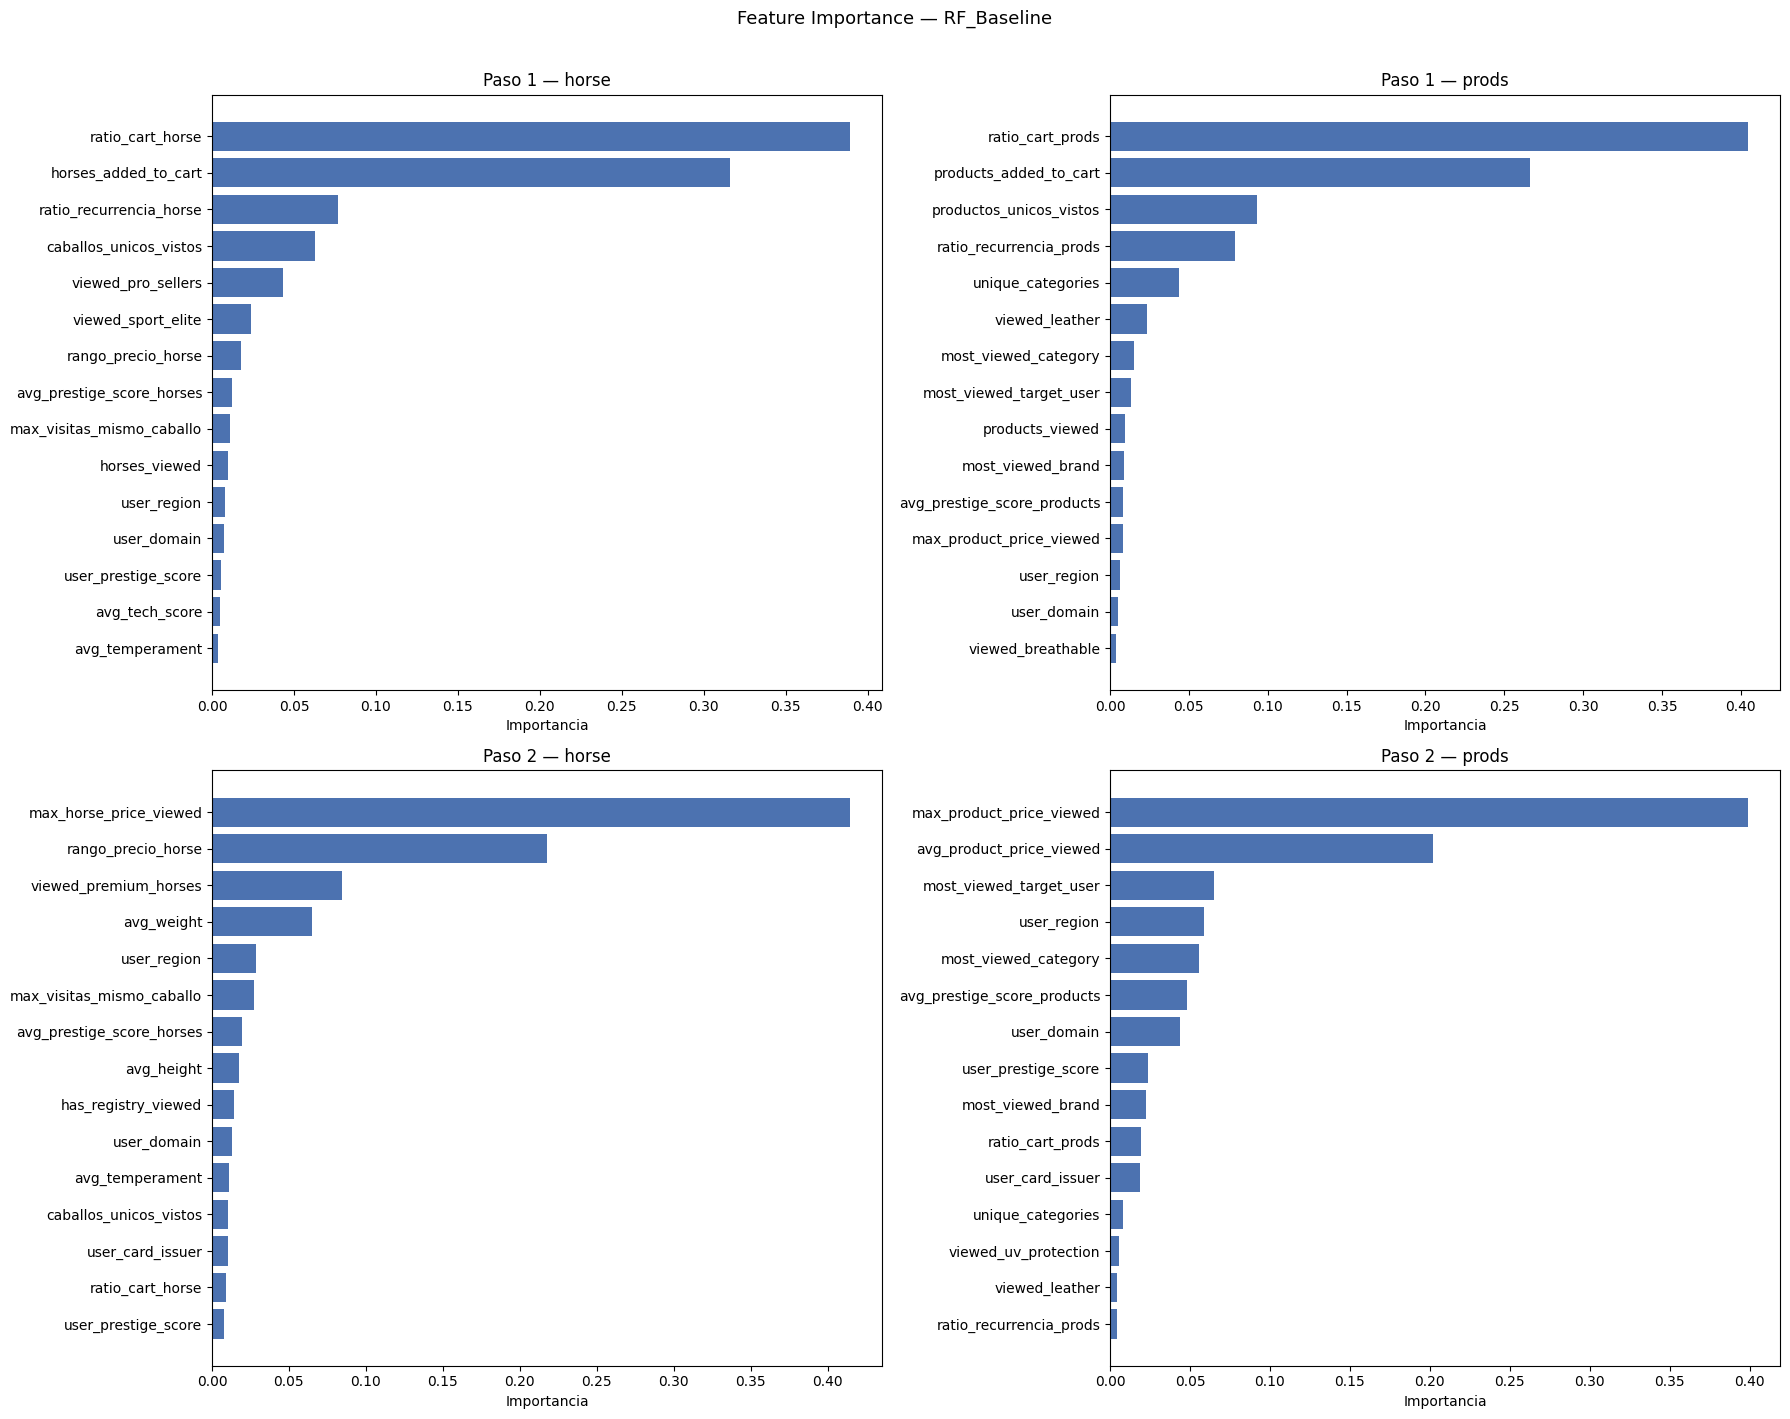

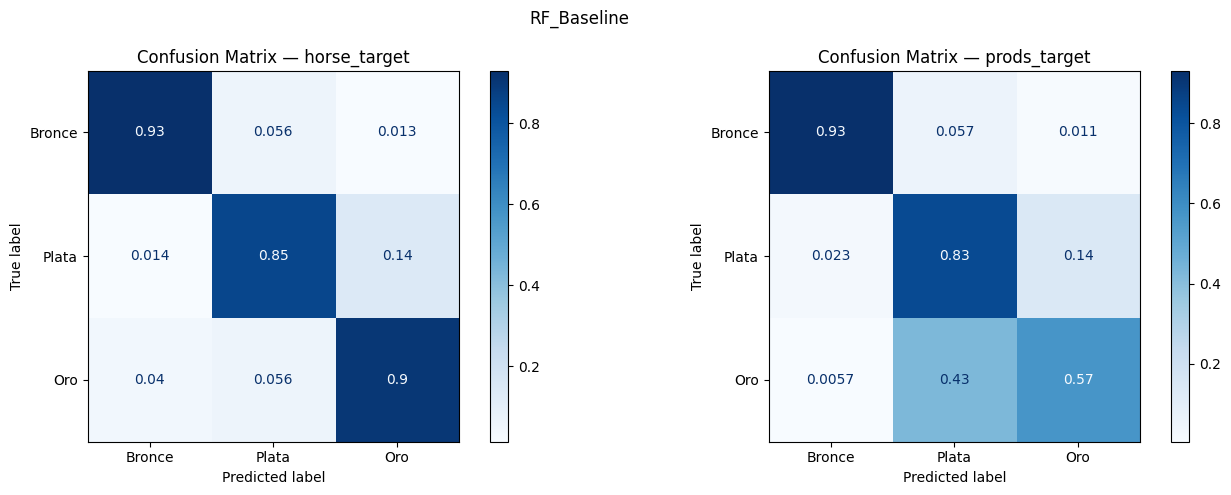

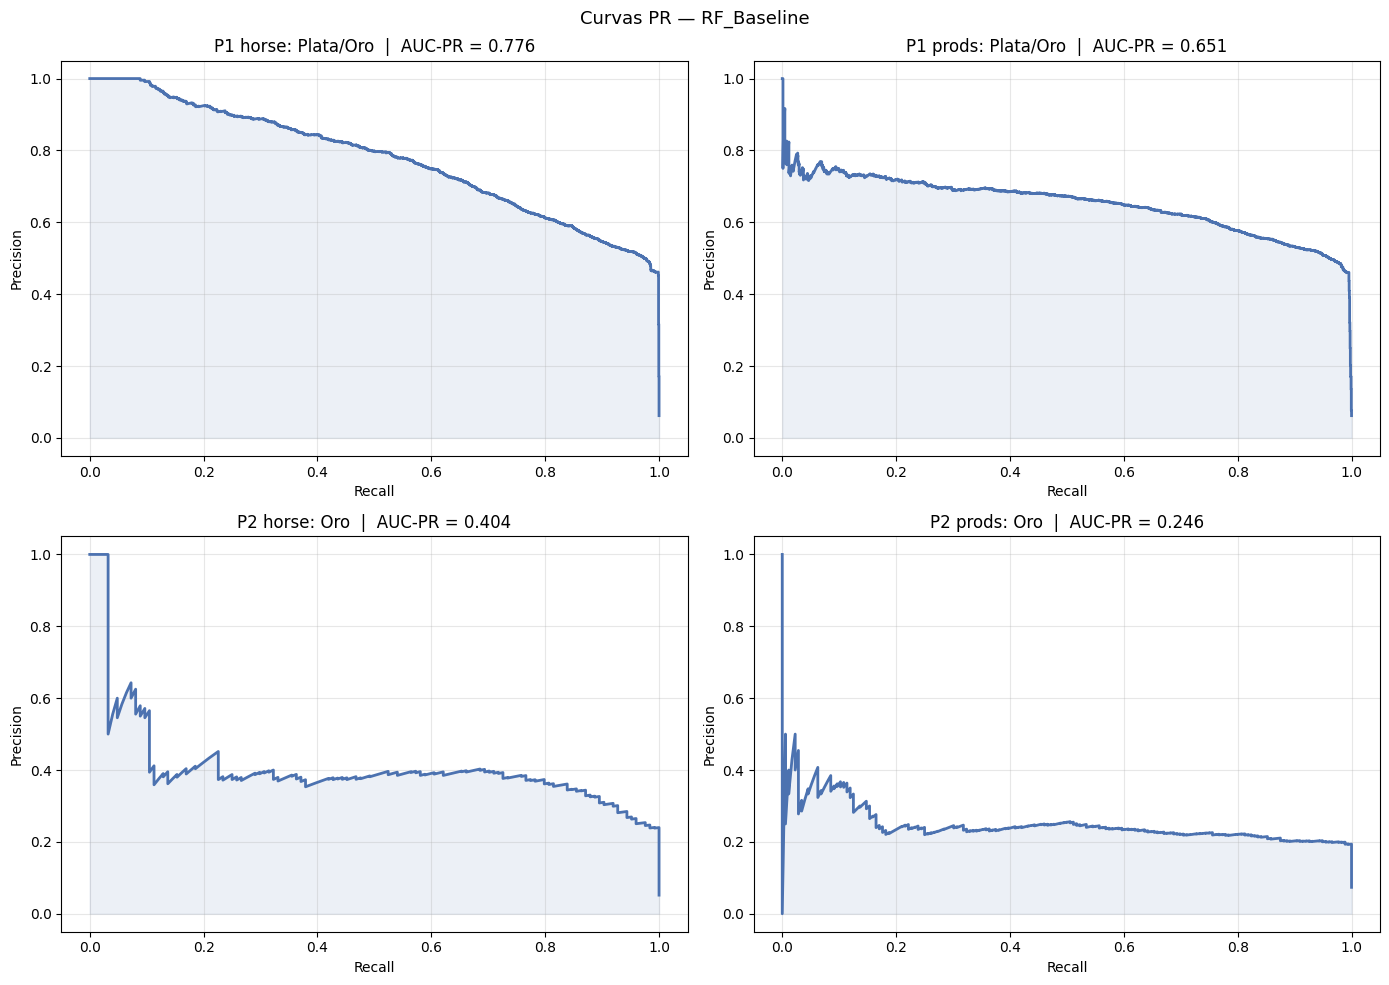

Run logueado: RF_Baseline  |  run_id: ed81a440d57d43bfab124d7af6899b26
🏃 View run RF_Baseline at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4/runs/ed81a440d57d43bfab124d7af6899b26
🧪 View experiment at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4

  Chequeo Overfitting — RF Baseline
─────────────────────────────────────────────────────────────────
  Paso                 F2 Train    F2 Test      Gap  Status
  ───────────────────────────────────────────────────────────────
  P1 — horse             0.9851     0.8152   0.1699  overfit
  P1 — prods             0.9852     0.8131   0.1721  overfit
  P2 — horse             0.9719     0.6324   0.3395  overfit
  P2 — prods             0.9493     0.4456   0.5037  overfit


In [76]:
run_id_rf_base = loguear_run_mlflow(
    run_name    = 'RF_Baseline',
    model_type  = 'RandomForest',
    params_p1   = rf_base_params,
    params_p2   = rf_base_params,
    p1h=rf_base_p1h, p1p=rf_base_p1p,
    p2h=rf_base_p2h, p2p=rf_base_p2p,
    metricas    = metricas_rf_base,
    X_train_p1h = X_p1h_bal,    # horse domain
    X_train_p1p = X_p1p_bal,    # prods domain
    X_train_p2h = X_p2h_bal,
    X_train_p2p = X_p2p_bal,
)

check_overfitting([
    ('P1 — horse', rf_base_p1h, X_p1h_bal, y_p1h_bal, X_test_horse, y_test_p1_horse),
    ('P1 — prods', rf_base_p1p, X_p1p_bal, y_p1p_bal, X_test_prods, y_test_p1_prods),
    ('P2 — horse', rf_base_p2h, X_p2h_bal, y_p2h_bal,
     X_test_horse[mask_test_p2_horse], y_test_p2_horse),
    ('P2 — prods', rf_base_p2p, X_p2p_bal, y_p2p_bal,
     X_test_prods[mask_test_p2_prods], y_test_p2_prods),
], 'RF Baseline')


### 2 · Random Forest — Tuning

RandomizedCV optimizando F2-score con CV estratificado.


In [77]:
# RandomizedSearchCV en lugar de GridSearchCV para agilizar tiempo de tuneo
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist_rf = {
    'max_depth':        [4, 6, 8],
    'min_samples_leaf': [30, 75],
    'n_estimators':     [150, 300],
    'max_features':     ['sqrt', 0.5],
}

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def tune_rf(X_tr, y_tr, label, n_iter=12, sample_frac=0.4):
    # Submuestreamos para acelerar — suficiente para encontrar la región óptima
    idx = np.random.default_rng(42).choice(
        len(X_tr), size=int(len(X_tr) * sample_frac), replace=False
    )
    X_sub = X_tr.iloc[idx] if hasattr(X_tr, 'iloc') else X_tr[idx]
    y_sub = y_tr.iloc[idx] if hasattr(y_tr, 'iloc') else y_tr[idx]

    rs = RandomizedSearchCV(
        RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        param_dist_rf, n_iter=n_iter, scoring=f2_scorer,
        cv=cv3, n_jobs=-1, verbose=1, random_state=42
    )
    rs.fit(X_sub, y_sub)
    best = rs.best_params_
    print(f'{label:<12} → {best}  CV F2: {rs.best_score_:.4f}')

    # Reentrenamos con los best params sobre el dataset completo
    final_model = RandomForestClassifier(
        **best, class_weight='balanced', random_state=42, n_jobs=-1
    )
    final_model.fit(X_tr, y_tr)
    return final_model, best

print('── Paso 1 ──')
rf_tune_p1h, params_rf_p1h = tune_rf(X_p1h_bal, y_p1h_bal, 'P1 horse')
rf_tune_p1p, params_rf_p1p = tune_rf(X_p1p_bal, y_p1p_bal, 'P1 prods')
print('\n── Paso 2 ──')
rf_tune_p2h, params_rf_p2h = tune_rf(X_p2h_bal, y_p2h_bal, 'P2 horse')
rf_tune_p2p, params_rf_p2p = tune_rf(X_p2p_bal, y_p2p_bal, 'P2 prods')
print('\nTuning RF completo.')

── Paso 1 ──
Fitting 3 folds for each of 12 candidates, totalling 36 fits


P1 horse     → {'n_estimators': 300, 'min_samples_leaf': 30, 'max_features': 0.5, 'max_depth': 8}  CV F2: 0.9849
Fitting 3 folds for each of 12 candidates, totalling 36 fits
P1 prods     → {'n_estimators': 300, 'min_samples_leaf': 30, 'max_features': 0.5, 'max_depth': 8}  CV F2: 0.9848

── Paso 2 ──
Fitting 3 folds for each of 12 candidates, totalling 36 fits
P2 horse     → {'n_estimators': 150, 'min_samples_leaf': 30, 'max_features': 'sqrt', 'max_depth': 8}  CV F2: 0.9677
Fitting 3 folds for each of 12 candidates, totalling 36 fits
P2 prods     → {'n_estimators': 300, 'min_samples_leaf': 30, 'max_features': 'sqrt', 'max_depth': 6}  CV F2: 0.9397

Tuning RF completo.


In [78]:
metricas_rf_tune = calcular_metricas_cascada(rf_tune_p1h, rf_tune_p1p,
                                              rf_tune_p2h, rf_tune_p2p)

for t, m in metricas_rf_tune.items():
    print(f'{t}: F2 macro={m["f2_macro"]:.4f} | F2 Oro={m["f2_lead_oro"]:.4f} '
          f'| Gap P2={m["overfit_gap_p2"]:.4f}')

horse: F2 macro=0.7061 | F2 Oro=0.4224 | Gap P2=0.0145
prods: F2 macro=0.6567 | F2 Oro=0.3325 | Gap P2=0.0616


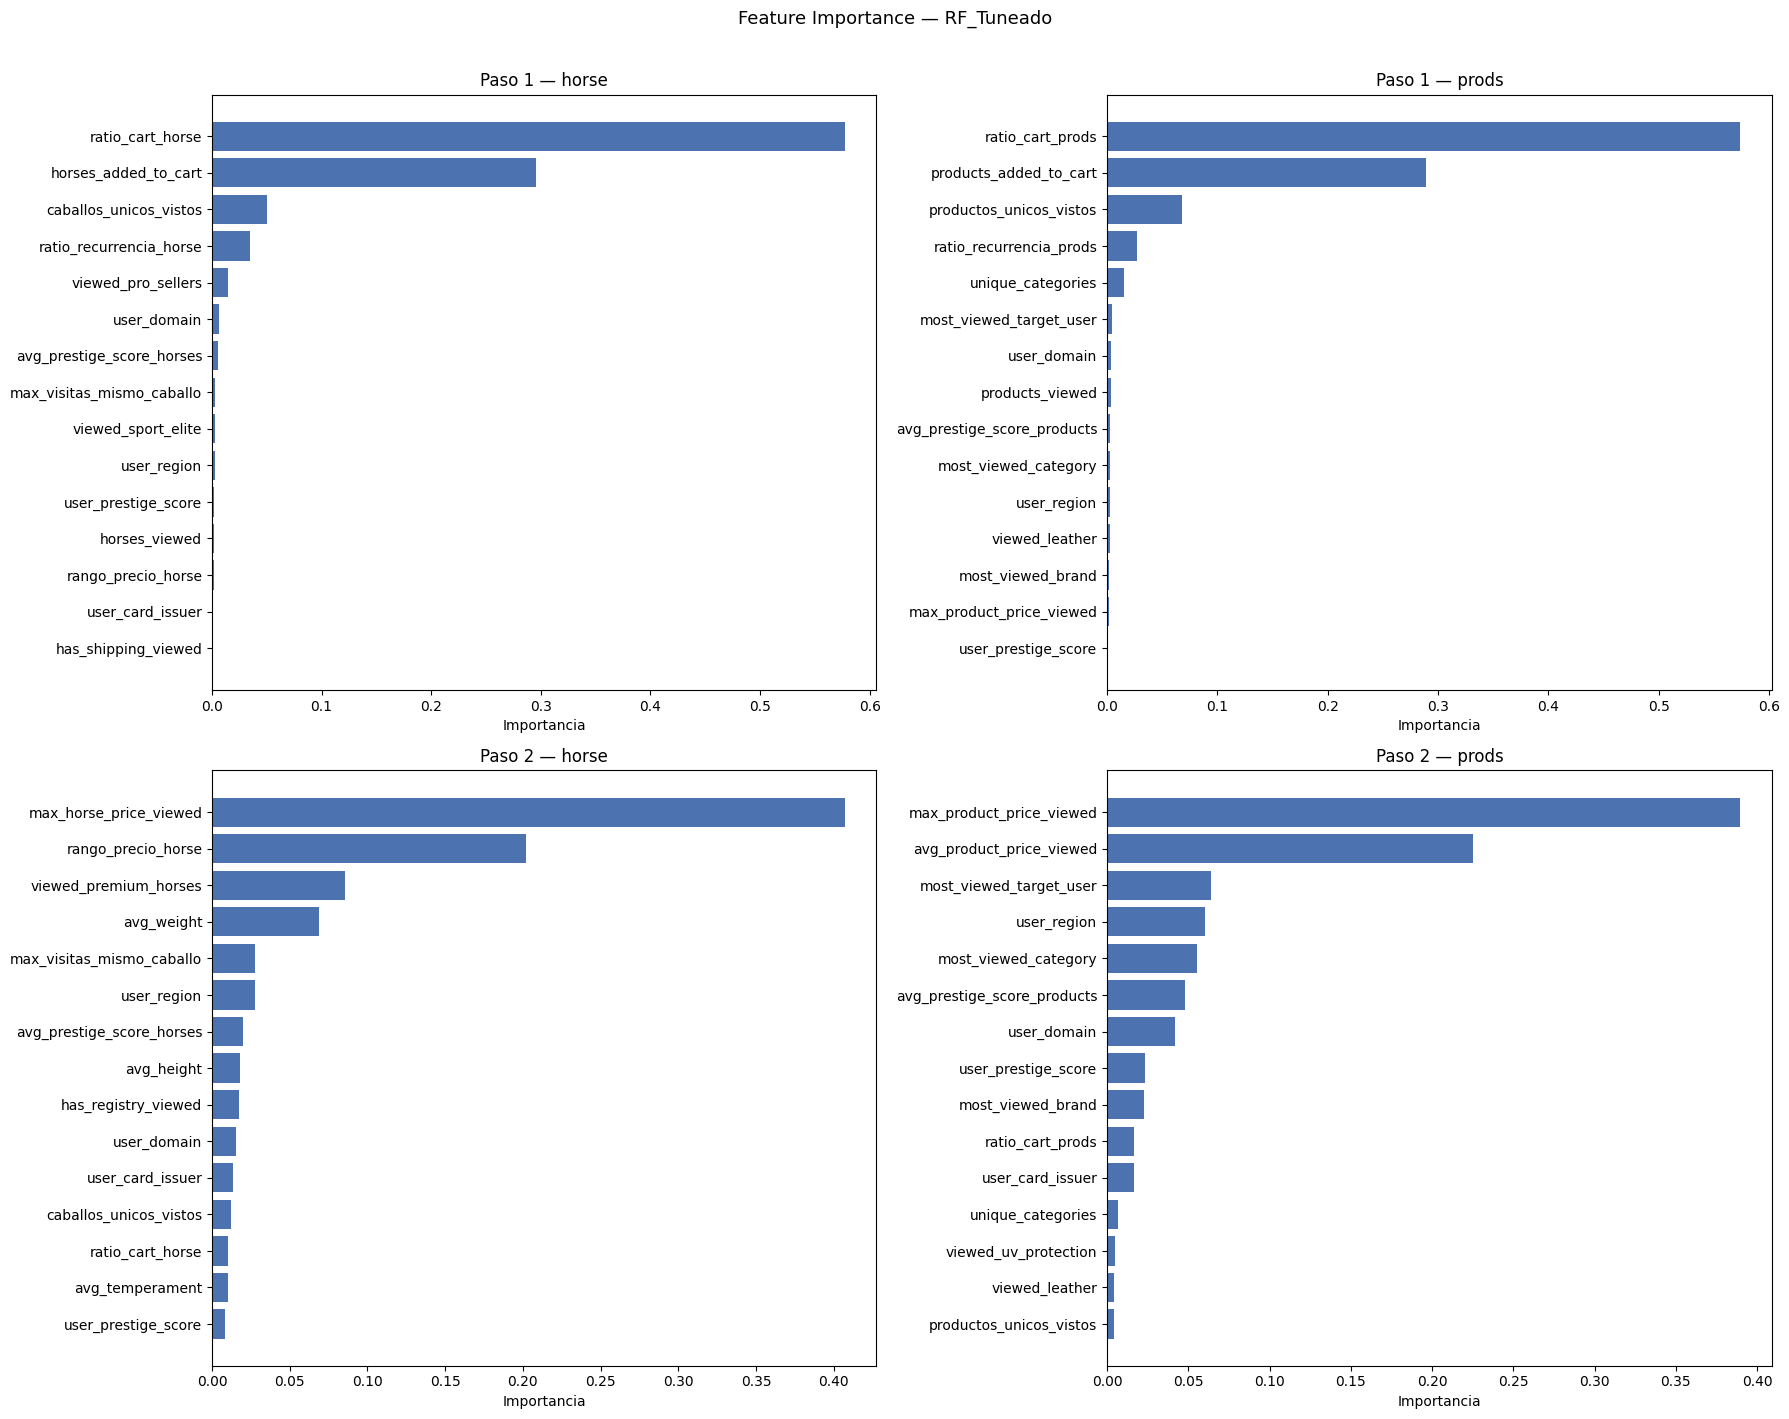

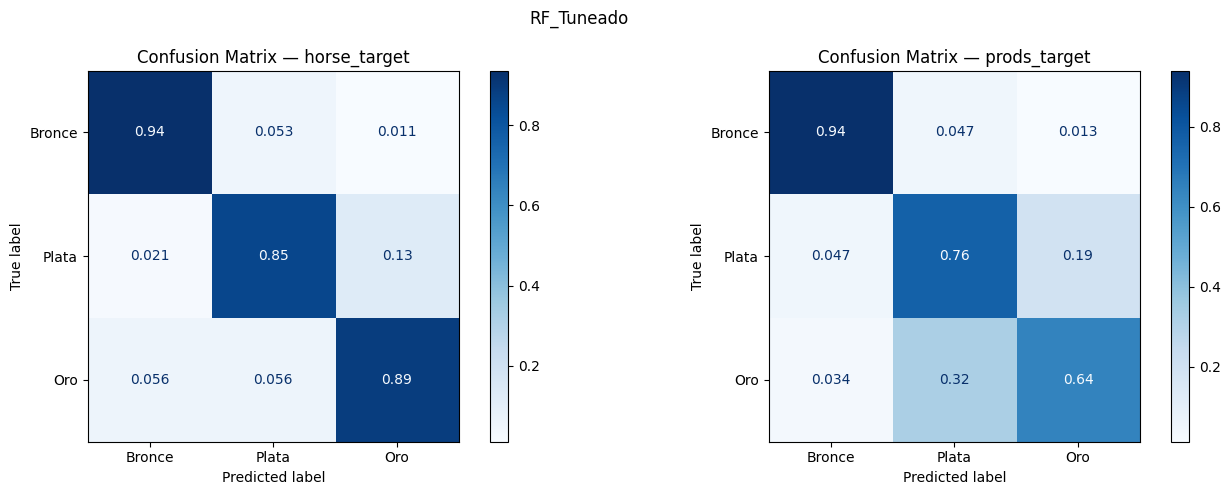

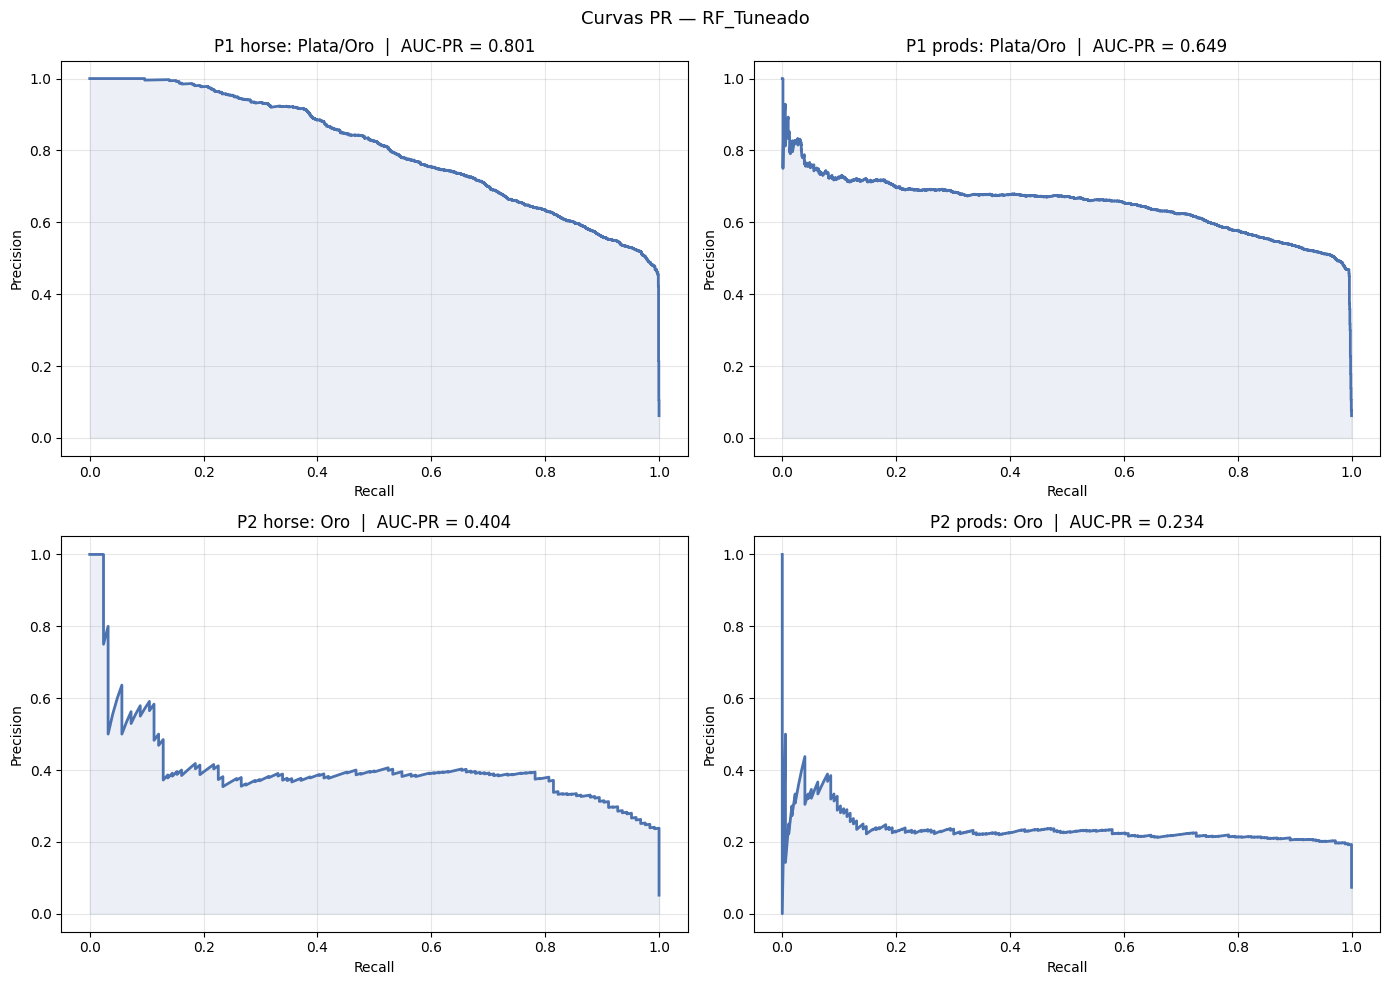

Run logueado: RF_Tuneado  |  run_id: 7045e31995d54040b97cb796a6b69bab
🏃 View run RF_Tuneado at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4/runs/7045e31995d54040b97cb796a6b69bab
🧪 View experiment at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4

  Chequeo Overfitting — RF Tuneado
─────────────────────────────────────────────────────────────────
  Paso                 F2 Train    F2 Test      Gap  Status
  ───────────────────────────────────────────────────────────────
  P1 — horse             0.9861     0.8206   0.1655  overfit
  P1 — prods             0.9861     0.8133   0.1728  overfit
  P2 — horse             0.9734     0.6444   0.3289  overfit
  P2 — prods             0.9469     0.4651   0.4818  overfit


In [79]:
run_id_rf_tune = loguear_run_mlflow(
    run_name    = 'RF_Tuneado',
    model_type  = 'RandomForest',
    params_p1   = params_rf_p1h,
    params_p2   = params_rf_p2h,
    p1h=rf_tune_p1h, p1p=rf_tune_p1p,
    p2h=rf_tune_p2h, p2p=rf_tune_p2p,
    metricas    = metricas_rf_tune,
    X_train_p1h = X_p1h_bal,
    X_train_p1p = X_p1p_bal,
    X_train_p2h = X_p2h_bal,
    X_train_p2p = X_p2p_bal,
)

check_overfitting([
    ('P1 — horse', rf_tune_p1h, X_p1h_bal, y_p1h_bal, X_test_horse, y_test_p1_horse),
    ('P1 — prods', rf_tune_p1p, X_p1p_bal, y_p1p_bal, X_test_prods, y_test_p1_prods),
    ('P2 — horse', rf_tune_p2h, X_p2h_bal, y_p2h_bal,
     X_test_horse[mask_test_p2_horse], y_test_p2_horse),
    ('P2 — prods', rf_tune_p2p, X_p2p_bal, y_p2p_bal,
     X_test_prods[mask_test_p2_prods], y_test_p2_prods),
], 'RF Tuneado')


### 3 · XGBoost

XGBoost usa boosting iterativo, regularización L1/L2 nativa y `scale_pos_weight` para manejar el desbalance sin SMOTE.

In [80]:
xgb_base_params = dict(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='aucpr',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# Cada modelo entrena sobre el dataset de su dominio
xgb_base_p1h = XGBClassifier(**xgb_base_params, scale_pos_weight=spw_p1h).fit(X_train_horse, y_train_p1_horse)
xgb_base_p1p = XGBClassifier(**xgb_base_params, scale_pos_weight=spw_p1p).fit(X_train_prods, y_train_p1_prods)
xgb_base_p2h = XGBClassifier(**xgb_base_params, scale_pos_weight=spw_p2h).fit(X_p2h_raw, y_p2h_raw)
xgb_base_p2p = XGBClassifier(**xgb_base_params, scale_pos_weight=spw_p2p).fit(X_p2p_raw, y_p2p_raw)

metricas_xgb_base = calcular_metricas_cascada(xgb_base_p1h, xgb_base_p1p,
                                               xgb_base_p2h, xgb_base_p2p)
for t, m in metricas_xgb_base.items():
    print(f'{t}: F2 macro={m["f2_macro"]:.4f} | F2 Oro={m["f2_lead_oro"]:.4f} '
          f'| Gap P2={m["overfit_gap_p2"]:.4f}')


horse: F2 macro=0.7262 | F2 Oro=0.4348 | Gap P2=0.1747
prods: F2 macro=0.6778 | F2 Oro=0.3912 | Gap P2=0.1378


2026/03/04 04:42:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:42:51 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 04:42:55 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:43:15 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 04:43:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:43:41 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 04:43:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:44:07 WARNING mlflow.utils.

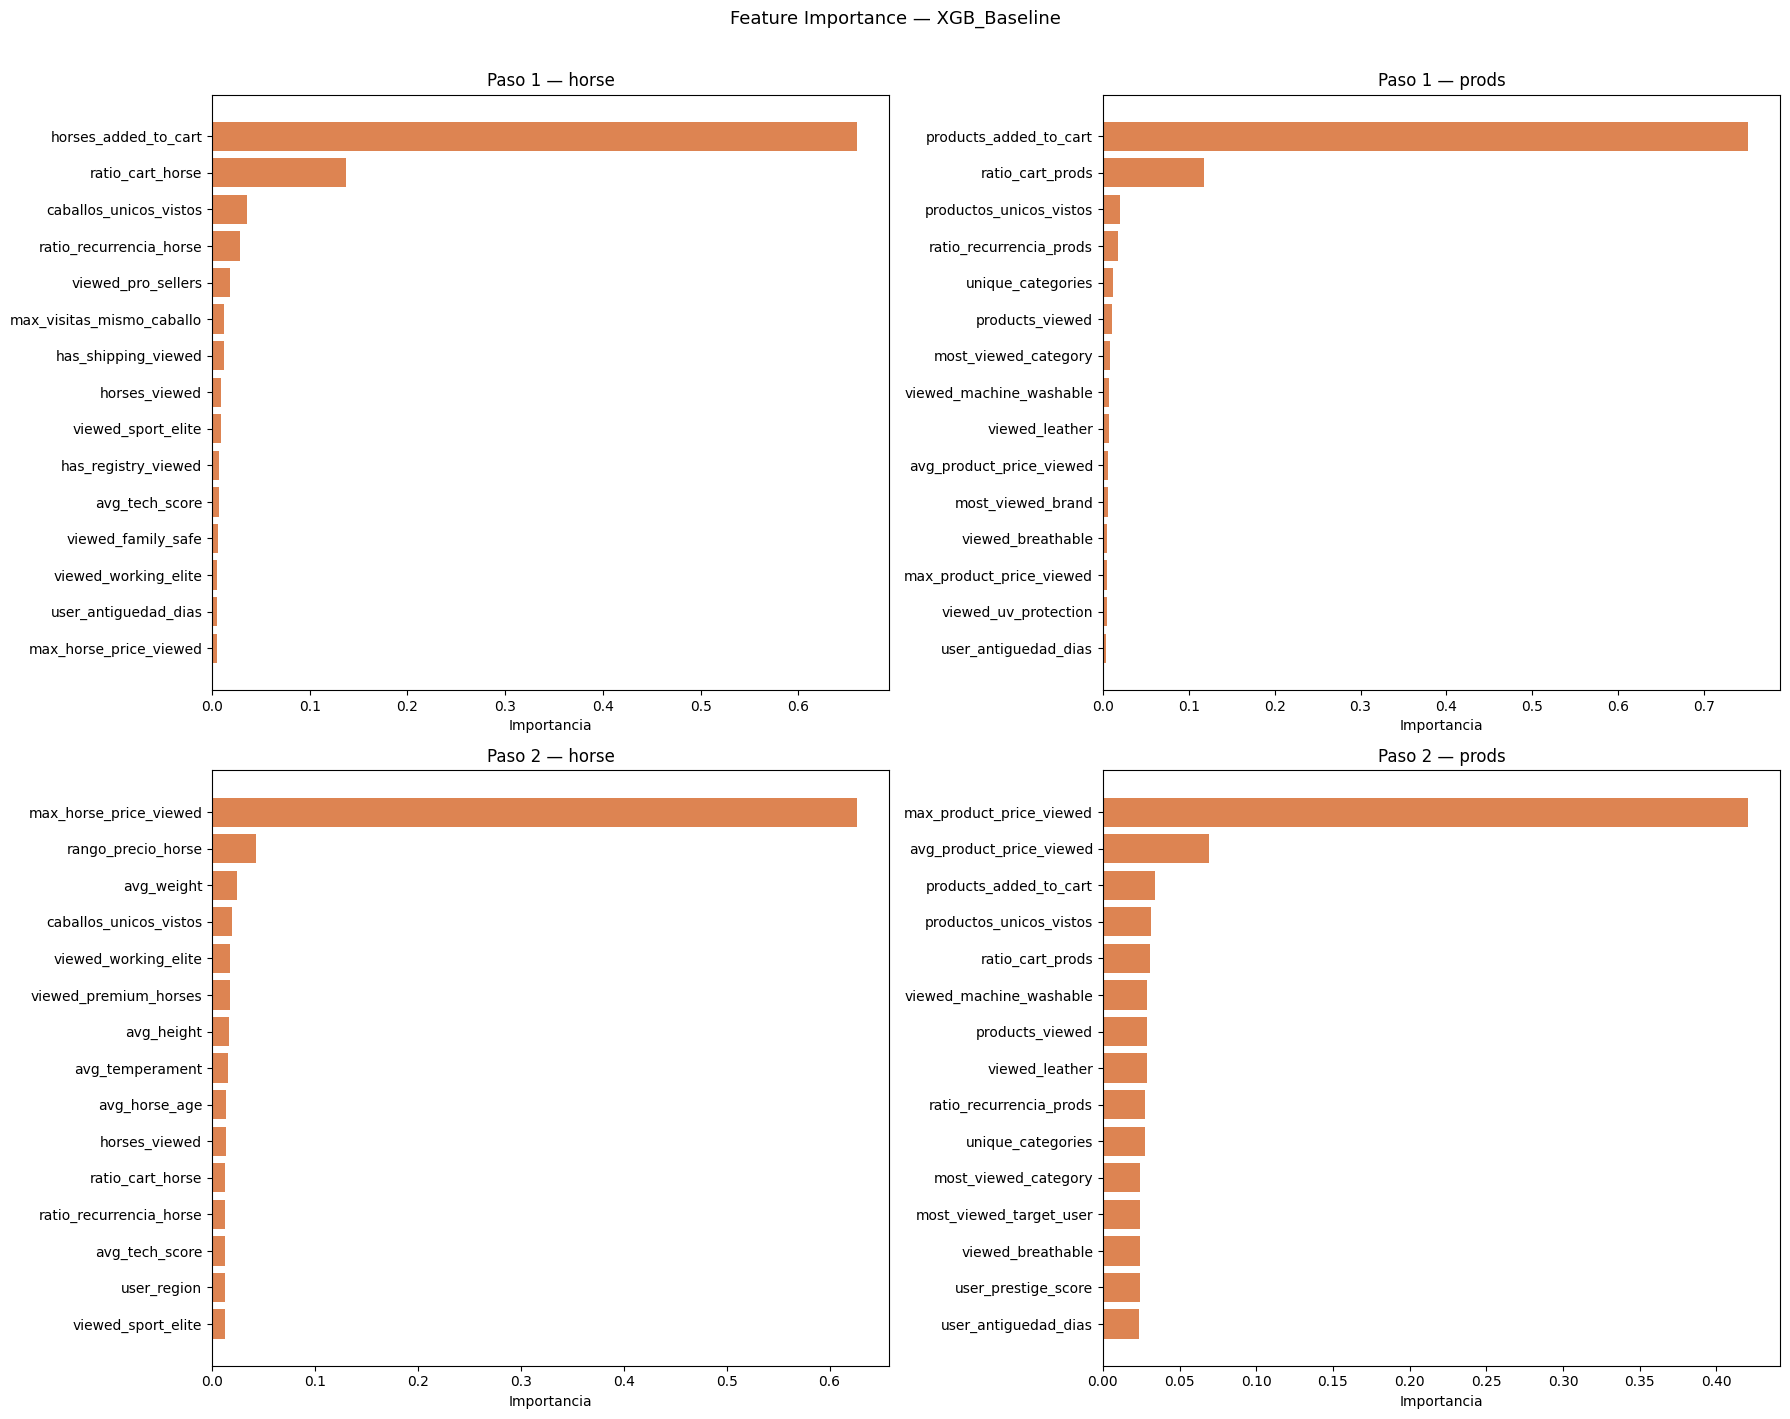

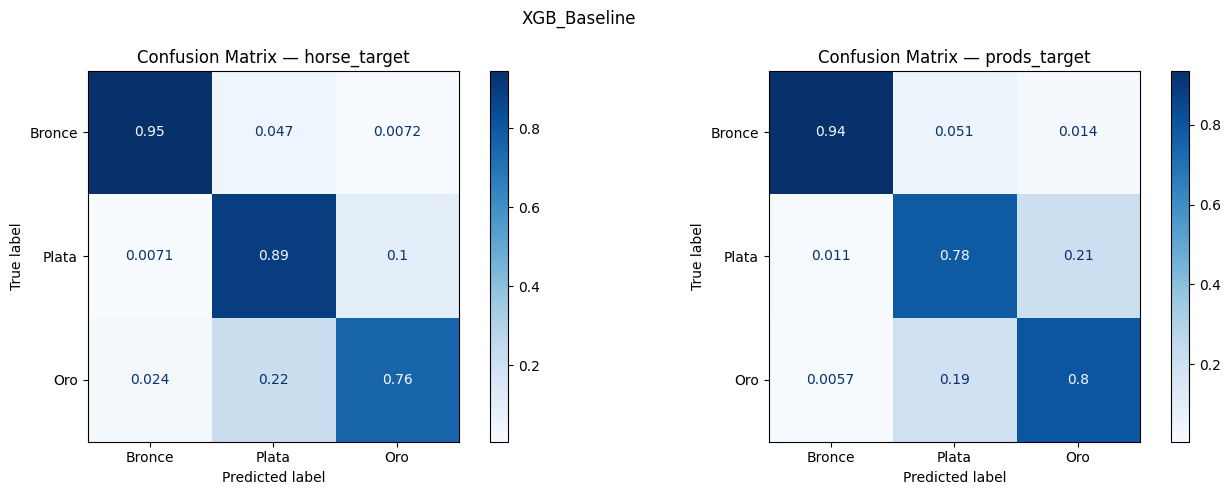

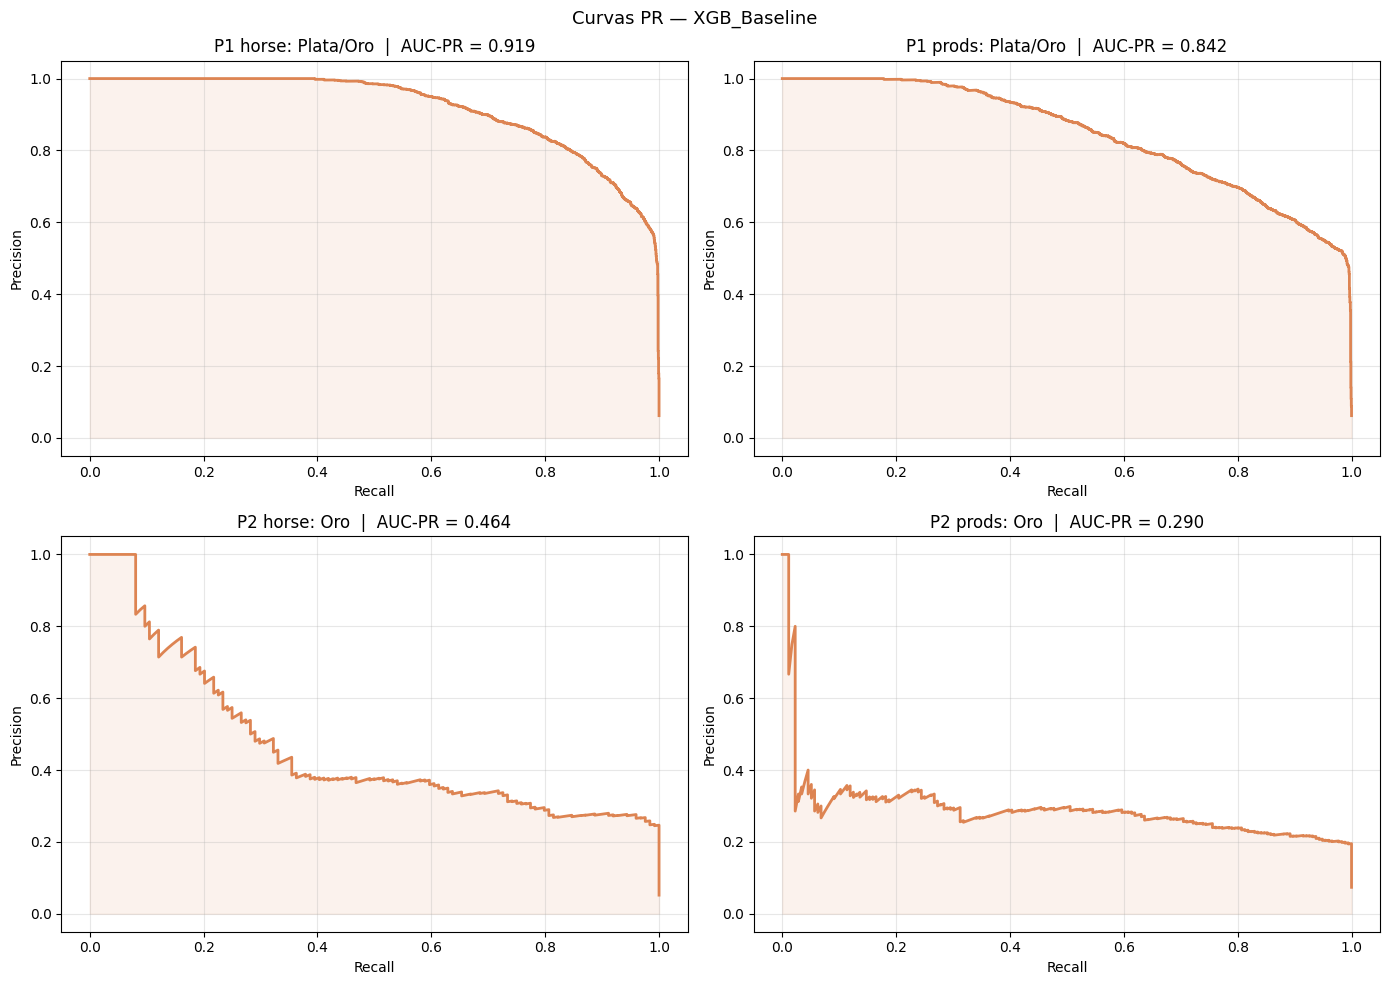

Run logueado: XGB_Baseline  |  run_id: 5c3f2c7b947640888eaa22d68efb242a
🏃 View run XGB_Baseline at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4/runs/5c3f2c7b947640888eaa22d68efb242a
🧪 View experiment at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4

  Chequeo Overfitting — XGB Baseline
─────────────────────────────────────────────────────────────────
  Paso                 F2 Train    F2 Test      Gap  Status
  ───────────────────────────────────────────────────────────────
  P1 — horse             0.8545     0.8524   0.0020  OK
  P1 — prods             0.8302     0.8298   0.0004  OK
  P2 — horse             0.7640     0.5893   0.1747  overfit
  P2 — prods             0.6790     0.5412   0.1378  overfit


In [81]:
run_id_xgb_base = loguear_run_mlflow(
    run_name    = 'XGB_Baseline',
    model_type  = 'XGBoost',
    params_p1   = {**xgb_base_params, 'scale_pos_weight': spw_p1h},
    params_p2   = {**xgb_base_params, 'scale_pos_weight': spw_p2h},
    p1h=xgb_base_p1h, p1p=xgb_base_p1p,
    p2h=xgb_base_p2h, p2p=xgb_base_p2p,
    metricas    = metricas_xgb_base,
    X_train_p1h = X_train_horse,
    X_train_p1p = X_train_prods,
    X_train_p2h = X_p2h_raw,
    X_train_p2p = X_p2p_raw,
)

check_overfitting([
    ('P1 — horse', xgb_base_p1h, X_train_horse, y_train_p1_horse, X_test_horse, y_test_p1_horse),
    ('P1 — prods', xgb_base_p1p, X_train_prods, y_train_p1_prods, X_test_prods, y_test_p1_prods),
    ('P2 — horse', xgb_base_p2h, X_p2h_raw, y_p2h_raw,
     X_test_horse[mask_test_p2_horse], y_test_p2_horse),
    ('P2 — prods', xgb_base_p2p, X_p2p_raw, y_p2p_raw,
     X_test_prods[mask_test_p2_prods], y_test_p2_prods),
], 'XGB Baseline')


### 3.5 · Threshold Tuning — XGB Baseline

El umbral por defecto de `.predict()` es 0.5, pero con Lead Oro < 0.5% del dataset, bajar el umbral puede recuperar verdaderos positivos sin ningún costo computacional adicional.

Buscamos en [0.10, 0.80] el threshold que **maximiza F2 Lead Oro** en test, aplicando la búsqueda por separado sobre el dominio de caballos (`X_test_horse`) y el de productos (`X_test_prods`). F2 penaliza más los falsos negativos, lo que es apropiado para no perder leads de alto valor.


In [82]:
def tune_threshold_cascada(m1, m2, X_te, y_true_col):
    """Busca threshold óptimo para P2 maximizando F2 Lead Oro en cascada."""
    from sklearn.metrics import fbeta_score
    mask_p1 = m1.predict(X_te) == 1
    proba_p2 = np.zeros(len(X_te))
    if mask_p1.sum() > 0:
        proba_p2[mask_p1] = m2.predict_proba(X_te[mask_p1])[:, 1]

    best_thresh, best_f2 = 0.5, 0.0
    for t in np.arange(0.10, 0.81, 0.02):
        pred = np.array(['Lead Bronce'] * len(X_te), dtype=object)
        pred[mask_p1] = np.where(proba_p2[mask_p1] >= t, 'Lead Oro', 'Lead Plata')
        f2 = fbeta_score(y_true_col, pred, beta=2,
                         labels=['Lead Oro'], average='macro', zero_division=0)
        if f2 > best_f2:
            best_f2, best_thresh = f2, t
    return best_thresh, best_f2

# Threshold tuning sobre XGB Baseline — cada modelo usa su dataset de dominio
thresh_horse, f2_thresh_horse = tune_threshold_cascada(
    xgb_base_p1h, xgb_base_p2h, X_test_horse, y_test['horse_target']
)
thresh_prods, f2_thresh_prods = tune_threshold_cascada(
    xgb_base_p1p, xgb_base_p2p, X_test_prods, y_test['prods_target']
)

f2_base_horse = metricas_xgb_base['horse']['f2_lead_oro']
f2_base_prods = metricas_xgb_base['prods']['f2_lead_oro']

print('Threshold Tuning — XGB Baseline')
print(f'  horse: thresh_opt={thresh_horse:.2f} | F2 default={f2_base_horse:.4f} → F2 tuned={f2_thresh_horse:.4f} | Δ={f2_thresh_horse-f2_base_horse:+.4f}')
print(f'  prods: thresh_opt={thresh_prods:.2f} | F2 default={f2_base_prods:.4f} → F2 tuned={f2_thresh_prods:.4f} | Δ={f2_thresh_prods-f2_base_prods:+.4f}')


Threshold Tuning — XGB Baseline
  horse: thresh_opt=0.62 | F2 default=0.4348 → F2 tuned=0.4493 | Δ=+0.0145
  prods: thresh_opt=0.56 | F2 default=0.3912 → F2 tuned=0.4000 | Δ=+0.0088


### 4 · XGBoost — Tuning

In [83]:
# Pipeline(SMOTE → XGB) para Paso 2: evita leakage de SMOTE en los folds de CV

from imblearn.pipeline import Pipeline as ImbPipeline

param_dist_xgb = {
    'max_depth':        [3, 4, 5],
    'learning_rate':    [0.01, 0.05, 0.1],
    'n_estimators':     [200, 400],
    'subsample':        [0.7, 0.9],
    'colsample_bytree': [0.7, 0.9],
    'reg_alpha':        [0, 0.1, 1.0],
    'reg_lambda':       [1.0, 5.0],
}

# Para el tuning de Paso 2 usamos Pipeline SMOTE+XGB
# Los params del XGB dentro del pipeline llevan prefijo 'xgb__'
param_dist_xgb_p2 = {f'xgb__{k}': v for k, v in param_dist_xgb.items()}

def tune_xgb_p1(X_tr, y_tr, spw, label, n_iter=15):
    """Paso 1: datos ya balanceados con scale_pos_weight, sin SMOTE."""
    rs = RandomizedSearchCV(
        XGBClassifier(
            scale_pos_weight=spw,
            eval_metric='aucpr',
            tree_method='hist',
            random_state=42,
            n_jobs=-1
        ),
        param_dist_xgb, n_iter=n_iter, scoring=f2_scorer,
        cv=cv3, n_jobs=-1, verbose=0, random_state=42
    )
    rs.fit(X_tr, y_tr)
    best = rs.best_params_
    print(f'{label:<12} → {best}  CV F2: {rs.best_score_:.4f}')
    final = XGBClassifier(
        **best, scale_pos_weight=spw,
        eval_metric='aucpr', tree_method='hist',
        random_state=42, n_jobs=-1
    )
    final.fit(X_tr, y_tr)
    return final, best

def tune_xgb_p2(X_tr, y_tr, spw, label, n_iter=15):
    """Paso 2: Pipeline SMOTE+XGB para evitar leakage en CV."""
    pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('xgb', XGBClassifier(
            scale_pos_weight=spw,
            eval_metric='aucpr',
            tree_method='hist',
            random_state=42,
            n_jobs=-1
        ))
    ])
    rs = RandomizedSearchCV(
        pipe, param_dist_xgb_p2, n_iter=n_iter, scoring=f2_scorer,
        cv=cv3, n_jobs=-1, verbose=0, random_state=42
    )
    rs.fit(X_tr, y_tr)
    best_pipe_params = rs.best_params_
    best = {k.replace('xgb__', ''): v for k, v in best_pipe_params.items()}
    print(f'{label:<12} → {best}  CV F2: {rs.best_score_:.4f}')
    # Reentrenamos el modelo final sobre dataset completo 
    X_bal, y_bal = SMOTE(random_state=42).fit_resample(X_tr, y_tr)
    final = XGBClassifier(
        **best, scale_pos_weight=spw,
        eval_metric='aucpr', tree_method='hist',
        random_state=42, n_jobs=-1
    )
    final.fit(X_bal, y_bal)
    return final, best

print('── Paso 1 ──')
xgb_tune_p1h, params_xgb_p1h = tune_xgb_p1(X_train_horse, y_train_p1_horse, spw_p1h, 'P1 horse')
xgb_tune_p1p, params_xgb_p1p = tune_xgb_p1(X_train_prods, y_train_p1_prods, spw_p1p, 'P1 prods')
print('\n── Paso 2 ──')
xgb_tune_p2h, params_xgb_p2h = tune_xgb_p2(X_p2h_raw, y_p2h_raw, spw_p2h, 'P2 horse')
xgb_tune_p2p, params_xgb_p2p = tune_xgb_p2(X_p2p_raw, y_p2p_raw, spw_p2p, 'P2 prods')
print('\nTuning XGBoost completo.')

── Paso 1 ──
P1 horse     → {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.9}  CV F2: 0.8830
P1 prods     → {'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.9}  CV F2: 0.8330

── Paso 2 ──
P2 horse     → {'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.7}  CV F2: 0.6143
P2 prods     → {'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.7}  CV F2: 0.5373

Tuning XGBoost completo.


In [84]:
metricas_xgb_tune = calcular_metricas_cascada(xgb_tune_p1h, xgb_tune_p1p,
                                               xgb_tune_p2h, xgb_tune_p2p)

for t, m in metricas_xgb_tune.items():
    print(f'{t}: F2 macro={m["f2_macro"]:.4f} | F2 Oro={m["f2_lead_oro"]:.4f} '
          f'| Gap P2={m["overfit_gap_p2"]:.4f}')

horse: F2 macro=0.7614 | F2 Oro=0.5054 | Gap P2=0.0266
prods: F2 macro=0.6511 | F2 Oro=0.3605 | Gap P2=0.0105


2026/03/04 04:48:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:49:16 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 04:49:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:49:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 04:49:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:50:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 04:50:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 04:50:34 WARNING mlflow.utils.

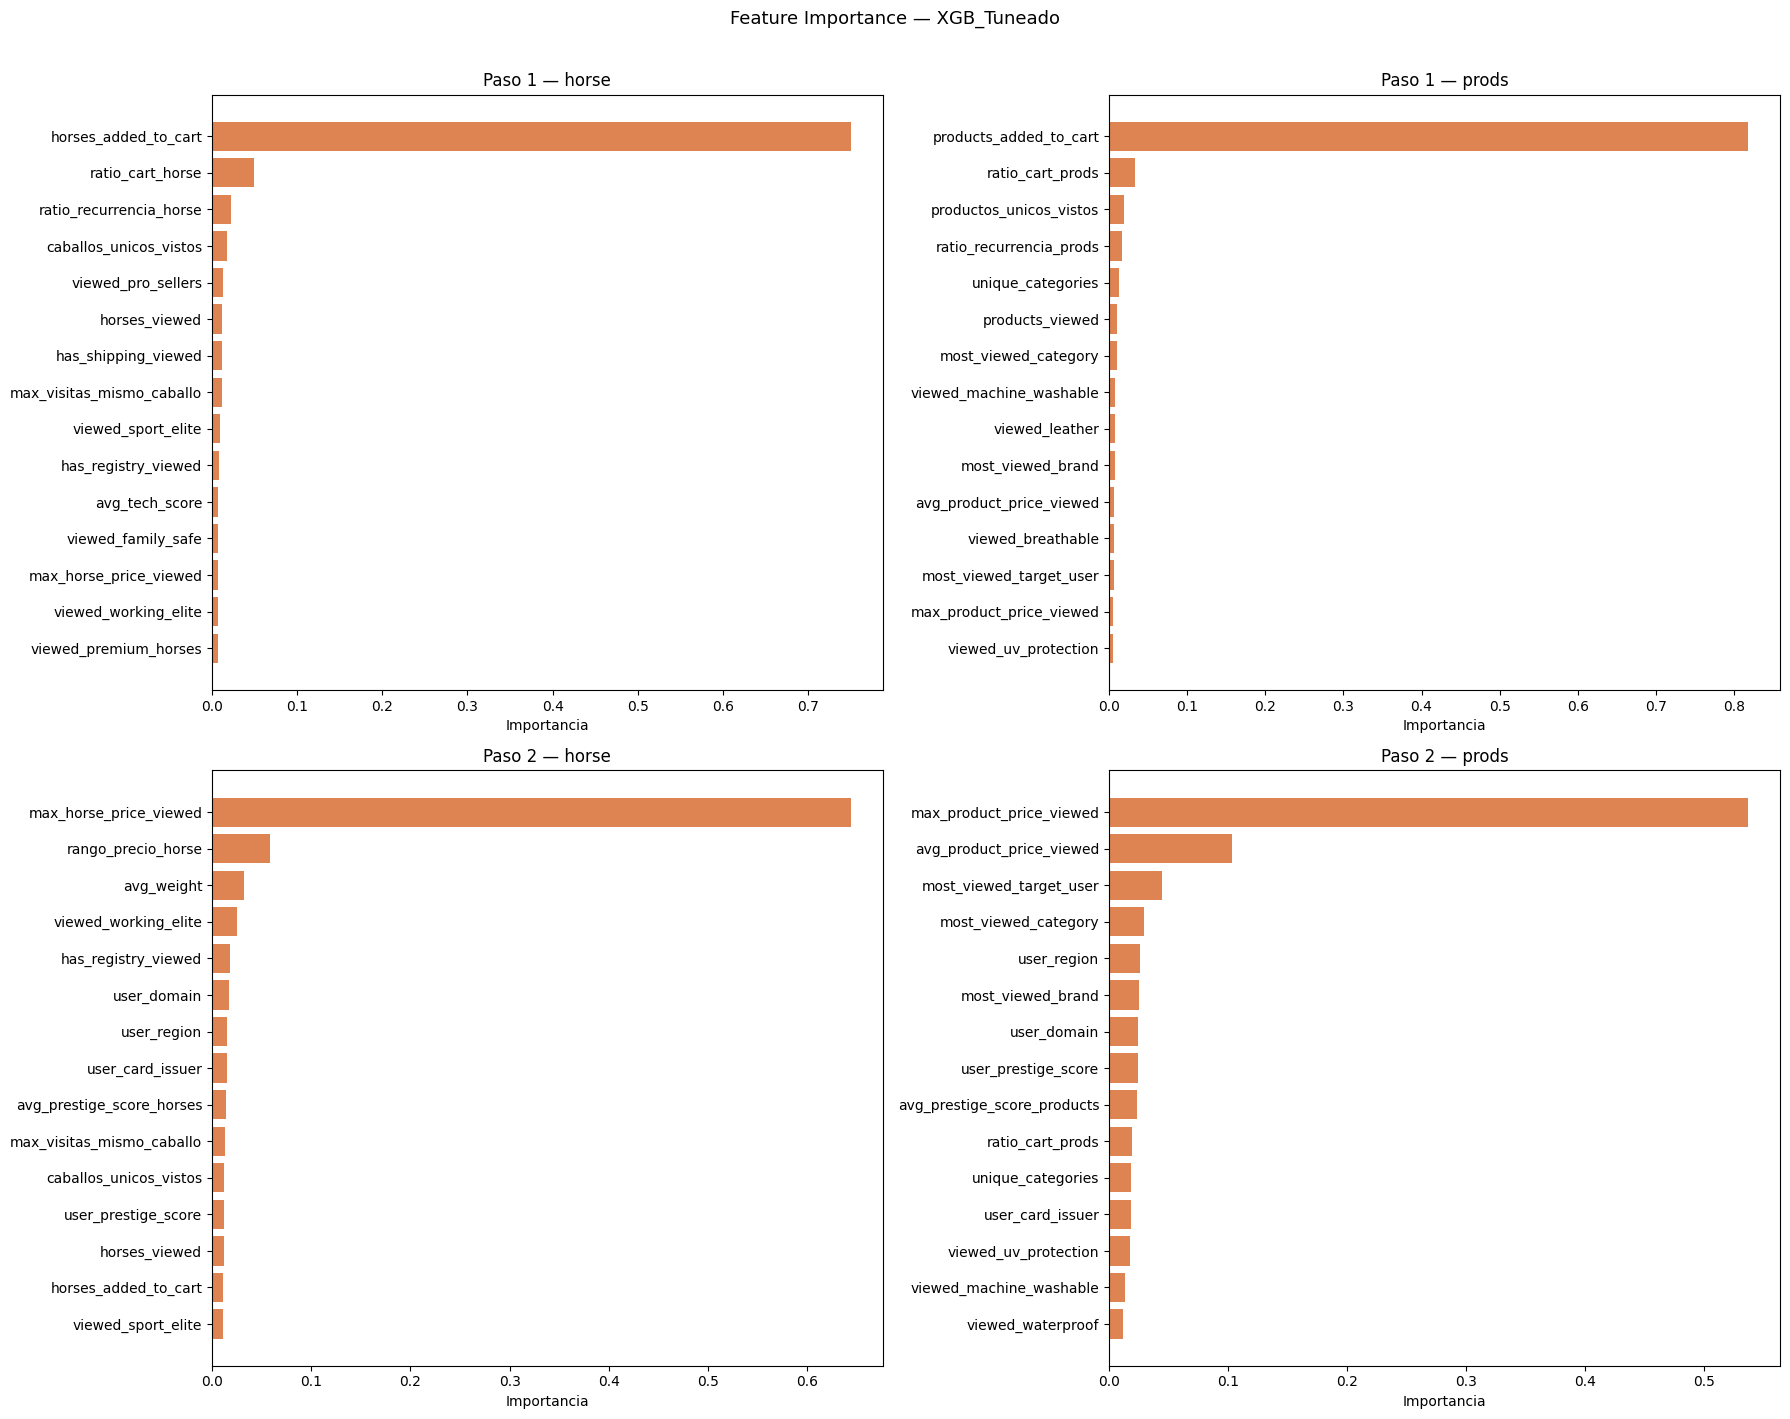

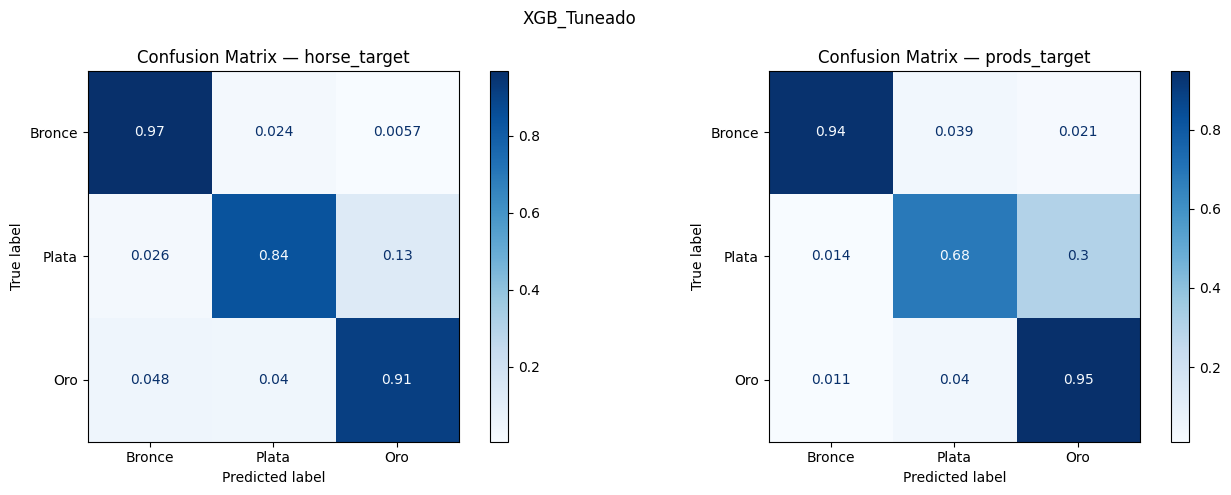

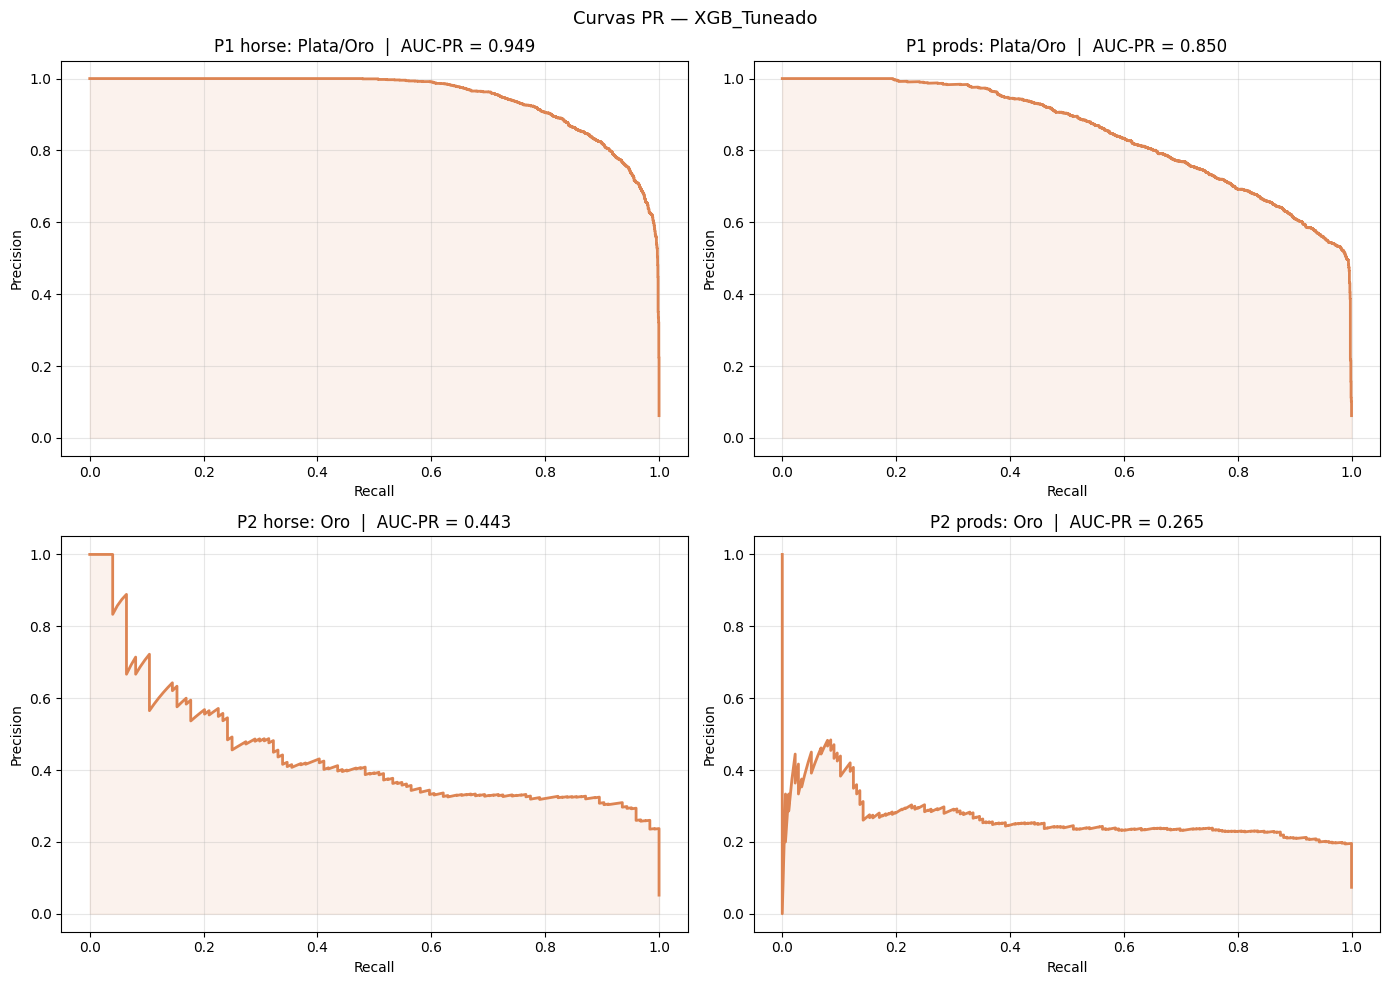

Run logueado: XGB_Tuneado  |  run_id: dd6f2989958a48d587e2769933622ff8
🏃 View run XGB_Tuneado at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4/runs/dd6f2989958a48d587e2769933622ff8
🧪 View experiment at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4

  Chequeo Overfitting — XGB Tuneado
─────────────────────────────────────────────────────────────────
  Paso                 F2 Train    F2 Test      Gap  Status
  ───────────────────────────────────────────────────────────────
  P1 — horse             0.9276     0.8957   0.0320  OK
  P1 — prods             0.8433     0.8363   0.0069  OK
  P2 — horse             0.6692     0.6425   0.0266  OK
  P2 — prods             0.5553     0.5448   0.0105  OK


In [85]:
run_id_xgb_tune = loguear_run_mlflow(
    run_name    = 'XGB_Tuneado',
    model_type  = 'XGBoost',
    params_p1   = {**params_xgb_p1h, 'scale_pos_weight': spw_p1h},
    params_p2   = {**params_xgb_p2h, 'scale_pos_weight': spw_p2h},
    p1h=xgb_tune_p1h, p1p=xgb_tune_p1p,
    p2h=xgb_tune_p2h, p2p=xgb_tune_p2p,
    metricas    = metricas_xgb_tune,
    X_train_p1h = X_train_horse,
    X_train_p1p = X_train_prods,
    X_train_p2h = X_p2h_raw,
    X_train_p2p = X_p2p_raw,
)

check_overfitting([
    ('P1 — horse', xgb_tune_p1h, X_train_horse, y_train_p1_horse, X_test_horse, y_test_p1_horse),
    ('P1 — prods', xgb_tune_p1p, X_train_prods, y_train_p1_prods, X_test_prods, y_test_p1_prods),
    ('P2 — horse', xgb_tune_p2h, X_p2h_raw, y_p2h_raw,
     X_test_horse[mask_test_p2_horse], y_test_p2_horse),
    ('P2 — prods', xgb_tune_p2p, X_p2p_raw, y_p2p_raw,
     X_test_prods[mask_test_p2_prods], y_test_p2_prods),
], 'XGB Tuneado')


### 5 · Comparativa final

Todos los runs ya están en DagsHub. Acá los comparamos también localmente con la misma tabla y gráfico.

In [86]:
todos = [
    ('RF  Baseline',   metricas_rf_base,   run_id_rf_base),
    ('RF  Tuneado',    metricas_rf_tune,    run_id_rf_tune),
    ('XGB Baseline',   metricas_xgb_base,   run_id_xgb_base),
    ('XGB Baseline+TH',{'horse': {**metricas_xgb_base['horse'], 'f2_lead_oro': f2_thresh_horse},
                        'prods': {**metricas_xgb_base['prods'], 'f2_lead_oro': f2_thresh_prods}},
                        None),
    ('XGB Tuneado',    metricas_xgb_tune,   run_id_xgb_tune),
]

print(f'{"Modelo":<20} {"Target":<15} {"F2 macro":>10} {"F2 Oro":>10} {"Gap P2":>10}')
print('-' * 70)
for nombre, metricas, _ in todos:
    for target in ['horse', 'prods']:
        m = metricas[target]
        print(f'{nombre:<20} {target:<15} {m["f2_macro"]:>10.4f} {m["f2_lead_oro"]:>10.4f} {m.get("overfit_gap_p2", 0):>10.4f}')


Modelo               Target            F2 macro     F2 Oro     Gap P2
----------------------------------------------------------------------
RF  Baseline         horse               0.6946     0.4023     0.0163
RF  Baseline         prods               0.6640     0.3294     0.0696
RF  Tuneado          horse               0.7061     0.4224     0.0145
RF  Tuneado          prods               0.6567     0.3325     0.0616
XGB Baseline         horse               0.7262     0.4348     0.1747
XGB Baseline         prods               0.6778     0.3912     0.1378
XGB Baseline+TH      horse               0.7262     0.4493     0.1747
XGB Baseline+TH      prods               0.6778     0.4000     0.1378
XGB Tuneado          horse               0.7614     0.5054     0.0266
XGB Tuneado          prods               0.6511     0.3605     0.0105


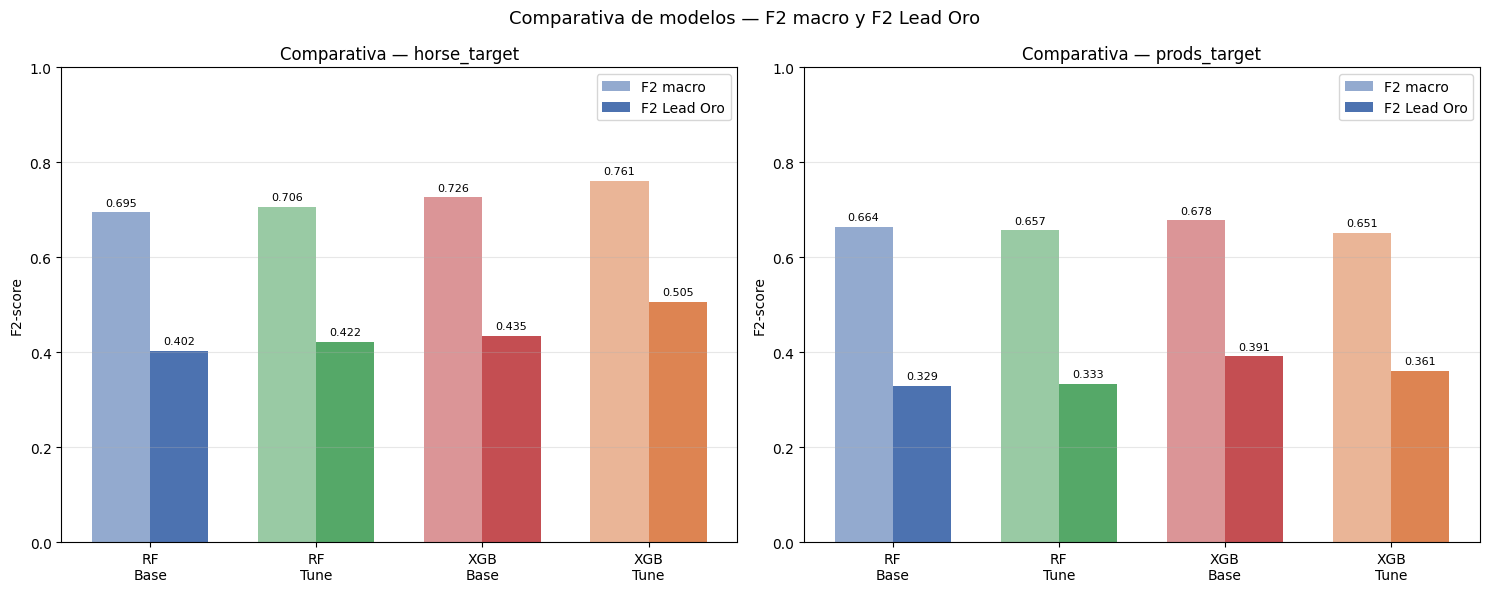

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
nombres_plot = ['RF\nBase', 'RF\nTune', 'XGB\nBase', 'XGB\nTune', 'XGB\nv2']
colores = ['#4C72B0', '#55A868', '#C44E52', '#DD8452', '#8B5E3C']

# Si aún no existe metricas_xgb_v2, usamos un placeholder
try:
    todos_plot = [
        ('RF  Baseline',  metricas_rf_base),
        ('RF  Tuneado',   metricas_rf_tune),
        ('XGB Baseline',  metricas_xgb_base),
        ('XGB Tuneado',   metricas_xgb_tune),
        ('XGB v2',        metricas_xgb_v2),
    ]
except NameError:
    todos_plot = [
        ('RF  Baseline',  metricas_rf_base),
        ('RF  Tuneado',   metricas_rf_tune),
        ('XGB Baseline',  metricas_xgb_base),
        ('XGB Tuneado',   metricas_xgb_tune),
    ]
    nombres_plot = nombres_plot[:-1]
    colores = colores[:-1]

for ax, target in zip(axes, ['horse', 'prods']):
    f2_macro = [r[target]['f2_macro']    for _, r in todos_plot]
    f2_oro   = [r[target]['f2_lead_oro'] for _, r in todos_plot]
    x = np.arange(len(nombres_plot))
    w = 0.35
    b1 = ax.bar(x - w/2, f2_macro, w, label='F2 macro',
                color=[c + '99' for c in colores])
    b2 = ax.bar(x + w/2, f2_oro,   w, label='F2 Lead Oro', color=colores)
    ax.set_xticks(x); ax.set_xticklabels(nombres_plot)
    ax.set_ylim(0, 1); ax.set_ylabel('F2-score')
    ax.set_title(f'Comparativa — {target}_target')
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    for bar in list(b1) + list(b2):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Comparativa de modelos — F2 macro y F2 Lead Oro', fontsize=13)
plt.tight_layout()
plt.show()


### 6 · Auditoría post-entrenamiento — Variables categóricas

Las variables categóricas encodadas con Target Encoding tienen **Cramér's V baja** (calculada en el EDA), pero eso solo mide el efecto **marginal** directo sobre el target. Un árbol de decisión puede capturar señal **condicional** (interacción con otras features) que la V de Cramér no detecta.

Por eso evaluamos la importancia real de cada categórica usando el **XGB Tuneado** (el mejor modelo entrenado hasta acá), y cruzamos esa evidencia con la Cramér's V calculada sobre el dataset original (antes del encoding).

Criterio de exclusión para la versión 2 (features reducidas):
- Si la importancia en **todos los 4 modelos** es `< 0.005` → ruido confirmado → agregar a `COLS_DROP_V2`
- Si la importancia es notable en al menos un modelo → conservar (señal condicional real)


In [88]:
# Nota: El resultado del EDA mostró que todas las categóricas tienen V < 0.15 con ambos targets.

# ── Feature importance del XGB Tuneado — solo las categóricas ─────────────────
print(f'  {"Variable":<30} {"P1-horse":>10} {"P1-prods":>10} {"P2-horse":>10} {"P2-prods":>10}  Decisión')
print('  ' + '─'*85)

UMBRAL_IMP = 0.005
cats_excluir = []

for var in COLS_TARGET_ENCODE:
    imps = {}
    for nombre_mod, modelo, X_ref in [
        ('p1h', xgb_tune_p1h, X_train_horse),
        ('p1p', xgb_tune_p1p, X_train_prods),
        ('p2h', xgb_tune_p2h, X_p2h_raw),
        ('p2p', xgb_tune_p2p, X_p2p_raw),
    ]:
        feat_dict = dict(zip(X_ref.columns, modelo.feature_importances_))
        imps[nombre_mod] = feat_dict.get(var, 0.0)

    max_imp  = max(imps.values())
    decision = 'EXCLUIR' if max_imp < UMBRAL_IMP else 'CONSERVAR'
    if decision == 'EXCLUIR':
        cats_excluir.append(var)
    flag = '  ◀ no aporta señal' if decision == 'EXCLUIR' else ''
    print(f'  {var:<30} {imps["p1h"]:>10.4f} {imps["p1p"]:>10.4f} '
          f'{imps["p2h"]:>10.4f} {imps["p2p"]:>10.4f}  {decision}{flag}')

print()
print(f'Categóricas a excluir en v2 (imp < {UMBRAL_IMP} en todos los modelos): {cats_excluir}')
print(f'Categóricas a conservar: {[v for v in COLS_TARGET_ENCODE if v not in cats_excluir]}')

# ── Actualizar COLS_DROP_V2 con las categóricas confirmadas como ruido ─────────
if cats_excluir:
    COLS_DROP_V2 = list(dict.fromkeys(COLS_DROP_V2 + cats_excluir))  # sin duplicados
    print(f'\nCOLS_DROP_V2 actualizado → {len(COLS_DROP_V2)} features a eliminar en v2')
else:
    print('\nNinguna categórica excluida — todas tienen señal condicional relevante.')


  Variable                         P1-horse   P1-prods   P2-horse   P2-prods  Decisión
  ─────────────────────────────────────────────────────────────────────────────────────
  user_region                        0.0042     0.0043     0.0155     0.0262  CONSERVAR
  user_card_issuer                   0.0040     0.0038     0.0147     0.0181  CONSERVAR
  user_domain                        0.0044     0.0042     0.0170     0.0247  CONSERVAR
  most_viewed_category               0.0000     0.0099     0.0000     0.0294  CONSERVAR
  most_viewed_brand                  0.0000     0.0072     0.0000     0.0255  CONSERVAR
  most_viewed_target_user            0.0000     0.0058     0.0000     0.0444  CONSERVAR

Categóricas a excluir en v2 (imp < 0.005 en todos los modelos): []
Categóricas a conservar: ['user_region', 'user_card_issuer', 'user_domain', 'most_viewed_category', 'most_viewed_brand', 'most_viewed_target_user']

Ninguna categórica excluida — todas tienen señal condicional relevante.


### 5.5 · XGB — versión 2 con features reducidas

Reentrenamos el **XGB Tuneado** (campeón actual) eliminando las features identificadas en `COLS_DROP_V2`: features de cero varianza, colineales redundantes, de baja señal numérica, y las categóricas que la auditoría de la sección anterior confirmó como ruido.

La reducción se aplica **por dominio**: `COLS_V2_HORSE` y `COLS_V2_PRODS` se calculan filtrando solo las columnas que existen en cada dataset, así que el conteo final puede diferir entre dominios.

**¿Qué esperamos?**
- **Precisión**: mejora marginal o neutral. XGBoost maneja colinealidad internamente, pero con menos ruido la generalización puede mejorar levemente.
- **Latencia**: reducción proporcional a la cantidad de features eliminadas. Con menos columnas, XGBoost recorre menos splits y el DataFrame de entrada es más angosto.

Usamos los mismos hiperparámetros del tuning anterior para una comparación justa (sin retuning).


In [89]:
import time

COLS_V2_HORSE = [c for c in X_train_horse.columns if c not in COLS_DROP_V2]
COLS_V2_PRODS = [c for c in X_train_prods.columns if c not in COLS_DROP_V2]

print(f'Features v2 — horse: {len(COLS_V2_HORSE)} (de {X_train_horse.shape[1]})')
print(f'Features v2 — prods: {len(COLS_V2_PRODS)} (de {X_train_prods.shape[1]})')
print(f'Features eliminadas: {len(COLS_DROP_V2)} (solo las que aplican en cada dominio)')

X_train_horse_v2 = X_train_horse[COLS_V2_HORSE]
X_test_horse_v2  = X_test_horse[COLS_V2_HORSE]
X_train_prods_v2 = X_train_prods[COLS_V2_PRODS]
X_test_prods_v2  = X_test_prods[COLS_V2_PRODS]
X_p2h_raw_v2     = X_p2h_raw[COLS_V2_HORSE]
X_p2p_raw_v2     = X_p2p_raw[COLS_V2_PRODS]

# ── Reentrenamos con los mismos hiperparámetros del campeón ────────────────
print('\nEntrenando XGB v2...')
xgb_v2_p1h = XGBClassifier(**params_xgb_p1h, scale_pos_weight=spw_p1h,
                             eval_metric='aucpr', tree_method='hist',
                             random_state=42, n_jobs=-1).fit(X_train_horse_v2, y_train_p1_horse)
xgb_v2_p1p = XGBClassifier(**params_xgb_p1p, scale_pos_weight=spw_p1p,
                             eval_metric='aucpr', tree_method='hist',
                             random_state=42, n_jobs=-1).fit(X_train_prods_v2, y_train_p1_prods)

X_p2h_smote_v2, y_p2h_smote_v2 = SMOTE(random_state=42).fit_resample(X_p2h_raw_v2, y_p2h_raw)
X_p2p_smote_v2, y_p2p_smote_v2 = SMOTE(random_state=42).fit_resample(X_p2p_raw_v2, y_p2p_raw)

xgb_v2_p2h = XGBClassifier(**params_xgb_p2h, scale_pos_weight=spw_p2h,
                             eval_metric='aucpr', tree_method='hist',
                             random_state=42, n_jobs=-1).fit(X_p2h_smote_v2, y_p2h_smote_v2)
xgb_v2_p2p = XGBClassifier(**params_xgb_p2p, scale_pos_weight=spw_p2p,
                             eval_metric='aucpr', tree_method='hist',
                             random_state=42, n_jobs=-1).fit(X_p2p_smote_v2, y_p2p_smote_v2)

metricas_xgb_v2 = calcular_metricas_cascada(
    xgb_v2_p1h, xgb_v2_p1p, xgb_v2_p2h, xgb_v2_p2p,
    X_te_horse=X_test_horse_v2, X_te_prods=X_test_prods_v2
)
print('Entrenamiento v2 completado.')

# ── Benchmark de latencia ──────────────────────────────────────────────────
N_BENCH = 1000

def benchmark_cascada(m1, m2, X, n=20):
    """Latencia media de inferencia en cascada (ms por batch de N_BENCH)."""
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        pred = np.array(['Lead Bronce'] * len(X), dtype=object)
        mask = m1.predict(X) == 1
        if mask.sum() > 0:
            pred[mask] = np.where(m2.predict(X[mask]) == 1, 'Lead Oro', 'Lead Plata')
        times.append((time.perf_counter() - t0) * 1000)
    return np.mean(times), np.std(times)

lat_v1_h = benchmark_cascada(xgb_tune_p1h, xgb_tune_p2h, X_test_horse.iloc[:N_BENCH])
lat_v1_p = benchmark_cascada(xgb_tune_p1p, xgb_tune_p2p, X_test_prods.iloc[:N_BENCH])
lat_v2_h = benchmark_cascada(xgb_v2_p1h,   xgb_v2_p2h,   X_test_horse_v2.iloc[:N_BENCH])
lat_v2_p = benchmark_cascada(xgb_v2_p1p,   xgb_v2_p2p,   X_test_prods_v2.iloc[:N_BENCH])

# ── Comparación completa ───────────────────────────────────────────────────
print('\n' + '='*75)
print('XGB TUNEADO v1 (features dominio) vs v2 (features dominio reducidas)')
print('='*75)
print(f'{"":30} {"F2 Oro horse":>13} {"F2 Oro prods":>13} {"Gap P2 horse":>13}')
print('-'*70)
for label, m in [('XGB Tuneado v1', metricas_xgb_tune),
                 ('XGB v2 reducido', metricas_xgb_v2)]:
    print(f'{label:<30} {m["horse"]["f2_lead_oro"]:>13.4f} '
          f'{m["prods"]["f2_lead_oro"]:>13.4f} '
          f'{m["horse"]["overfit_gap_p2"]:>13.4f}')

delta_h   = metricas_xgb_v2['horse']['f2_lead_oro'] - metricas_xgb_tune['horse']['f2_lead_oro']
delta_p   = metricas_xgb_v2['prods']['f2_lead_oro'] - metricas_xgb_tune['prods']['f2_lead_oro']
delta_gap = metricas_xgb_v2['horse']['overfit_gap_p2'] - metricas_xgb_tune['horse']['overfit_gap_p2']
print(f'{"Δ (v2 - v1)":<30} {delta_h:>+13.4f} {delta_p:>+13.4f} {delta_gap:>+13.4f}')

print('\n' + '-'*70)
print(f'LATENCIA — batch de {N_BENCH} predicciones (media 20 runs, ms)')
print('-'*70)
print(f'{"Modelo":<30} {"horse (ms)":>15} {"prods (ms)":>15}')
print(f'{"XGB Tuneado v1":<30} {lat_v1_h[0]:>12.2f}±{lat_v1_h[1]:.2f} {lat_v1_p[0]:>12.2f}±{lat_v1_p[1]:.2f}')
print(f'{"XGB v2 reducido":<30} {lat_v2_h[0]:>12.2f}±{lat_v2_h[1]:.2f} {lat_v2_p[0]:>12.2f}±{lat_v2_p[1]:.2f}')
lat_sp_h = (lat_v1_h[0] - lat_v2_h[0]) / lat_v1_h[0] * 100
lat_sp_p = (lat_v1_p[0] - lat_v2_p[0]) / lat_v1_p[0] * 100
print(f'  Reducción latencia: horse={lat_sp_h:+.1f}%  prods={lat_sp_p:+.1f}%')

# ── Decisión automática ────────────────────────────────────────────────────
THRESHOLD_DEGRADACION = -0.01  
if delta_h >= THRESHOLD_DEGRADACION:
    print(f'\n ✓ PROMOVER v2: Δ F2 Oro horse = {delta_h:+.4f} (≥ umbral {THRESHOLD_DEGRADACION})')
    print(f'   Latencia reducida: {lat_sp_h:.1f}% horse  |  {lat_sp_p:.1f}% prods')
    CAMPEON_V2 = True
else:
    print(f'\n ✗ MANTENER v1: Δ F2 Oro horse = {delta_h:+.4f} (< umbral {THRESHOLD_DEGRADACION})')
    CAMPEON_V2 = False


Features v2 — horse: 19 (de 27)
Features v2 — prods: 20 (de 22)
Features eliminadas: 20 (solo las que aplican en cada dominio)

Entrenando XGB v2...
Entrenamiento v2 completado.

XGB TUNEADO v1 (features dominio) vs v2 (features dominio reducidas)
                                F2 Oro horse  F2 Oro prods  Gap P2 horse
----------------------------------------------------------------------
XGB Tuneado v1                        0.5054        0.3605        0.0266
XGB v2 reducido                       0.4575        0.3589        0.0155
Δ (v2 - v1)                          -0.0478       -0.0017       -0.0112

----------------------------------------------------------------------
LATENCIA — batch de 1000 predicciones (media 20 runs, ms)
----------------------------------------------------------------------
Modelo                              horse (ms)      prods (ms)
XGB Tuneado v1                        17.08±1.98        12.89±1.44
XGB v2 reducido                       13.70±0.95        12

2026/03/04 12:57:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 12:57:51 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 12:57:56 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 12:58:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 12:58:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 12:58:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/04 12:58:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/04 12:59:09 WARNING mlflow.utils.

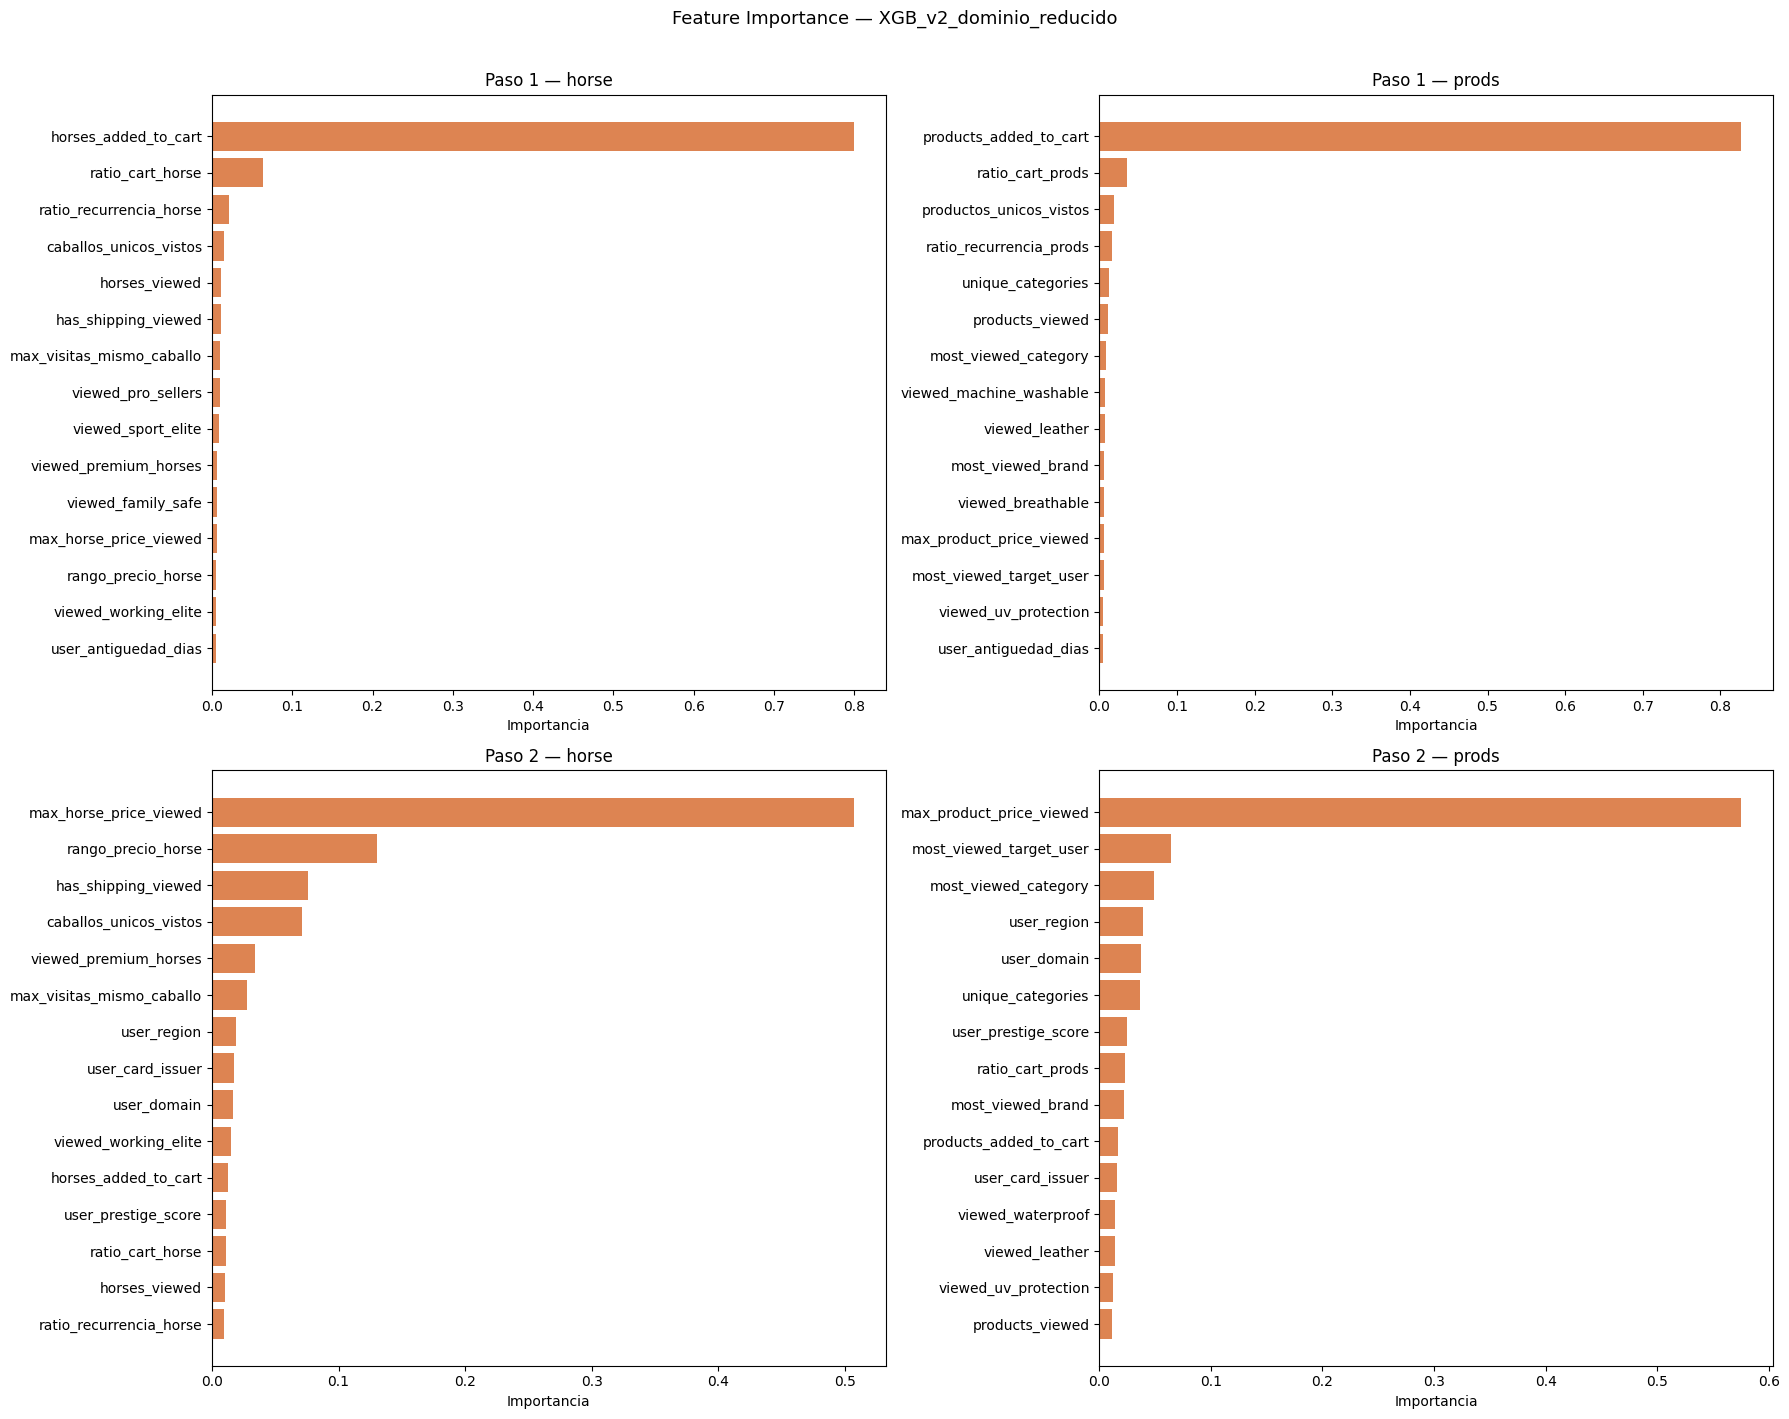

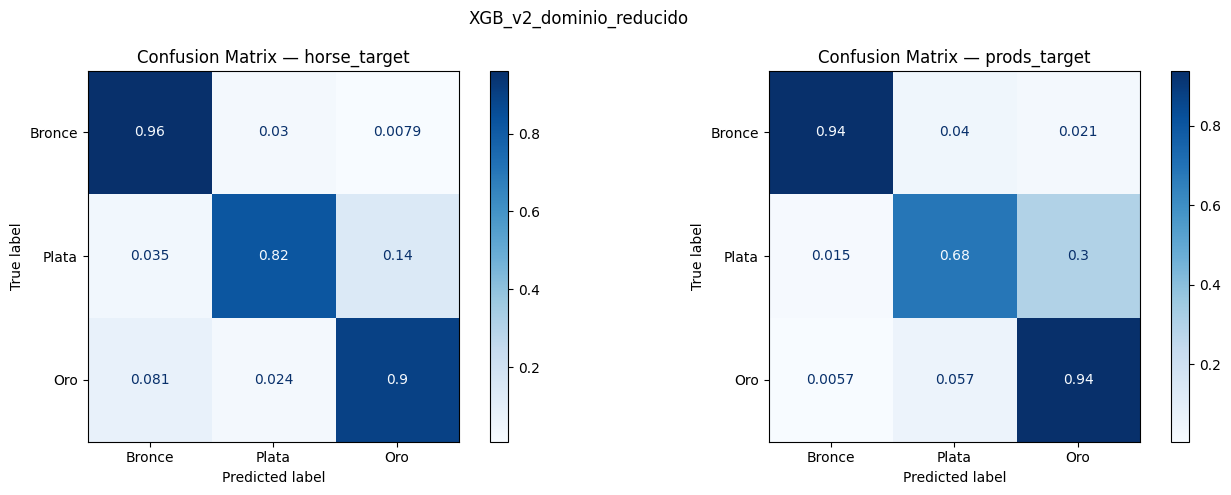

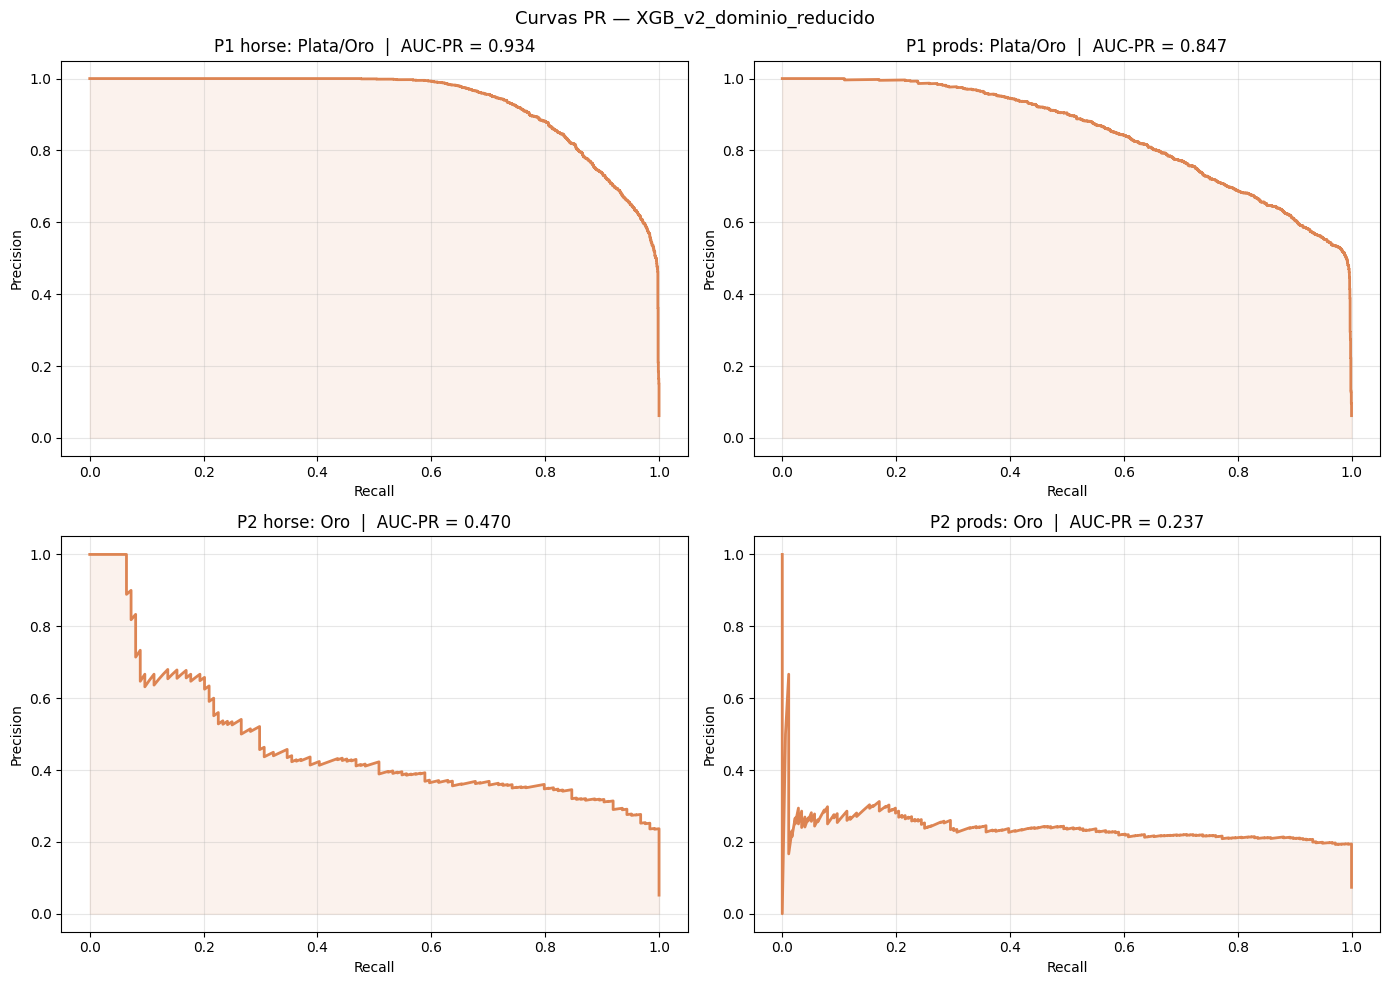

Run logueado: XGB_v2_dominio_reducido  |  run_id: a7c9ea2a237241c594fb929979e13c1c
🏃 View run XGB_v2_dominio_reducido at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4/runs/a7c9ea2a237241c594fb929979e13c1c
🧪 View experiment at: https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow/#/experiments/4

  Chequeo Overfitting — XGB v2 dominio reducido
─────────────────────────────────────────────────────────────────
  Paso                 F2 Train    F2 Test      Gap  Status
  ───────────────────────────────────────────────────────────────
  P1 — horse             0.9053     0.8692   0.0361  OK
  P1 — prods             0.8404     0.8342   0.0062  OK
  P2 — horse             0.6504     0.6349   0.0155  OK
  P2 — prods             0.5566     0.5386   0.0180  OK


In [92]:
run_id_xgb_v2 = loguear_run_mlflow(
    run_name    = 'XGB_v2_dominio_reducido',
    model_type  = 'XGBoost',
    params_p1   = {**params_xgb_p1h, 'scale_pos_weight': spw_p1h,
                   'n_feat_horse': len(COLS_V2_HORSE), 'n_feat_prods': len(COLS_V2_PRODS)},
    params_p2   = {**params_xgb_p2h, 'scale_pos_weight': spw_p2h},
    p1h=xgb_v2_p1h, p1p=xgb_v2_p1p,
    p2h=xgb_v2_p2h, p2p=xgb_v2_p2p,
    metricas    = metricas_xgb_v2,
    X_train_p1h = X_train_horse_v2,
    X_train_p1p = X_train_prods_v2,
    X_train_p2h = X_p2h_raw_v2,
    X_train_p2p = X_p2p_raw_v2,
    X_te_horse  = X_test_horse_v2,   # <-- evita mismatch de features con XGB v2
    X_te_prods  = X_test_prods_v2,
)

check_overfitting([
    ('P1 — horse', xgb_v2_p1h, X_train_horse_v2, y_train_p1_horse,
     X_test_horse_v2, y_test_p1_horse),
    ('P1 — prods', xgb_v2_p1p, X_train_prods_v2, y_train_p1_prods,
     X_test_prods_v2, y_test_p1_prods),
    ('P2 — horse', xgb_v2_p2h, X_p2h_raw_v2, y_p2h_raw,
     X_test_horse_v2[mask_test_p2_horse], y_test_p2_horse),
    ('P2 — prods', xgb_v2_p2p, X_p2p_raw_v2, y_p2p_raw,
     X_test_prods_v2[mask_test_p2_prods], y_test_p2_prods),
], 'XGB v2 dominio reducido')

### 6 · Selección del modelo campeón

Buscamos el run con mayor `f2_lead_oro_horse` en DagsHub, lo tageamos como `status=champion` y mostramos un resumen de sus métricas y params.

In [93]:
client = mlflow.tracking.MlflowClient()

# Experimento actual
exp = client.get_experiment_by_name(EXPERIMENT_NAME)
exp_id = exp.experiment_id

# Buscamos todos los runs del experimento
runs = client.search_runs(
    experiment_ids=[exp_id],
    filter_string='attributes.status = "FINISHED"',
    order_by=['metrics.f2_lead_oro_horse DESC'],
    max_results=10
)

if not runs:
    print('No hay runs finalizados en el experimento.')
else:
    mejor = runs[0]
    nombre = mejor.data.tags.get('mlflow.runName', mejor.info.run_id)

    # Quitamos tag champion de cualquier run anterior
    for run in runs:
        if run.data.tags.get('status') == 'champion':
            client.set_tag(run.info.run_id, 'status', 'retired')

    # Tageamos el nuevo campeón
    client.set_tag(mejor.info.run_id, 'status', 'champion')

    # Resumen
    m = mejor.data.metrics
    p = mejor.data.params

    print(f'{'═'*60}')
    print(f' CAMPEÓN: {nombre}')
    print(f'{'═'*60}')
    print(f'  run_id : {mejor.info.run_id}')
    print(f'  F2 Lead Oro  — horse : {m.get("f2_lead_oro_horse", "N/A"):.4f}')
    print(f'  F2 Lead Oro  — prods : {m.get("f2_lead_oro_prods", "N/A"):.4f}')
    print(f'  F2 macro     — horse : {m.get("f2_macro_horse", "N/A"):.4f}')
    print(f'  Gap P2       — horse : {m.get("overfit_gap_p2_horse", "N/A"):.4f}')
    print(f'{'─'*60}')
    print('  Params:')
    for k, v in sorted(p.items()):
        print(f'    {k:<30} {v}')
    print(f'{'─'*60}')
    print(f'  Ver en DagsHub:')
    print(f'  https://dagshub.com/aletbm/S02-26-E45-Data_Science_EquineLead.mlflow'
          f'/#/experiments/{exp_id}/runs/{mejor.info.run_id}')

    # Tabla comparativa de todos los runs
    print(f'\n  Ranking completo (por F2 Lead Oro horse):')
    print(f'  {"Run":<16} {"F2 Oro horse":>13} {"F2 Oro prods":>13} {"Gap P2":>8}  Status')
    print(f'  {"─"*60}')
    for r in runs:
        rname  = r.data.tags.get('mlflow.runName', r.info.run_id[:8])
        f2h    = r.data.metrics.get('f2_lead_oro_horse', float('nan'))
        f2p    = r.data.metrics.get('f2_lead_oro_prods', float('nan'))
        gap    = r.data.metrics.get('overfit_gap_p2_horse', float('nan'))
        status = r.data.tags.get('status', '')
        print(f'  {rname:<14} {f2h:>13.4f} {f2p:>13.4f} {gap:>8.4f}  {status}')

════════════════════════════════════════════════════════════
 CAMPEÓN: XGB_Tuneado
════════════════════════════════════════════════════════════
  run_id : dd6f2989958a48d587e2769933622ff8
  F2 Lead Oro  — horse : 0.5054
  F2 Lead Oro  — prods : 0.3605
  F2 macro     — horse : 0.7614
  Gap P2       — horse : 0.0266
────────────────────────────────────────────────────────────
  Params:
    p1_colsample_bytree            0.9
    p1_learning_rate               0.1
    p1_max_depth                   5
    p1_n_estimators                400
    p1_reg_alpha                   0.1
    p1_reg_lambda                  1.0
    p1_scale_pos_weight            15.164263322884013
    p1_subsample                   0.7
    p2_colsample_bytree            0.7
    p2_learning_rate               0.1
    p2_max_depth                   3
    p2_n_estimators                200
    p2_reg_alpha                   1.0
    p2_reg_lambda                  5.0
    p2_scale_pos_weight            18.294354838709676
  

### 7 · Guardado local del modelo campeón

Además del registro en DagsHub, guardamos los **4 modelos** del campeón más los artefactos
de preprocesamiento en disco como `.pkl`. Esto es el respaldo local por si DagsHub no está disponible
y lo que la API va a levantar al iniciar.

In [95]:
import pickle, os

try:
    _es_v2 = CAMPEON_V2
except NameError:
    _es_v2 = False

if _es_v2:
    _p1h, _p1p = xgb_v2_p1h,   xgb_v2_p1p
    _p2h, _p2p = xgb_v2_p2h,   xgb_v2_p2p
    _label     = 'XGB_v2_dominio_reducido'
    _outdir    = '../models/champion_v2'
    _cols_h    = COLS_V2_HORSE
    _cols_p    = COLS_V2_PRODS
else:
    _p1h, _p1p = xgb_tune_p1h, xgb_tune_p1p
    _p2h, _p2p = xgb_tune_p2h, xgb_tune_p2p
    _label     = 'XGB_Tuneado'
    _outdir    = '../models/champion'
    _cols_h    = list(X_train_horse.columns)
    _cols_p    = list(X_train_prods.columns)

os.makedirs(_outdir, exist_ok=True)

for nombre, modelo in [
    ('modelo_p1_horse', _p1h), ('modelo_p1_prods', _p1p),
    ('modelo_p2_horse', _p2h), ('modelo_p2_prods', _p2p),
]:
    path = os.path.join(_outdir, f'{nombre}.pkl')
    with open(path, 'wb') as f:
        pickle.dump(modelo, f)
    print(f'  OK {path}')

# ── Artefactos de preprocesamiento ────────────────────────────────────────────
with open(os.path.join(_outdir, 'target_encoder.pkl'), 'wb') as f:
    pickle.dump(te, f)
with open(os.path.join(_outdir, 'limites_capping.pkl'), 'wb') as f:
    pickle.dump(limites_capping, f)
print(f'  OK target_encoder.pkl  OK limites_capping.pkl')

# ── Listas de features por dominio  ──────
with open(os.path.join(_outdir, 'cols_horse.pkl'), 'wb') as f:
    pickle.dump(_cols_h, f)
with open(os.path.join(_outdir, 'cols_prods.pkl'), 'wb') as f:
    pickle.dump(_cols_p, f)
print(f'  OK cols_horse.pkl  ({len(_cols_h)} features)')
print(f'  OK cols_prods.pkl  ({len(_cols_p)} features)')

# También guardamos las definiciones de dominio para referencia
with open(os.path.join(_outdir, 'cols_user.pkl'), 'wb') as f:
    pickle.dump(COLS_USER, f)

print(f'\n  Campeón [{_label}] → {_outdir}/')
print(f'  La API carga cols_horse.pkl y cols_prods.pkl para filtrar el vector de features')
print(f'  antes de pasarlo al modelo correspondiente.')


  OK ../models/champion/modelo_p1_horse.pkl
  OK ../models/champion/modelo_p1_prods.pkl
  OK ../models/champion/modelo_p2_horse.pkl
  OK ../models/champion/modelo_p2_prods.pkl
  OK target_encoder.pkl  OK limites_capping.pkl
  OK cols_horse.pkl  (27 features)
  OK cols_prods.pkl  (22 features)

  Campeón [XGB_Tuneado] → ../models/champion/
  La API carga cols_horse.pkl y cols_prods.pkl para filtrar el vector de features
  antes de pasarlo al modelo correspondiente.
